<div style="font-size:12px !important;line-height:1.4 !important;">
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Market ML Analysis — Shared Pipeline: Lasso + XGBoost</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Goal:</b> One training-data pipeline feeding two models:</p>
<ol style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Lasso regression</b> — predicted return over the active horizon</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>XGBoost classifier</b> — will the <b>horizon</b> session close above the previous session?</li>
</ol>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Prediction horizon (clock-aware, America/Chicago)</b></p>
<table style="font-size:12px;border-collapse:collapse;margin:0.35em 0;">
<tr><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Now (CST)</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Horizon</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Question</th></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>Before 3:00 PM</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>Current day</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Will <i>today</i> close above the previous session close?</td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>3:00 PM or later</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>Next day</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Will the <i>next</i> session close above the latest session close?</td></tr>
</table>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Same model formula either way: features from last completed session <code style="font-size:11px;">t</code> → predict whether close of the target session is above close of <code style="font-size:11px;">t</code>.</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Single Dataset Pipeline</b></p>
<pre style="font-size:11px;line-height:1.35;margin:0.35em 0;padding:6px 8px;overflow:auto;white-space:pre-wrap;"><code style="font-size:11px;">1. LOAD OHLCV from START−PRE_START_DAYS; compute features; keep rows ≥ START
2. BUILD TRAINING FRAME (X + y_reg + y_cls; labels = next session vs session t)
3. WALK-FORWARD expanding train for Lasso + XGBoost
4. EVALUATE OOS
5. LIVE PREDICTION using CST clock → current vs next day
6. PERSIST</code></pre>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Kernel:</b> <code style="font-size:11px;">.venv</code> / <b>Python (ml_analysis)</b></p>

<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Repo layout</b></p>
<ul style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.15em 0;"><code style="font-size:11px;">market_ml_analysis.ipynb</code> — <b>only</b> script: one stock per run, feature ideation/testing, thr calibration, prediction</li>
<li style="font-size:12px;line-height:1.4;margin:0.15em 0;"><code style="font-size:11px;">data/</code> — OHLCV downloads/caches (<code style="font-size:11px;">cache_ohlcv_{TICKER}.parquet</code>)</li>
<li style="font-size:12px;line-height:1.4;margin:0.15em 0;"><code style="font-size:11px;">improves_{TICKER}_{DATE}/</code> — that run’s charts, entry rule, buy decision (DATE = target session)</li>
</ul>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>New ticker:</b> set <code style="font-size:11px;">TICKER</code>, validation/target dates → full top-to-bottom → read thr in <code style="font-size:11px;">entry_rule_80_*.json</code>.</p>
</div>


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 0: Setup</b></p>
</div>


In [98]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Layout
#   data/                         — OHLCV downloads / parquet caches (any ticker)
#   improves_{TICKER}_{YYYY-MM-DD}/ — one run's charts, thr, decisions
# This notebook is the only script: single stock, feature ideation, thr pick, predict.
REPO_ROOT = Path(".").resolve()
DATA_DIR = REPO_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)

# Bollinger Band defaults (chart actuals + bb_dist_lower)
BB_WINDOW = 14
BB_K = 1.5

# Config — change TICKER + dates, run top→bottom (features → calibrate thr → predict)
TICKER = "VRT"

# Analysis window (inclusive). Features are computed with warm-up history before this.
START = (pd.Timestamp.today().normalize() - pd.DateOffset(years=1)).strftime("%Y-%m-%d")
END = None  # None = through latest available

# Lean feature set: stretch, volume, lower BB, vol ratio, near high
FEAT_RSI_SESSIONS = 14            # Wilder RSI period
FEAT_OBV_Z_SESSIONS = 20          # rolling z-score window on OBV changes
FEAT_BB_SESSIONS = BB_WINDOW      # Bollinger lookback (ties BB_WINDOW)
FEAT_VOL_RATIO_SHORT = 7          # short GK window (fast expansion)
FEAT_VOL_RATIO_LONG = 21          # long GK baseline (vol_ratio = GK_short / GK_long)
FEAT_NEAR_HIGH_SESSIONS = 200     # nearness to N-session peak high

FEATURE_MAX_SESSIONS = max(
    FEAT_RSI_SESSIONS + 1,
    FEAT_OBV_Z_SESSIONS + 1,
    FEAT_BB_SESSIONS,
    FEAT_VOL_RATIO_LONG,
    FEAT_NEAR_HIGH_SESSIONS,
)

# Calendar days of OHLCV *before* START so the first analysis session can fill
# FEATURE_MAX_SESSIONS-long rolling features (no imputation if still short).
#
# Trading sessions ≠ calendar days. Long-run NYSE density ≈ 252 sessions / 365.25 days.
# PRE_START_DAYS = ceil( (FEATURE_MAX_SESSIONS + SESSION_PAD) × 365.25 / 252 )
# SESSION_PAD: few extra trading sessions for Yahoo lag / calendar quirks (not a 400-day floor).
NYSE_SESSIONS_PER_YEAR = 252.0
CAL_DAYS_PER_YEAR = 365.25
PRE_START_SESSION_PAD = 5  # extra *trading* sessions of cushion, then convert to calendar


def pre_start_calendar_days(feature_max_sessions: int, session_pad: int = PRE_START_SESSION_PAD) -> int:
    """Convert max feature lookback (trading sessions) → calendar-day fetch cushion."""
    need_sessions = int(feature_max_sessions) + int(session_pad)
    return int(np.ceil(need_sessions * CAL_DAYS_PER_YEAR / NYSE_SESSIONS_PER_YEAR))


PRE_START_DAYS = pre_start_calendar_days(FEATURE_MAX_SESSIONS)

# Live prediction horizon (America/Chicago)
from datetime import datetime, time
from zoneinfo import ZoneInfo

TZ = ZoneInfo("America/Chicago")
PRED_CUTOFF = time(15, 0)  # before 3pm CST → score *current* session; else *next* session


def resolve_prediction_horizon(now: datetime | None = None) -> tuple[str, datetime]:
    """Return ('current_day'|'next_day', now_in_CST)."""
    now = now or datetime.now(TZ)
    if now.tzinfo is None:
        now = now.replace(tzinfo=TZ)
    else:
        now = now.astimezone(TZ)
    horizon = "current_day" if now.time() < PRED_CUTOFF else "next_day"
    return horizon, now


def resolve_predict_target_date(now: datetime | None = None) -> tuple[str, str, datetime]:
    """Auto target session from CST clock (no hardcode).

    Before 15:00 America/Chicago on a weekday → that session (current_day).
    At/after 15:00 → next business session (next_day).
    Weekends / if "today" is not a weekday → next BDay.
    """
    horizon, now = resolve_prediction_horizon(now)
    d = pd.Timestamp(now.date())
    if horizon == "current_day":
        if d.dayofweek >= 5:  # Sat/Sun → next trading session
            target = d + pd.offsets.BDay(1)
            horizon = "next_day"
        else:
            target = d
    else:
        # after cutoff: next session after today's calendar day
        target = d + pd.offsets.BDay(1)
    return target.strftime("%Y-%m-%d"), horizon, now


# Scoring / live target for this run (auto from clock)
VAL_WINDOW_SESSIONS = 30          # last N labeled sessions for walk-forward validation
PREDICT_TARGET_DATE, LIVE_HORIZON, _NOW_CST = resolve_predict_target_date()
# Hand-check board date: previous business day before the target session
FEATURE_VALIDATE_DATE = (
    pd.Timestamp(PREDICT_TARGET_DATE) - pd.offsets.BDay(1)
).strftime("%Y-%m-%d")

# Run folder: improves_{TICKER}_{DATE} (DATE = scored session)
RUN_DATE = str(PREDICT_TARGET_DATE)
OUTPUT_DIR = REPO_ROOT / f"improves_{TICKER}_{RUN_DATE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Buy rule (next-session close > feature-session close)
# Operating long entry: oriented entry score (see Step 6b auto-invert if needed)
# BUY_ENTRY_THR_MODE: composite = auto thr; manual = pin BUY_ENTRY_SCORE_MIN
# composite score = W_PREC * rank_pct(buy-in precision) + W_GAIN * rank_pct(gain captured)
# among thr with n_buys ≥ MIN_TRADES. Higher W_PREC tilts to accuracy over gain capture.
BUY_ENTRY_THR_MODE = "composite"
BUY_ENTRY_COMPOSITE_W_PREC = 2.0   # weight on buy-in accuracy (was equal 1.0)
BUY_ENTRY_COMPOSITE_W_GAIN = 1.0   # weight on % gain captured
BUY_ENTRY_SCORE_MIN = 0.72       # used when mode=manual; set by scan when mode=composite
BUY_XGB_PROB_MIN = BUY_ENTRY_SCORE_MIN  # alias for legacy plots
BUY_REQUIRE_LASSO_UP = False     # if True, also need Lasso pred_logret > 0
BUY_SIZE = 1.0                   # unit shares/notional weight when buy fires

# Walk-forward: train on all history after 11-month burn-in; advance one day at a time
MIN_TRAIN_MONTHS = 11
RANDOM_STATE = 42

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

START_TS = pd.Timestamp(START)
FETCH_START = (START_TS - pd.Timedelta(days=PRE_START_DAYS)).strftime("%Y-%m-%d")

print("Setup complete")
print(f"DATA_DIR={DATA_DIR}")
print(f"OUTPUT_DIR={OUTPUT_DIR}")
print(f"Ticker={TICKER}")
print(
    f"Analysis START={START}  END={END}  "
    f"PRE_START_DAYS={PRE_START_DAYS}  fetch_from={FETCH_START}"
)
print(
    f"  PRE_START calc: ceil((FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS} + "
    f"pad={PRE_START_SESSION_PAD}) × {CAL_DAYS_PER_YEAR}/{NYSE_SESSIONS_PER_YEAR:g}) "
    f"= {PRE_START_DAYS} calendar days  "
    f"(≈{(FEATURE_MAX_SESSIONS + PRE_START_SESSION_PAD) * CAL_DAYS_PER_YEAR / NYSE_SESSIONS_PER_YEAR:.2f} raw)"
)
print(f"FEATURE_VALIDATE_DATE={FEATURE_VALIDATE_DATE}  FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS}")
print(
    f"VAL_WINDOW_SESSIONS={VAL_WINDOW_SESSIONS}  PREDICT_TARGET_DATE={PREDICT_TARGET_DATE}  "
    f"(auto, horizon={LIVE_HORIZON})"
)
print(f"BUY_ENTRY_THR_MODE={BUY_ENTRY_THR_MODE}  W_prec={BUY_ENTRY_COMPOSITE_W_PREC} W_gain={BUY_ENTRY_COMPOSITE_W_GAIN}  BUY_ENTRY_SCORE_MIN={BUY_ENTRY_SCORE_MIN}  BUY_REQUIRE_LASSO_UP={BUY_REQUIRE_LASSO_UP}")
print(f"MIN_TRAIN_MONTHS={MIN_TRAIN_MONTHS}")
print(
    "Features: rsi_14, obv_chg_z_20, bb_dist_lower, "
    f"vol_ratio_{FEAT_VOL_RATIO_SHORT}_{FEAT_VOL_RATIO_LONG}, near_high_{FEAT_NEAR_HIGH_SESSIONS}"
)
print(
    f"Clock CST={_NOW_CST.strftime('%Y-%m-%d %H:%M %Z')}  "
    f"cutoff={PRED_CUTOFF.strftime('%H:%M')}  live_horizon={LIVE_HORIZON}"
)


Setup complete
DATA_DIR=/Users/matthewpappas/code/ml_analysis/data
OUTPUT_DIR=/Users/matthewpappas/code/ml_analysis/improves_VRT_2026-08-12
Ticker=VRT
Analysis START=2025-08-11  END=None  PRE_START_DAYS=298  fetch_from=2024-10-17
  PRE_START calc: ceil((FEATURE_MAX_SESSIONS=200 + pad=5) × 365.25/252) = 298 calendar days  (≈297.13 raw)
FEATURE_VALIDATE_DATE=2026-08-11  FEATURE_MAX_SESSIONS=200
VAL_WINDOW_SESSIONS=30  PREDICT_TARGET_DATE=2026-08-12  (auto, horizon=next_day)
BUY_ENTRY_THR_MODE=composite  W_prec=2.0 W_gain=1.0  BUY_ENTRY_SCORE_MIN=0.72  BUY_REQUIRE_LASSO_UP=False
MIN_TRAIN_MONTHS=11
Features: rsi_14, obv_chg_z_20, bb_dist_lower, vol_ratio_7_21, near_high_200
Clock CST=2026-08-11 17:35 CDT  cutoff=15:00  live_horizon=next_day


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 1: Load Daily OHLCV</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>OHLC(V)</b> = one trading session bar:</p>
<table style="font-size:12px;border-collapse:collapse;margin:0.35em 0;">
<tr><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Letter</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Column</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Definition</th></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>O</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><code style="font-size:11px;">Open</code></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">First trade price of the session</td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>H</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><code style="font-size:11px;">High</code></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Highest trade price of the session</td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>L</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><code style="font-size:11px;">Low</code></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Lowest trade price of the session</td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>C</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><code style="font-size:11px;">Close</code></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Last trade price of the session (official close)</td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>V</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><code style="font-size:11px;">Volume</code></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Shares traded during the session</td></tr>
</table>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Warm-up buffer (no missing lag windows on day 1)</b></p>
<ol style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">Pull OHLCV from <b><code style="font-size:11px;">START − PRE_START_DAYS</code></b> through <code style="font-size:11px;">END</code> (yfinance <code style="font-size:11px;">auto_adjust=True</code>).</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">Compute movement / window features on that full history.</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Drop rows before <code style="font-size:11px;">START</code></b> — every kept row has a prior close and full lookbacks.</li>
</ol>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Do <b>not</b> drop “the first analysis day”; pull extra history instead.</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Incomplete session rule:</b> before 3:00 PM America/Chicago, drop bars dated <b>today</b>.</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Charts:</b> after features, Step 2b <code style="font-size:11px;">plot_00_candles_feature_health()</code> (candles + feature health). Then <code style="font-size:11px;">plot_01_</code> / <code style="font-size:11px;">plot_02_</code> / <code style="font-size:11px;">plot_03_</code>.</p>
</div>


In [99]:
# OHLC(V) bar definitions (one row = one trading session)
#   O  Open   = first traded price of the session
#   H  High   = highest traded price of the session
#   L  Low    = lowest traded price of the session
#   C  Close  = last traded price of the session (official session close)
#   V  Volume = number of shares traded during the session
#
# Prices use yfinance auto_adjust=True (library handles splits + dividends).
#
def load_ohlcv(ticker: str, start: str, end: str | None = None) -> tuple[pd.DataFrame, str]:
    """Daily bars from yfinance with auto_adjust=True. No synthetic fallback."""
    import yfinance as yf

    raw = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=True,
        progress=False,
    )
    if raw is None or raw.empty:
        raise RuntimeError(
            f"yfinance returned no rows for ticker={ticker!r} start={start!r} end={end!r}."
        )

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    required = ["Open", "High", "Low", "Close", "Volume"]
    missing = [c for c in required if c not in raw.columns]
    if missing:
        raise RuntimeError(f"yfinance missing required OHLC columns {missing} for {ticker!r}")

    df = raw[required].copy()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df = df.dropna(subset=["Close"]).sort_index()
    if df.empty:
        raise RuntimeError(f"All rows dropped after cleaning Close for {ticker!r}")
    return df, f"yfinance:{ticker}"


def drop_incomplete_session(df: pd.DataFrame, now: datetime | None = None) -> pd.DataFrame:
    """Before 3pm CST drop any bar dated today (incomplete close)."""
    horizon, now_cst = resolve_prediction_horizon(now)
    if horizon != "current_day":
        return df.sort_index()

    today = now_cst.date()
    mask = np.array([ts.date() < today for ts in df.index])
    dropped = int((~mask).sum())
    out = df.loc[mask].sort_index()
    if dropped:
        print(
            f"Dropped {dropped} incomplete session row(s) for {today} "
            f"(before {PRED_CUTOFF.strftime('%H:%M')} CST)."
        )
    if out.empty:
        raise RuntimeError("No OHLCV rows left after dropping incomplete session.")
    return out


def add_session_move_features(df: pd.DataFrame) -> pd.DataFrame:
    """Prior-close features. Requires chronological order + enough history above START."""
    out = df.sort_index(ascending=True).copy()
    prior_close = out["Close"].shift(1)
    out["pct_change"] = out["Close"] / prior_close - 1.0
    out["chg_from_prior_close"] = out["Close"] - prior_close
    out["up_from_prior"] = (out["Close"] > prior_close).astype("Int64")
    return out


def trim_to_analysis_window(df: pd.DataFrame, start_ts: pd.Timestamp) -> pd.DataFrame:
    """Keep rows on/after START after features were computed on the pre-start buffer."""
    out = df.loc[df.index >= start_ts].copy()
    if out.empty:
        raise RuntimeError(f"No rows on/after analysis START={start_ts.date()}")
    return out


# 1) fetch with warm-up history before START
print(f"Fetching {TICKER} from {FETCH_START} (START={START} − {PRE_START_DAYS}d) through END={END}")
ohlcv_hist, data_source = load_ohlcv(TICKER, FETCH_START, END)
ohlcv_hist = drop_incomplete_session(ohlcv_hist)

# 2) movement features on full history (buffer + analysis)
ohlcv_hist = add_session_move_features(ohlcv_hist)

n_hist = len(ohlcv_hist)
n_buffer = int((ohlcv_hist.index < START_TS).sum())

# 3) analysis frame: drop pre-START warm-up only (do not drop first post-START row)
ohlcv = trim_to_analysis_window(ohlcv_hist, START_TS)
ohlcv["up_from_prior"] = ohlcv["up_from_prior"].astype(int)

missing_move = ohlcv[["pct_change", "chg_from_prior_close", "up_from_prior"]].isna().any(axis=1).sum()
if missing_move:
    raise RuntimeError(
        f"{missing_move} analysis rows still missing prior-close features. "
        f"Increase PRE_START_DAYS (currently {PRE_START_DAYS}); "
        f"buffer had {n_buffer} sessions before START."
    )

ohlcv.to_parquet(DATA_DIR / f"cache_ohlcv_{TICKER}.parquet")
ohlcv_hist.to_parquet(DATA_DIR / f"cache_ohlcv_hist_{TICKER}.parquet")

# Working frame for feature engineering (full history including pre-START warm-up)
bars = ohlcv_hist.copy()

print(f"Source:       {data_source}  (auto_adjust=True)")
print(f"History rows: {n_hist:,}  ({ohlcv_hist.index.min().date()} → {ohlcv_hist.index.max().date()})")
print(f"Buffer rows:  {n_buffer:,}  (before START, used only for windows)")
print(f"Analysis:     {len(ohlcv):,} rows  {ohlcv.index.min().date()} → {ohlcv.index.max().date()}")
# Feature lookback honesty: rolling windows need FEATURE_MAX_SESSIONS *trading* sessions.
# Short IPO / limited Yahoo history → first post-START sessions will be incomplete → dropped later (no impute).
if n_buffer < FEATURE_MAX_SESSIONS:
    print(
        f"⚠ LOOKBACK SHORT: buffer={n_buffer} sessions < FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS}. "
        f"Expect incomplete features for the first ~{FEATURE_MAX_SESSIONS - n_buffer} analysis sessions; "
        f"those rows are DROPPED later at assemble (no imputation)."
    )
else:
    print(
        f"Buffer OK for max feature window: {n_buffer} sessions ≥ FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS}."
    )
print(f"Columns:      {list(ohlcv.columns)}")
print("Newest first:")
display(
    ohlcv.sort_index(ascending=False)[
        ["Open", "High", "Low", "Close", "Volume", "pct_change", "chg_from_prior_close", "up_from_prior"]
    ].head(10)
)


Fetching VRT from 2024-10-17 (START=2025-08-11 − 298d) through END=None
Source:       yfinance:VRT  (auto_adjust=True)
History rows: 454  (2024-10-17 → 2026-08-11)
Buffer rows:  202  (before START, used only for windows)
Analysis:     252 rows  2025-08-11 → 2026-08-11
Buffer OK for max feature window: 202 sessions ≥ FEATURE_MAX_SESSIONS=200.
Columns:      ['Open', 'High', 'Low', 'Close', 'Volume', 'pct_change', 'chg_from_prior_close', 'up_from_prior']
Newest first:


Price,Open,High,Low,Close,Volume,pct_change,chg_from_prior_close,up_from_prior
Date,,,,,,,,
2026-08-11,275.500000,284.679993,274.000000,281.809998,3677051,0.043354,11.709991,1
2026-08-10,277.279999,278.679993,267.519989,270.100006,2859500,-0.008443,-2.299988,0
2026-08-07,284.920013,285.903992,269.190002,272.399994,3909500,-0.010067,-2.770020,0
2026-08-06,271.130005,286.359985,270.062988,275.170013,5084700,-0.009966,-2.769989,0
2026-08-05,270.450012,282.500000,270.000000,277.940002,5933200,0.029674,8.010010,1
2026-08-04,275.209991,276.519989,268.119995,269.929993,5802700,0.026155,6.880005,1
2026-08-03,236.979996,264.140015,234.960007,263.049988,9517100,0.088918,21.479980,1
2026-07-31,246.869995,251.709000,233.169998,241.570007,10849600,0.061846,14.070007,1
2026-07-30,237.199997,241.320007,224.600006,227.500000,14508000,0.019996,4.460007,1


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 2: Predictive Features (validated before modeling)</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Lean set (5 features): RSI, OBV z, lower BB, vol ratio, near 200d high. Dropped CLV / near_low_252. Also dropped: <code style="font-size:11px;">log_ret_1d</code>, <code style="font-size:11px;">gk_vol_21</code> (level), <code style="font-size:11px;">ema_spread_5_20</code>, <code style="font-size:11px;">bb_dist_upper</code>.</p>
<ul style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.15em 0;"><b>Lasso</b> — continuous next-session return (linear, sparse)</li>
<li style="font-size:12px;line-height:1.4;margin:0.15em 0;"><b>XGBoost</b> — binary next-session up/down</li>
</ul>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Temporal rules</b></p>
<table style="font-size:12px;border-collapse:collapse;margin:0.35em 0;">
<tr><th style="font-size:12px;line-height:1.4;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Rule</th><th style="font-size:12px;line-height:1.4;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Implementation</th></tr>
<tr><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">No leakage</td><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">Features on day <i>t</i> use OHLC/V <b>up through close of t</b> only</td></tr>
<tr><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">Target</td><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">Next-session: y<sup>reg</sup>=ln(C<sub>t+1</sub>/C<sub>t</sub>), y<sup>cls</sup>=1{C<sub>t+1</sub>&gt;C<sub>t</sub>}</td></tr>
<tr><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">Warm-up</td><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">Fetch START − PRE_START_DAYS, compute on full history, drop rows &lt; START</td></tr>
<tr><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;">Hand-check date</td><td style="font-size:12px;line-height:1.4;padding:2px 6px;border:1px solid #555;vertical-align:top;"><code style="font-size:11px;">FEATURE_VALIDATE_DATE</code> — each feature recomputed independently</td></tr>
</table>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Feature inventory &amp; sessions before START</b></p>
<table style="font-size:12px;border-collapse:collapse;margin:0.35em 0;">
<tr><th style="font-size:12px;padding:2px 6px;border:1px solid #555;text-align:left;">#</th><th style="font-size:12px;padding:2px 6px;border:1px solid #555;text-align:left;">Feature</th><th style="font-size:12px;padding:2px 6px;border:1px solid #555;text-align:left;">Signal</th><th style="font-size:12px;padding:2px 6px;border:1px solid #555;text-align:left;">Sessions before START</th></tr>
<tr><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">1</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">RSI 14</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">stretch / oscillator</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;"><b>15</b> (<code style="font-size:11px;">FEAT_RSI_SESSIONS+1</code>)</td></tr>
<tr><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">2</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">OBV Δ z-score 20</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">volume impulse</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;"><b>21</b> (<code style="font-size:11px;">FEAT_OBV_Z_SESSIONS+1</code>)</td></tr>
<tr><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">3</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">BB dist lower</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">lower-band location</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;"><b>14</b> (<code style="font-size:11px;">FEAT_BB_SESSIONS</code>)</td></tr>
<tr><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">4</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">GK vol ratio 7/21</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;">fast vol expansion</td><td style="font-size:12px;padding:2px 6px;border:1px solid #555;"><b>21</b> (<code style="font-size:11px;">FEAT_VOL_RATIO_LONG</code>)</td></tr>
</table>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><code style="font-size:11px;">PRE_START_DAYS</code> must cover <b><code style="font-size:11px;">FEATURE_MAX_SESSIONS</code></b> trading sessions.</p>
</div>


In [100]:
# =============================================================================
# Feature registry
# Registry name: FEATURE_SPECS → FEATURE_COLS
# Definition: Dict list of {name, sessions_before_start, title}; FEATURE_COLS is the model X column order
# Buffer: FEATURE_MAX_SESSIONS = max(sessions_before_start)
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
FEATURE_VALIDATE_TS = pd.Timestamp(FEATURE_VALIDATE_DATE)

_VOL_RATIO_NAME = f"vol_ratio_{FEAT_VOL_RATIO_SHORT}_{FEAT_VOL_RATIO_LONG}"

FEATURE_SPECS = [
    {
        "name": "rsi_14",
        "sessions_before_start": FEAT_RSI_SESSIONS + 1,
        "title": "RSI (Wilder 14)",
    },
    {
        "name": "obv_chg_z_20",
        "sessions_before_start": FEAT_OBV_Z_SESSIONS + 1,
        "title": "OBV change z-score (20)",
    },
    {
        "name": "bb_dist_lower",
        "sessions_before_start": FEAT_BB_SESSIONS,
        "title": f"Dist to lower BB ({BB_WINDOW}, k={BB_K:g})",
    },
    {
        "name": _VOL_RATIO_NAME,
        "sessions_before_start": FEAT_VOL_RATIO_LONG,
        "title": f"GK vol ratio {FEAT_VOL_RATIO_SHORT}/{FEAT_VOL_RATIO_LONG}",
    },
    {
        "name": f"near_high_{FEAT_NEAR_HIGH_SESSIONS}",
        "sessions_before_start": FEAT_NEAR_HIGH_SESSIONS,
        "title": f"Nearness to {FEAT_NEAR_HIGH_SESSIONS}d high (Close / peak High)",
    },
]
FEATURE_COLS = [s["name"] for s in FEATURE_SPECS]
assert FEATURE_MAX_SESSIONS == max(s["sessions_before_start"] for s in FEATURE_SPECS)

spec_df = pd.DataFrame(FEATURE_SPECS)[["name", "sessions_before_start", "title"]]
display(spec_df)
print(f"FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS}  PRE_START_DAYS={PRE_START_DAYS}  validate={FEATURE_VALIDATE_DATE}")
print("FEATURE_COLS:", FEATURE_COLS)

if FEATURE_VALIDATE_TS not in bars.index:
    pos = bars.index.searchsorted(FEATURE_VALIDATE_TS, side="right") - 1
    if pos < 0:
        raise RuntimeError(f"{FEATURE_VALIDATE_DATE} not in history and no prior session")
    FEATURE_VALIDATE_TS = bars.index[pos]
    print(f"Note: using nearest available session {FEATURE_VALIDATE_TS.date()} for validation")

assert FEATURE_VALIDATE_TS in bars.index, f"{FEATURE_VALIDATE_DATE} missing from bars"
print(f"Validation session: {FEATURE_VALIDATE_TS.date()}  Close={bars.loc[FEATURE_VALIDATE_TS, 'Close']:.4f}")


,name,sessions_before_start,title
0,rsi_14,15,RSI (Wilder 14)
1,obv_chg_z_20,21,OBV change z-score (20)
2,bb_dist_lower,14,"Dist to lower BB (14, k=1.5)"
3,vol_ratio_7_21,21,GK vol ratio 7/21
4,near_high_200,200,Nearness to 200d high (Close / peak High)


FEATURE_MAX_SESSIONS=200  PRE_START_DAYS=298  validate=2026-08-11
FEATURE_COLS: ['rsi_14', 'obv_chg_z_20', 'bb_dist_lower', 'vol_ratio_7_21', 'near_high_200']
Validation session: 2026-08-11  Close=281.8100


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Feature builders (order)</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Registry name:</b> <code style="font-size:11px;">see FEATURE_COLS after registry</code></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Definition (at session close t):</b> Each following cell = one live feature: header title + formula → assign bars[name] → hand-check on FEATURE_VALIDATE_DATE → PASS</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Buffer:</b> Per-feature sessions_before_start (never impute incomplete rows)</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Reference each block by its <b>title</b> or <b>registry name</b> when asking for changes.</p>
</div>


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Feature: rsi_14</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Registry name:</b> <code style="font-size:11px;">rsi_14</code></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Definition (at session close t):</b> Wilder RSI via EWM: \(\Delta = C_t-C_{t-1}\); avg gain/loss with \(\alpha=1/14\); \(RSI = 100 - 100/(1+RS)\)</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Buffer:</b> <code style="font-size:11px;">FEAT_RSI_SESSIONS+1 = 15</code> trading sessions</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Bounded 0–100 stretch / mean-reversion. Classic oversold ≈30, overbought ≈70.</p>
</div>


In [101]:
# =============================================================================
# Feature: rsi_14
# Registry name: rsi_14
# Definition: Wilder RSI(14) via EWM alpha=1/14; RSI = 100 - 100/(1+AvgGain/AvgLoss)
# Buffer: FEAT_RSI_SESSIONS+1 = 15 trading sessions
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
def feature_rsi(close: pd.Series, period: int = 14) -> pd.Series:
    """Wilder-style RSI via EWM with alpha=1/period."""
    delta = close.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)
    avg_gain = gain.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0.0, np.nan)
    return 100.0 - (100.0 / (1.0 + rs))


bars["rsi_14"] = feature_rsi(bars["Close"], FEAT_RSI_SESSIONS)

# Independent recompute on the prefix up to validate date
prefix = bars.loc[:FEATURE_VALIDATE_TS, "Close"]
rsi_manual_series = feature_rsi(prefix, FEAT_RSI_SESSIONS)
manual = float(rsi_manual_series.iloc[-1])
pipeline = float(bars.loc[FEATURE_VALIDATE_TS, "rsi_14"])

print(f"[rsi_14] sessions_before_start={FEAT_RSI_SESSIONS + 1}")
print(f"  period={FEAT_RSI_SESSIONS}")
print(f"  prefix length through validate date: {len(prefix)}")
print(f"  manual (recompute on prefix) = {manual:.10f}")
print(f"  pipeline value               = {pipeline:.10f}")
print(f"  abs err                      = {abs(manual - pipeline):.3e}")
assert abs(manual - pipeline) < 1e-10, "rsi_14 validation failed"
print(f"  RSI regime: {'overbought' if pipeline > 70 else 'oversold' if pipeline < 30 else 'neutral'}")
print("PASS rsi_14")


[rsi_14] sessions_before_start=15
  period=14
  prefix length through validate date: 454
  manual (recompute on prefix) = 49.6944540056
  pipeline value               = 49.6944540056
  abs err                      = 0.000e+00
  RSI regime: neutral
PASS rsi_14


In [102]:
# =============================================================================
# Feature: vol_ratio_7_21
# Registry name: vol_ratio_{SHORT}_{LONG}  (7/21)
# Definition: vol_ratio = sqrt(mean GK var, short) / sqrt(mean GK var, long); GK from OHLC
# Buffer: FEAT_VOL_RATIO_LONG = 21 trading sessions
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
def feature_garman_klass_var(o: pd.Series, h: pd.Series, l: pd.Series, c: pd.Series) -> pd.Series:
    """Per-session Garman–Klass variance (non-negative)."""
    log_hl = np.log(h / l)
    log_co = np.log(c / o)
    return (0.5 * log_hl**2 - (2.0 * np.log(2.0) - 1.0) * log_co**2).clip(lower=0.0)


def feature_gk_vol(o, h, l, c, window: int) -> pd.Series:
    """Rolling √mean GK variance over `window` sessions."""
    gk = feature_garman_klass_var(o, h, l, c)
    return np.sqrt(gk.rolling(window, min_periods=window).mean())


def feature_vol_ratio(
    o, h, l, c,
    short: int = 7,
    long: int = 21,
) -> pd.Series:
    """Fast vol expansion: GK(short) / GK(long)."""
    if short >= long:
        raise ValueError("short window must be < long window")
    vs = feature_gk_vol(o, h, l, c, short)
    vl = feature_gk_vol(o, h, l, c, long)
    return vs / vl.replace(0.0, np.nan)


_vol_name = f"vol_ratio_{FEAT_VOL_RATIO_SHORT}_{FEAT_VOL_RATIO_LONG}"
bars[_vol_name] = feature_vol_ratio(
    bars["Open"], bars["High"], bars["Low"], bars["Close"],
    FEAT_VOL_RATIO_SHORT, FEAT_VOL_RATIO_LONG,
)

# ---- Hand validation ----
win_s = bars.loc[:FEATURE_VALIDATE_TS].tail(FEAT_VOL_RATIO_SHORT)
win_L = bars.loc[:FEATURE_VALIDATE_TS].tail(FEAT_VOL_RATIO_LONG)
assert len(win_s) == FEAT_VOL_RATIO_SHORT and len(win_L) == FEAT_VOL_RATIO_LONG

gk_s = feature_garman_klass_var(win_s["Open"], win_s["High"], win_s["Low"], win_s["Close"])
gk_L = feature_garman_klass_var(win_L["Open"], win_L["High"], win_L["Low"], win_L["Close"])
manual = float(np.sqrt(gk_s.mean()) / np.sqrt(gk_L.mean()))
pipeline = float(bars.loc[FEATURE_VALIDATE_TS, _vol_name])

print(f"[{_vol_name}] sessions_before_start={FEAT_VOL_RATIO_LONG}")
print(f"  short={FEAT_VOL_RATIO_SHORT} long={FEAT_VOL_RATIO_LONG}")
print(f"  short window: {win_s.index.min().date()} → {win_s.index.max().date()}")
print(f"  long  window: {win_L.index.min().date()} → {win_L.index.max().date()}")
print(f"  manual={manual:.10f}  pipeline={pipeline:.10f}  err={abs(manual-pipeline):.3e}")
assert abs(manual - pipeline) < 1e-10, f"{_vol_name} validation failed"
print(f"PASS {_vol_name}")


[vol_ratio_7_21] sessions_before_start=21
  short=7 long=21
  short window: 2026-08-03 → 2026-08-11
  long  window: 2026-07-14 → 2026-08-11
  manual=0.8519283063  pipeline=0.8519283063  err=0.000e+00
PASS vol_ratio_7_21


In [103]:
# =============================================================================
# Feature: near_high_200
# Registry name: near_high_{N}
# Definition: near_high = Close / rolling max(High, N sessions)  (~1 = at peak)
# Buffer: FEAT_NEAR_HIGH_SESSIONS = 200 trading sessions
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
def feature_near_high(
    high: pd.Series,
    close: pd.Series,
    window: int = 200,
) -> pd.Series:
    """Close / rolling max High over `window` sessions (incl. today). ~1 = at peak."""
    peak = high.rolling(window, min_periods=window).max()
    return close / peak.replace(0.0, np.nan)


_NEAR_H = FEAT_NEAR_HIGH_SESSIONS
_nh_name = f"near_high_{_NEAR_H}"
bars[_nh_name] = feature_near_high(bars["High"], bars["Close"], _NEAR_H)

# Manual check on FEATURE_VALIDATE_TS
_hi = bars["High"].loc[:FEATURE_VALIDATE_TS].tail(_NEAR_H)
assert len(_hi) == _NEAR_H, f"insufficient history for {_nh_name}"
manual_peak = float(_hi.max())
manual_close = float(bars.loc[FEATURE_VALIDATE_TS, "Close"])
manual_nh = manual_close / manual_peak
pipeline_nh = float(bars.loc[FEATURE_VALIDATE_TS, _nh_name])
print(f"[{_nh_name}] sessions_before_start={_NEAR_H}")
print(f"  high window: {_hi.index.min().date()} → {_hi.index.max().date()}")
print(f"  peak High={manual_peak:.6f}  Close={manual_close:.6f}")
print(f"  manual={manual_nh:.10f}  pipeline={pipeline_nh:.10f}  err={abs(manual_nh - pipeline_nh):.3e}")
assert abs(manual_nh - pipeline_nh) < 1e-10, f"{_nh_name} validation failed"
assert 0.0 < pipeline_nh <= 1.0 + 1e-6, f"{_nh_name} out of expected (0,1]"
print(f"PASS {_nh_name}")


[near_high_200] sessions_before_start=200
  high window: 2025-10-23 → 2026-08-11
  peak High=379.855949  Close=281.809998
  manual=0.7418864920  pipeline=0.7418864920  err=0.000e+00
PASS near_high_200


In [104]:
# =============================================================================
# Feature: obv_chg_z_20
# Registry name: obv_chg_z_20
# Definition: z-score of daily OBV change over FEAT_OBV_Z_SESSIONS; OBV = cumsum(sign(dClose)*Volume)
# Buffer: FEAT_OBV_Z_SESSIONS+1 = 21 trading sessions
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
def feature_obv(close: pd.Series, volume: pd.Series) -> pd.Series:
    direction = np.sign(close.diff()).fillna(0.0)
    direction = direction.replace(0.0, 0.0)  # flat day contributes 0
    return (direction * volume).cumsum()


def feature_obv_chg_z(close: pd.Series, volume: pd.Series, window: int = 20) -> pd.Series:
    obv = feature_obv(close, volume)
    chg = obv.diff()
    mu = chg.rolling(window, min_periods=window).mean()
    sd = chg.rolling(window, min_periods=window).std(ddof=0)
    return (chg - mu) / sd.replace(0.0, np.nan)


bars["obv"] = feature_obv(bars["Close"], bars["Volume"])
bars["obv_chg_z_20"] = feature_obv_chg_z(bars["Close"], bars["Volume"], FEAT_OBV_Z_SESSIONS)

# Manual OBV walk + z on last window
sub = bars.loc[:FEATURE_VALIDATE_TS, ["Close", "Volume"]].copy()
obv = 0.0
obv_vals = []
for j in range(len(sub)):
    if j == 0:
        obv_vals.append(0.0)
        continue
    d = float(sub["Close"].iloc[j] - sub["Close"].iloc[j - 1])
    if d > 0:
        obv += float(sub["Volume"].iloc[j])
    elif d < 0:
        obv -= float(sub["Volume"].iloc[j])
    obv_vals.append(obv)
sub["obv_manual"] = obv_vals
sub["obv_chg"] = sub["obv_manual"].diff()
window_chg = sub["obv_chg"].iloc[-FEAT_OBV_Z_SESSIONS:]
manual = float((window_chg.iloc[-1] - window_chg.mean()) / window_chg.std(ddof=0))
pipeline = float(bars.loc[FEATURE_VALIDATE_TS, "obv_chg_z_20"])
pipeline_obv = float(bars.loc[FEATURE_VALIDATE_TS, "obv"])

print(f"[obv_chg_z_20] sessions_before_start={FEAT_OBV_Z_SESSIONS + 1}")
print(f"  OBV pipeline={pipeline_obv:.0f}  OBV manual={sub['obv_manual'].iloc[-1]:.0f}")
print(f"  manual z     = {manual:.10f}")
print(f"  pipeline z   = {pipeline:.10f}")
print(f"  abs err      = {abs(manual - pipeline):.3e}")
assert abs(pipeline_obv - sub["obv_manual"].iloc[-1]) < 1e-6, "OBV path mismatch"
assert abs(manual - pipeline) < 1e-8, "obv_chg_z_20 validation failed"
print("PASS obv_chg_z_20")


[obv_chg_z_20] sessions_before_start=21
  OBV pipeline=38451351  OBV manual=38451351
  manual z     = 0.4642701100
  pipeline z   = 0.4642701100
  abs err      = 5.551e-17
PASS obv_chg_z_20


In [105]:
# =============================================================================
# Feature: bb_dist_lower
# Registry name: bb_dist_lower
# Definition: bb_dist_lower = (Close - BB_lower) / Close; BB_lower = rolling_mean - k*rolling_std
# Buffer: FEAT_BB_SESSIONS = BB_WINDOW = 14 (k = BB_K)
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
def feature_bollinger(
    close: pd.Series,
    window: int = 14,
    k: float = 1.5,
) -> tuple[pd.Series, pd.Series, pd.Series]:
    mid = close.rolling(window, min_periods=window).mean()
    std = close.rolling(window, min_periods=window).std(ddof=0)
    upper = mid + k * std
    lower = mid - k * std
    return mid, upper, lower


def feature_bb_dist_lower(close: pd.Series, window: int = 14, k: float = 1.5) -> pd.Series:
    """(Close − Lower) / Close. Positive = above lower band; negative = through lower."""
    _, _, lower = feature_bollinger(close, window=window, k=k)
    return (close - lower) / close


bars["bb_dist_lower"] = feature_bb_dist_lower(bars["Close"], FEAT_BB_SESSIONS, BB_K)

# Manual check on FEATURE_VALIDATE_TS
_c = bars["Close"]
_win = _c.loc[:FEATURE_VALIDATE_TS].tail(FEAT_BB_SESSIONS)
assert len(_win) == FEAT_BB_SESSIONS, "insufficient history for BB window on validate date"
_mid = float(_win.mean())
_std = float(_win.std(ddof=0))
_lower = _mid - BB_K * _std
_close = float(_c.loc[FEATURE_VALIDATE_TS])
manual_l = (_close - _lower) / _close
pipeline_l = float(bars.loc[FEATURE_VALIDATE_TS, "bb_dist_lower"])

print(f"[bb_dist_lower] sessions_before_start={FEAT_BB_SESSIONS}  k={BB_K:g}")
print(f"  window ending {FEATURE_VALIDATE_TS.date()}: {_win.index.min().date()} → {_win.index.max().date()}")
print(f"  close={_close:.6f}  mid={_mid:.6f}  lower={_lower:.6f}")
print(f"  manual dist_lower={manual_l:.10f}  pipeline={pipeline_l:.10f}  err={abs(manual_l-pipeline_l):.3e}")
assert abs(manual_l - pipeline_l) < 1e-10, "bb_dist_lower validation failed"
print("PASS bb_dist_lower")


[bb_dist_lower] sessions_before_start=14  k=1.5
  window ending 2026-08-11: 2026-07-23 → 2026-08-11
  close=281.809998  mid=268.147857  lower=234.755076
  manual dist_lower=0.1669739260  pipeline=0.1669739260  err=7.272e-15
PASS bb_dist_lower


In [106]:
# =============================================================================
# Assemble: model feature matrix
# Registry name: model_df / FEATURE_COLS / y_reg / y_cls
# Definition: Build labels + drop feature-incomplete rows; never impute
# Buffer: FEATURE_MAX_SESSIONS gate on complete FEATURE_COLS
# (Talk to AI by title/name above when changing this feature.)
# =============================================================================
TARGET_REG = "y_reg"   # next-session log return
TARGET_CLS = "y_cls"   # 1 if next close > today close

# ---------------------------------------------------------------------------
# Feature lookback contract (reviewable, no imputation)
# ---------------------------------------------------------------------------
# • Each FEATURE_SPECS[i].sessions_before_start documents trading sessions
#   required at feature as-of day t for column i to be finite.
# • FEATURE_MAX_SESSIONS = max of those buffers (largest window in the matrix).
# • Session t is *feature-complete* iff EVERY col in FEATURE_COLS is finite
#   using only bars known at close of t (no look-ahead).
# • Incomplete rows are DROPPED. We never impute, ffill, or zero-fill features.
# • Short tickers / short Yahoo history: effective analysis start slides to the
#   first complete session after START (reported below).
# ---------------------------------------------------------------------------

close = bars["Close"]
bars[TARGET_REG] = np.log(close.shift(-1) / close)
bars[TARGET_CLS] = (close.shift(-1) > close).astype(float)

feature_frame_all = bars[FEATURE_COLS + [TARGET_REG, TARGET_CLS, "Close"]].copy()

# --- Completeness on full history (which sessions have all X known) ---
_feat_ok = feature_frame_all[FEATURE_COLS].notna().all(axis=1)
if not bool(_feat_ok.any()):
    raise RuntimeError(
        f"No feature-complete sessions for {TICKER}: every row has ≥1 NaN in FEATURE_COLS. "
        f"FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS}, hist_len={len(bars)}. "
        f"Ticker may be too short for this feature matrix (no imputation)."
    )
FIRST_COMPLETE_FEATURE_TS = feature_frame_all.index[_feat_ok][0]
LAST_COMPLETE_FEATURE_TS = feature_frame_all.index[_feat_ok][-1]

# Per-feature first finite session (diagnostics)
_first_ok_rows = []
for spec in FEATURE_SPECS:
    name = spec["name"]
    col_ok = feature_frame_all[name].notna()
    first_ts = feature_frame_all.index[col_ok][0] if col_ok.any() else pd.NaT
    _first_ok_rows.append({
        "feature": name,
        "sessions_before_start": spec["sessions_before_start"],
        "first_finite_session": None if pd.isna(first_ts) else first_ts.date().isoformat(),
    })
warmup_report = pd.DataFrame(_first_ok_rows)

n_hist_before_start = int((bars.index < START_TS).sum())
print("=== Feature lookback (no imputation) ===")
print(f"FEATURE_MAX_SESSIONS (max buffer) = {FEATURE_MAX_SESSIONS} trading sessions")
print(f"Sessions available before START   = {n_hist_before_start}  (START={START_TS.date()})")
print(f"First feature-complete session    = {FIRST_COMPLETE_FEATURE_TS.date()}")
print(f"Last  feature-complete session    = {LAST_COMPLETE_FEATURE_TS.date()}")
display(warmup_report)

# Analysis window cut at config START, then *drop* incomplete feature rows
features_df = feature_frame_all.loc[feature_frame_all.index >= START_TS].copy()
n_analysis_raw = len(features_df)
_incomplete = ~features_df[FEATURE_COLS].notna().all(axis=1)
n_drop_incomplete = int(_incomplete.sum())
if n_drop_incomplete:
    _dropped_ix = features_df.index[_incomplete]
    print(
        f"\nDROP incomplete-feature sessions: {n_drop_incomplete} / {n_analysis_raw} "
        f"(need FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS}; no impute)"
    )
    print(
        f"  dropped span: {_dropped_ix.min().date()} → {_dropped_ix.max().date()}  "
        f"| first kept: {features_df.index[~_incomplete].min().date() if (~_incomplete).any() else 'none'}"
    )
features_df = features_df.loc[~_incomplete].copy()
if features_df.empty:
    raise RuntimeError(
        f"All analysis rows incomplete for {TICKER} after START={START_TS.date()}. "
        f"First complete feature session is {FIRST_COMPLETE_FEATURE_TS.date()} — "
        f"lower FEATURE_MAX_SESSIONS / drop long-window features, or accept a later START. "
        f"(No imputation.)"
    )

EFFECTIVE_FEATURE_START = features_df.index.min()
if EFFECTIVE_FEATURE_START > START_TS:
    print(
        f"\nEFFECTIVE_FEATURE_START={EFFECTIVE_FEATURE_START.date()} "
        f"(later than config START={START_TS.date()} due to warm-up / short history)"
    )

# Supervised frame: also need next-session labels (last bar has no y)
model_df = features_df.dropna(subset=[TARGET_REG, TARGET_CLS]).copy()
model_df[TARGET_CLS] = model_df[TARGET_CLS].astype(int)
n_drop_label = len(features_df) - len(model_df)
if n_drop_label:
    print(f"DROP unlabeled tail (no next-session outcome yet): {n_drop_label} session(s)")

# Hard rules: no NaNs left in X
assert model_df[FEATURE_COLS].notna().all().all(), "model_df still has NaN features — bug in drop logic"
assert features_df[FEATURE_COLS].notna().all().all(), "features_df still has NaN features — bug in drop logic"

# ---- Validation board for FEATURE_VALIDATE_DATE ----
if FEATURE_VALIDATE_TS not in features_df.index:
    # Prefer nearest *complete* prior session over failing on a warm-up hole
    pos = features_df.index.searchsorted(FEATURE_VALIDATE_TS, side="right") - 1
    if pos < 0:
        raise RuntimeError(
            f"validate={FEATURE_VALIDATE_DATE} has no feature-complete session on/after effective start "
            f"{EFFECTIVE_FEATURE_START.date()}"
        )
    _prev = FEATURE_VALIDATE_TS
    FEATURE_VALIDATE_TS = features_df.index[pos]
    print(
        f"Note: validate {_prev.date()} incomplete/unavailable → "
        f"using feature-complete {FEATURE_VALIDATE_TS.date()}"
    )

row = features_df.loc[FEATURE_VALIDATE_TS, FEATURE_COLS]
print(f"\n=== Feature board @ {FEATURE_VALIDATE_TS.date()} ({TICKER}) ===")
board = row.to_frame("value")
board["sessions_before_start"] = [s["sessions_before_start"] for s in FEATURE_SPECS]
display(board)

missing = int(row.isna().sum())
print(f"NaN features on validate date: {missing}")
assert missing == 0, "Validate date still has NaN features after completeness filter"

print("\nAnalysis feature matrix (complete features only)")
print(
    f"  features_df: {len(features_df):,} rows  "
    f"{features_df.index.min().date()} → {features_df.index.max().date()}  "
    f"(raw analysis before drop: {n_analysis_raw:,}; incomplete dropped: {n_drop_incomplete:,})"
)
print(f"  model_df:    {len(model_df):,} labeled rows (complete X + next-session y)")
display(model_df[FEATURE_COLS].describe().T.round(6))

# Convenience aliases used by later training cells
X = model_df[FEATURE_COLS]
y_reg = model_df[TARGET_REG]
y_cls = model_df[TARGET_CLS]

print(f"\nAll {len(FEATURE_COLS)} features PASSed hand validation on", FEATURE_VALIDATE_TS.date())
print("FEATURE_COLS ready for modeling:", FEATURE_COLS)
print(
    f"Lookback policy: DROP incomplete | impute=never | "
    f"FEATURE_MAX_SESSIONS={FEATURE_MAX_SESSIONS} | EFFECTIVE_FEATURE_START={EFFECTIVE_FEATURE_START.date()}"
)


=== Feature lookback (no imputation) ===
FEATURE_MAX_SESSIONS (max buffer) = 200 trading sessions
Sessions available before START   = 202  (START=2025-08-11)
First feature-complete session    = 2025-08-06
Last  feature-complete session    = 2026-08-11


,feature,sessions_before_start,first_finite_session
0,rsi_14,15,2024-11-06
1,obv_chg_z_20,21,2024-11-14
2,bb_dist_lower,14,2024-11-05
3,vol_ratio_7_21,21,2024-11-14
4,near_high_200,200,2025-08-06


DROP unlabeled tail (no next-session outcome yet): 1 session(s)

=== Feature board @ 2026-08-11 (VRT) ===


,value,sessions_before_start
Price,,
rsi_14,49.694454,15
obv_chg_z_20,0.464270,21
bb_dist_lower,0.166974,14
vol_ratio_7_21,0.851928,21
near_high_200,0.741886,200


NaN features on validate date: 0

Analysis feature matrix (complete features only)
  features_df: 252 rows  2025-08-11 → 2026-08-11  (raw analysis before drop: 252; incomplete dropped: 0)
  model_df:    251 labeled rows (complete X + next-session y)


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
rsi_14,251.0,55.617402,10.870288,26.861995,46.963767,54.631520,65.075943,78.691678
obv_chg_z_20,251.0,-0.011762,1.021389,-4.026561,-0.842121,0.321959,0.800623,2.722755
bb_dist_lower,251.0,0.086200,0.075884,-0.160221,0.031127,0.084959,0.129590,0.320309
vol_ratio_7_21,251.0,0.998506,0.134584,0.586808,0.910493,1.017940,1.085753,1.335296
near_high_200,251.0,0.883324,0.080553,0.587170,0.822356,0.888125,0.952703,0.999707



All 5 features PASSed hand validation on 2026-08-11
FEATURE_COLS ready for modeling: ['rsi_14', 'obv_chg_z_20', 'bb_dist_lower', 'vol_ratio_7_21', 'near_high_200']
Lookback policy: DROP incomplete | impute=never | FEATURE_MAX_SESSIONS=200 | EFFECTIVE_FEATURE_START=2025-08-11


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 2b: Did features help? (before entry thresholds)</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Gate modeling only after health checks:</p>
<ol style="font-size:12px;margin:0.2em 0 0.2em 1.2em;padding:0;">
<li><b>Multicollinearity</b> — |corr| &amp; VIF (flag pairs &gt;0.85 or VIF&gt;10)</li>
<li><b>Univariate signal</b> — each feature’s out-of-sample rank IC / single-feature AUC</li>
<li><b>Model lift</b> — full XGB WF OOS AUC vs coin-flip (0.5) and vs “always long” base rate</li>
<li><b>Ablation</b> — ΔAUC when each feature is dropped (positive = feature helps)</li>
</ol>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Only then scan buy thresholds (Step 6b) for precision floors + % of gain captured.</p>
</div>


STEP 2b: FEATURE & MODEL HEALTH (before threshold calibration)
rows=251  features=['rsi_14', 'obv_chg_z_20', 'bb_dist_lower', 'vol_ratio_7_21', 'near_high_200']
class base UP=52.2%  MIN_TRAIN_DIAG=87

--- Spearman |corr| pairs ≥ 0.70 ---
  [HIGH] rsi_14 vs near_high_200: r=+0.941
  [mod] rsi_14 vs bb_dist_lower: r=+0.831
  [mod] bb_dist_lower vs near_high_200: r=+0.701

--- VIF (pairwise multicollinearity; >10 flags redundancy) ---


,feature,vif
0,rsi_14,16.08
4,near_high_200,8.91
2,bb_dist_lower,4.40
1,obv_chg_z_20,1.07
3,vol_ratio_7_21,1.06


  ⚠ VIF>10: ['rsi_14']
  diag-WF 40/164
  diag-WF 80/164
  diag-WF 120/164
  diag-WF 160/164

--- Model lift (expanding WF OOS, n=164) ---
  coin / null AUC             = 0.500
  always-predict-train-mean AUC (no features) ≈ 0.377 (should be ~0.5)
  full XGB raw AUC            = 0.485  IC=-0.026
  full XGB oriented AUC       = 0.515  (INVERT ranks for long score)
  GATE model_beats_null (oriented AUC>0.52): FAIL

--- Univariate OOS (single feature XGB) ---


,feature,oos_auc,oos_ic,oos_auc_oriented,lift_vs_half
3,vol_ratio_7_21,0.4242,-0.1310,0.5758,0.0758
4,near_high_200,0.5573,0.0989,0.5573,0.0573
1,obv_chg_z_20,0.4480,-0.0899,0.5520,0.0520
2,bb_dist_lower,0.5232,0.0400,0.5232,0.0232
0,rsi_14,0.5009,0.0015,0.5009,0.0009



--- Ablation (drop one feature): Δ oriented-AUC = without − full  (neg = feature helps) ---


,drop,auc_oriented_without,delta_vs_full
3,vol_ratio_7_21,0.4894,-0.0257
1,obv_chg_z_20,0.4973,-0.0178
0,rsi_14,0.5166,0.0015
2,bb_dist_lower,0.5203,0.0052
4,near_high_200,0.5283,0.0132


  helps when kept (drop hurts ≥0.5pp): ['vol_ratio_7_21', 'obv_chg_z_20']
  can drop (drop improves ≥0.5pp):     ['bb_dist_lower', 'near_high_200']


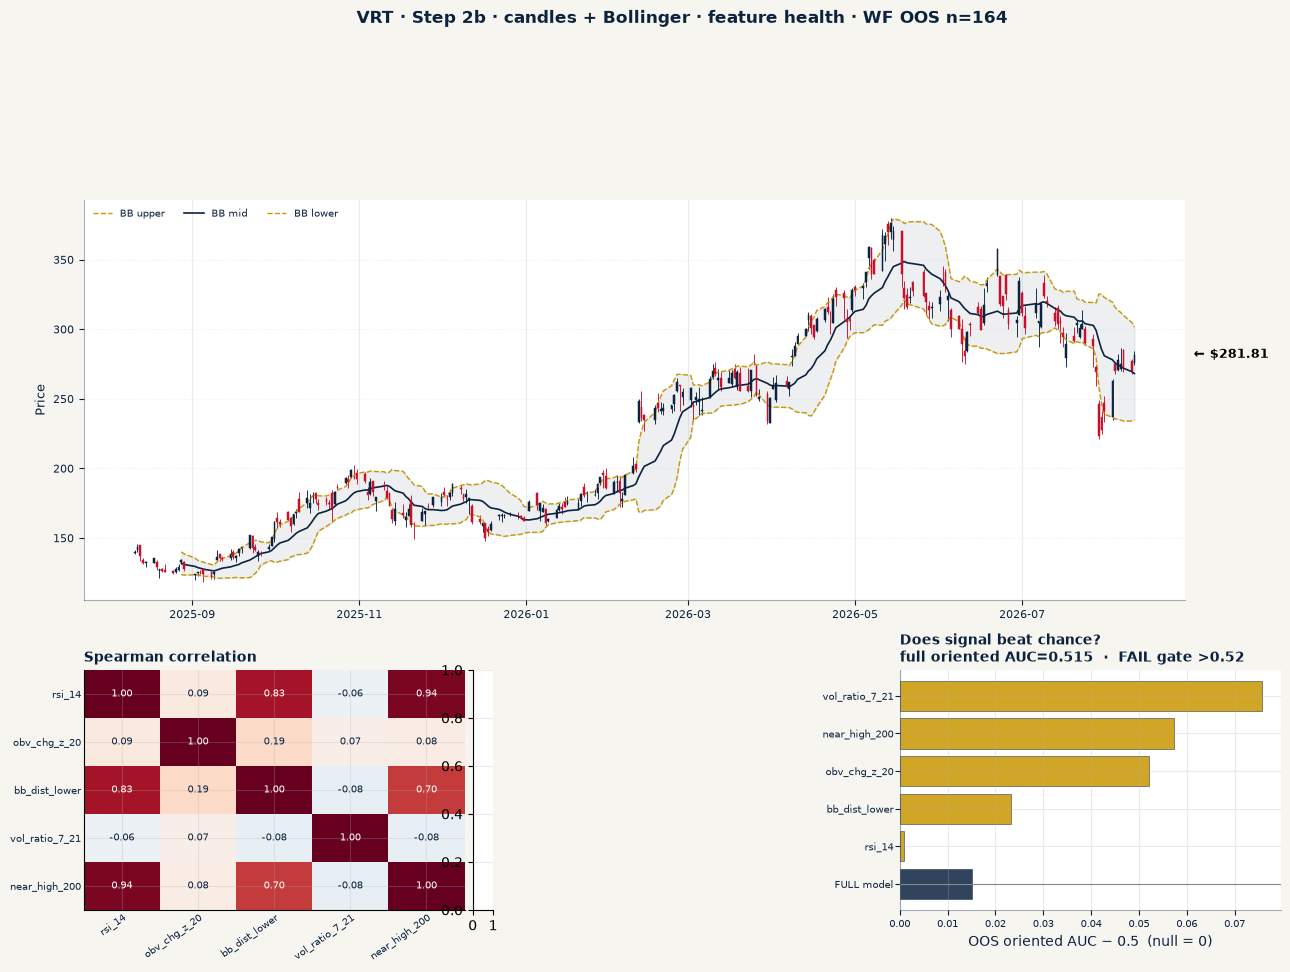

saved /Users/matthewpappas/code/ml_analysis/improves_VRT_2026-08-12/00_candles_feature_health_VRT.png
saved /Users/matthewpappas/code/ml_analysis/improves_VRT_2026-08-12/00_candles_feature_health_VRT.png

Wrote feature_health_*.json / corr / vif / univariate / ablation CSVs
⚠ Model fails oriented AUC>0.52 — threshold charts may still look 'lucky' on small n.


In [107]:
import json
# Step 2b — feature health + model improvement gates
# First run-folder chart after feature assemble: plot_00_candles_feature_health()
# (no early candle preview before features)
# Depends on model_df, FEATURE_COLS, TARGET_CLS, RANDOM_STATE, OUTPUT_DIR

from scipy import stats
from sklearn.metrics import roc_auc_score

def variance_inflation_factor(exog: np.ndarray, exog_idx: int) -> float:
    """VIF_j = 1 / (1 - R^2_j) from regression of col j on other cols."""
    y = exog[:, exog_idx]
    X = np.delete(exog, exog_idx, axis=1)
    # add intercept
    X = np.column_stack([np.ones(len(X)), X])
    try:
        beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
        yhat = X @ beta
        ss_res = float(np.sum((y - yhat) ** 2))
        ss_tot = float(np.sum((y - y.mean()) ** 2))
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0
        r2 = min(max(r2, 0.0), 0.999999)
        return float(1.0 / (1.0 - r2))
    except Exception:
        return float("nan")

X_all = model_df[FEATURE_COLS].astype(float)
y_all = model_df[TARGET_CLS].astype(int)
MIN_TRAIN_DIAG = max(80, int(0.35 * len(model_df)))
ND_NAVY, ND_GOLD, ND_RED = "#0C2340", "#C99700", "#C8102E"

print("=" * 64)
print("STEP 2b: FEATURE & MODEL HEALTH (before threshold calibration)")
print("=" * 64)
print(f"rows={len(model_df)}  features={FEATURE_COLS}")
print(f"class base UP={y_all.mean():.1%}  MIN_TRAIN_DIAG={MIN_TRAIN_DIAG}")

# ---------- 1) Correlation + VIF ----------
corr = X_all.corr(method="spearman")
corr.index.name = None
corr.columns.name = None
corr.to_csv(OUTPUT_DIR / f"feature_corr_spearman_{TICKER}.csv")
print("\n--- Spearman |corr| pairs ≥ 0.70 ---")
pairs = []
cols = list(FEATURE_COLS)
for i, a in enumerate(cols):
    for b in cols[i + 1 :]:
        r = float(corr.loc[a, b])
        pairs.append((abs(r), a, b, r))
pairs.sort(reverse=True)
flag_pairs = [p for p in pairs if p[0] >= 0.70]
if not flag_pairs:
    print("  (none ≥ 0.70)")
else:
    for ab, a, b, r in flag_pairs:
        tag = "HIGH" if ab >= 0.85 else "mod"
        print(f"  [{tag}] {a} vs {b}: r={r:+.3f}")

# VIF on standardized design (rows with all finite)
X_vif = X_all.dropna()
print("\n--- VIF (pairwise multicollinearity; >10 flags redundancy) ---")
vif_rows = []
if len(X_vif) > len(FEATURE_COLS) + 5:
    Xs = (X_vif - X_vif.mean()) / X_vif.std(ddof=0).replace(0, np.nan)
    Xs = Xs.dropna(axis=1)
    for j, name in enumerate(Xs.columns):
        try:
            v = float(variance_inflation_factor(Xs.to_numpy(), j))
        except Exception:
            v = float("nan")
        vif_rows.append({"feature": name, "vif": v})
    vif_df = pd.DataFrame(vif_rows).sort_values("vif", ascending=False)
else:
    vif_df = pd.DataFrame({"feature": FEATURE_COLS, "vif": [np.nan] * len(FEATURE_COLS)})
display(vif_df.round(2))
vif_df.to_csv(OUTPUT_DIR / f"feature_vif_{TICKER}.csv", index=False)
high_vif = vif_df[vif_df["vif"] > 10]
if len(high_vif):
    print(f"  ⚠ VIF>10: {list(high_vif['feature'])}")
else:
    print("  OK: no VIF>10")

# ---------- 2–4) Expanding walk-forward: full, univariate, ablation ----------
def _xgb():
    return XGBClassifier(
        n_estimators=120, max_depth=2, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
        objective="binary:logistic", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=2,
    )

oos_y, oos_full, oos_base = [], [], []
oos_uni = {f: [] for f in FEATURE_COLS}
oos_drop = {f: [] for f in FEATURE_COLS}

for i in range(MIN_TRAIN_DIAG, len(model_df)):
    Xtr, ytr = X_all.iloc[:i], y_all.iloc[:i]
    Xte = X_all.iloc[[i]]
    yt = int(y_all.iloc[i])
    oos_y.append(yt)
    # base: always predict base_up of train (no feature use)
    oos_base.append(float(ytr.mean()))

    clf = _xgb()
    clf.fit(Xtr, ytr)
    oos_full.append(float(clf.predict_proba(Xte)[0, 1]))

    for f in FEATURE_COLS:
        c1 = _xgb()
        c1.fit(Xtr[[f]], ytr)
        oos_uni[f].append(float(c1.predict_proba(Xte[[f]])[0, 1]))
        cols = [c for c in FEATURE_COLS if c != f]
        c2 = _xgb()
        c2.fit(Xtr[cols], ytr)
        oos_drop[f].append(float(c2.predict_proba(Xte[cols])[0, 1]))
    if (len(oos_y) % 40) == 0:
        print(f"  diag-WF {len(oos_y)}/{len(model_df) - MIN_TRAIN_DIAG}")

oos_y = np.array(oos_y)
oos_full = np.array(oos_full)
oos_base = np.array(oos_base)


def _auc(y, p):
    if len(set(y)) < 2:
        return float("nan")
    return float(roc_auc_score(y, p))


def _ic(y, p):
    r = stats.spearmanr(p, y).correlation
    return float(r) if np.isfinite(r) else float("nan")


auc_full = _auc(oos_y, oos_full)
auc_base = _auc(oos_y, oos_base)  # ~0.5 if constant; constants return nan - handle
# constant predictions: AUC undefined — use 0.5 by convention for "no signal"
if not np.isfinite(auc_base):
    auc_base = 0.5
ic_full = _ic(oos_y, oos_full)
# orient: if full IC negative, model ranks the wrong way but can still discriminate if |AUC-0.5| large
auc_oriented = auc_full if ic_full >= 0 else (1.0 - auc_full)
print(f"\n--- Model lift (expanding WF OOS, n={len(oos_y)}) ---")
print(f"  coin / null AUC             = 0.500")
print(f"  always-predict-train-mean AUC (no features) ≈ {auc_base:.3f} (should be ~0.5)")
print(f"  full XGB raw AUC            = {auc_full:.3f}  IC={ic_full:+.3f}")
print(f"  full XGB oriented AUC       = {auc_oriented:.3f}  "
      f"({'raw ranks OK' if ic_full >= 0 else 'INVERT ranks for long score'})")

model_beats_null = bool(np.isfinite(auc_oriented) and auc_oriented > 0.52)
print(f"  GATE model_beats_null (oriented AUC>0.52): {'PASS' if model_beats_null else 'FAIL'}")

print("\n--- Univariate OOS (single feature XGB) ---")
uni_rows = []
for f in FEATURE_COLS:
    a = _auc(oos_y, oos_uni[f])
    ic = _ic(oos_y, np.array(oos_uni[f]))
    a_or = a if ic >= 0 else (1 - a if np.isfinite(a) else np.nan)
    uni_rows.append(dict(feature=f, oos_auc=a, oos_ic=ic, oos_auc_oriented=a_or, lift_vs_half=(a_or - 0.5) if np.isfinite(a_or) else np.nan))
uni_df = pd.DataFrame(uni_rows).sort_values("oos_auc_oriented", ascending=False)
display(uni_df.round(4))
uni_df.to_csv(OUTPUT_DIR / f"feature_univariate_oos_{TICKER}.csv", index=False)

print("\n--- Ablation (drop one feature): Δ oriented-AUC = without − full  (neg = feature helps) ---")
abl_rows = []
# orient ablation probs the same way as full model IC for fair compare
for f in FEATURE_COLS:
    p = np.array(oos_drop[f])
    a = _auc(oos_y, p)
    ic = _ic(oos_y, p)
    a_or = a if ic_full >= 0 else (1 - a if np.isfinite(a) else np.nan)
    # Ablation uses same orient as full model IC sign
    if ic_full < 0 and np.isfinite(a):
        a_or = 1.0 - a
    elif ic_full >= 0:
        a_or = a
    delta = a_or - auc_oriented if np.isfinite(a_or) and np.isfinite(auc_oriented) else np.nan
    abl_rows.append(dict(drop=f, auc_oriented_without=a_or, delta_vs_full=delta))
abl_df = pd.DataFrame(abl_rows).sort_values("delta_vs_full")
display(abl_df.round(4))
abl_df.to_csv(OUTPUT_DIR / f"feature_ablation_oos_{TICKER}.csv", index=False)
helps = abl_df[abl_df["delta_vs_full"] < -0.005]
hurts = abl_df[abl_df["delta_vs_full"] > 0.005]
print(f"  helps when kept (drop hurts ≥0.5pp): {list(helps['drop']) if len(helps) else '—'}")
print(f"  can drop (drop improves ≥0.5pp):     {list(hurts['drop']) if len(hurts) else '—'}")


def annotate_prev_close_right(ax, close: float, *, linewidth: float = 1.15) -> None:
    """Outboard right label only (no hline): ← $XX.XX at last/prev close level."""
    try:
        c = float(close)
    except (TypeError, ValueError):
        return
    if not np.isfinite(c):
        return
    # linewidth kept for call-site compatibility; unused (no line)
    _ = linewidth
    ax.annotate(
        f"← ${c:.2f}",
        xy=(1.0, c),
        xycoords=("axes fraction", "data"),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        color="black",
        fontsize=9,
        fontweight="bold",
        clip_on=False,
        annotation_clip=False,
        zorder=8,
    )

def plot_00_candles_feature_health() -> Path:
    """Write candles + Spearman + OOS lift board under OUTPUT_DIR.

    Canonical (only) Step-2b board: 00_candles_feature_health_{TICKER}.png.
    Charts only via this function — no alias copies.
    """
    import matplotlib.dates as mdates
    from matplotlib.patches import Rectangle
    # ---------- Chart: candles+BB (top) + corr heatmap + lift bars (bottom) ----------
    import matplotlib.dates as mdates
    from matplotlib.patches import Rectangle

    cols = list(FEATURE_COLS)
    corr_plot = corr.reindex(index=cols, columns=cols)
    assert list(corr_plot.columns) == cols and list(corr_plot.index) == cols
    n_feat_h = len(cols)
    mat = corr_plot.to_numpy(dtype=float)

    # Title headroom + compact lift whose y-labels stay entirely right of mid
    _M = 0.06
    fig = plt.figure(figsize=(13.6, 10.0))
    fig.patch.set_facecolor("#F7F5F0")
    # Candle top @ 0.78 — clear band under figure title for spacing
    ax_px = fig.add_axes([_M, 0.38, 1.0 - 2 * _M - 0.07, 0.40])  # leave right gutter for prev-close label
    _bot_y, _bot_h = 0.07, 0.24
    _content_w = 1.0 - 2 * _M
    _heat_w = min(_content_w * 0.32, 0.28)
    _cbar_w = 0.015
    ax0 = fig.add_axes([_M, _bot_y, _heat_w, _bot_h])
    cax = fig.add_axes([_M + _heat_w + 0.006, _bot_y, _cbar_w, _bot_h])
    # Compact right panel: fixed 75% of right-half width (do NOT expand to edge)
    # Spine after mid + label room so y-tick text stays in right half
    _right = 1.0 - _M
    _right_half_w = _right - 0.50
    _ylab_reserve = 0.16
    _lift_w = _right_half_w * 0.75  # 25% more compact than filling right half
    _lift_x = 0.50 + _ylab_reserve
    # clamp so axes stay on figure
    if _lift_x + _lift_w > _right:
        _lift_w = _right - _lift_x
    ax1 = fig.add_axes([_lift_x, _bot_y, _lift_w, _bot_h])
    for _a in (ax_px, ax0, ax1):
        _a.set_facecolor("#FFFFFF")

    # ---- Top: candles + Bollinger (analysis window) ----
    _BB_W = int(globals().get("BB_WINDOW", 14))
    _BB_K = float(globals().get("BB_K", 1.5))
    _src = (
        bars.sort_index(ascending=True).copy()
        if "bars" in dir() and bars is not None
        else (ohlcv_hist if "ohlcv_hist" in dir() else ohlcv).sort_index(ascending=True).copy()
    )
    _mid = _src["Close"].rolling(_BB_W, min_periods=_BB_W).mean()
    _std = _src["Close"].rolling(_BB_W, min_periods=_BB_W).std(ddof=0)
    _src["BB_mid"], _src["BB_upper"], _src["BB_lower"] = _mid, _mid + _BB_K * _std, _mid - _BB_K * _std
    _px = _src.loc[_src.index >= START_TS].dropna(subset=["Open", "High", "Low", "Close"]).copy()
    xnum = mdates.date2num(_px.index.to_pydatetime())
    w = float(np.median(np.diff(xnum))) * 0.65 if len(xnum) > 1 else 0.6
    for xi, (_, r) in zip(xnum, _px.iterrows()):
        o, h, l, c = float(r.Open), float(r.High), float(r.Low), float(r.Close)
        color = ND_NAVY if c >= o else ND_RED
        ax_px.vlines(xi, l, h, color=color, linewidth=0.65, zorder=2)
        body_lo, body_hi = (o, c) if c >= o else (c, o)
        height = max(body_hi - body_lo, (h - l) * 0.002 + 1e-6)
        ax_px.add_patch(
            Rectangle(
                (xi - w / 2, body_lo), w, height,
                facecolor=color, edgecolor=color, linewidth=0.35, zorder=3,
            )
        )
    bb_ok = _px[["BB_mid", "BB_upper", "BB_lower"]].notna().all(axis=1)
    ax_px.plot(_px.index[bb_ok], _px.loc[bb_ok, "BB_upper"], color=ND_GOLD, lw=1.0, ls="--", label="BB upper")
    ax_px.plot(_px.index[bb_ok], _px.loc[bb_ok, "BB_mid"], color=ND_NAVY, lw=1.2, label="BB mid")
    ax_px.plot(_px.index[bb_ok], _px.loc[bb_ok, "BB_lower"], color=ND_GOLD, lw=1.0, ls="--", label="BB lower")
    ax_px.fill_between(
        _px.index[bb_ok], _px.loc[bb_ok, "BB_lower"], _px.loc[bb_ok, "BB_upper"],
        color=ND_NAVY, alpha=0.07, zorder=1,
    )
    # Latest session close as previous close (right-of-chart ← $xx.xx)
    if len(_px):
        annotate_prev_close_right(ax_px, float(_px["Close"].iloc[-1]))
    ax_px.set_ylabel("Price", color=ND_NAVY, fontsize=9)
    # Subplot title omitted — figure suptitle has spacing; legend carries BB context
    ax_px.set_title("")
    ax_px.legend(loc="upper left", fontsize=7, frameon=False, ncol=3, labelcolor=ND_NAVY)
    ax_px.grid(True, axis="y", alpha=0.22, ls=":")
    ax_px.tick_params(colors=ND_NAVY, labelsize=8)
    ax_px.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    for sp in ax_px.spines.values():
        sp.set_color(ND_NAVY)
        sp.set_alpha(0.35)

    # ---- Bottom-left: Spearman corr (fills panel; no letterbox pad) ----
    im = ax0.imshow(mat, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax0.set_xticks(np.arange(n_feat_h), labels=cols, rotation=35, ha="right",
                   rotation_mode="anchor", fontsize=7.5, color=ND_NAVY)
    ax0.set_yticks(np.arange(n_feat_h), labels=cols, fontsize=7.5, color=ND_NAVY)
    ax0.tick_params(axis="x", which="major", length=0, pad=2)
    ax0.tick_params(axis="y", which="major", length=0, pad=2, labelleft=True, labelright=False)
    ax0.set_title("Spearman correlation", loc="left", color=ND_NAVY, fontweight="bold", fontsize=10)
    for ii in range(n_feat_h):
        for jj in range(n_feat_h):
            v = mat[ii, jj]
            ax0.text(jj, ii, f"{v:.2f}", ha="center", va="center", fontsize=7,
                     color=ND_NAVY if abs(v) < 0.6 else "white")
    for lab in list(ax0.get_xticklabels()) + list(ax0.get_yticklabels()):
        lab.set_clip_on(False)
    # (no colorbar: cell values are printed; palette is RdBu_r on imshow only)

    # ---- Bottom-right: uni + full lift ----
    labels = list(uni_df["feature"]) + ["FULL model"]
    vals = list((uni_df["oos_auc_oriented"] - 0.5).to_numpy()) + [auc_oriented - 0.5]
    colors = [ND_GOLD if v > 0 else ND_RED for v in vals[:-1]] + [ND_NAVY]
    ax1.axhline(0, color="#888", lw=0.8)
    ax1.barh(labels[::-1], vals[::-1], color=colors[::-1], edgecolor=ND_NAVY, linewidth=0.4, alpha=0.85)
    ax1.set_xlabel("OOS oriented AUC − 0.5  (null = 0)", color=ND_NAVY)
    ax1.set_title(
        f"Does signal beat chance?\nfull oriented AUC={auc_oriented:.3f}  ·  "
        f"{'PASS' if model_beats_null else 'FAIL'} gate >0.52",
        loc="left", color=ND_NAVY, fontweight="bold", fontsize=10,
    )
    ax1.tick_params(colors=ND_NAVY, labelsize=7)
    ax1.tick_params(axis="y", pad=1, labelleft=True)
    for sp in ax1.spines.values():
        sp.set_color(ND_NAVY)
        sp.set_alpha(0.35)

    fig.suptitle(
        f"{TICKER} · Step 2b · candles + Bollinger · feature health · WF OOS n={len(oos_y)}",
        color=ND_NAVY, fontweight="bold", y=0.97,
    )
    # Do not tight_layout — preserves equal left/right margins set on gridspec
    diag_path = OUTPUT_DIR / f"00_candles_feature_health_{TICKER}.png"
    # Single canonical Step-2b board — no 00_/00b_ aliases
    plt.savefig(diag_path, dpi=140, bbox_inches=None, facecolor=fig.get_facecolor())
    plt.show()
    print("saved", diag_path)
    return diag_path

# Charts: generate only by calling notebook plot_* functions
_p00 = plot_00_candles_feature_health()
print("saved", _p00)

feature_health = {
    "ticker": TICKER,
    "n_rows": int(len(model_df)),
    "oos_steps": int(len(oos_y)),
    "base_up": float(y_all.mean()),
    "auc_full_raw": auc_full,
    "auc_full_oriented": auc_oriented,
    "ic_full": ic_full,
    "model_beats_null": model_beats_null,
    "high_vif_features": list(high_vif["feature"]) if len(high_vif) else [],
    "high_corr_pairs": [{"a": a, "b": b, "r": r} for _, a, b, r in flag_pairs if abs(r) >= 0.85],
    "uni": uni_rows,
    "ablation": abl_rows,
}
(OUTPUT_DIR / f"feature_health_{TICKER}.json").write_text(json.dumps(feature_health, indent=2, default=str))
print("\nWrote feature_health_*.json / corr / vif / univariate / ablation CSVs")
if not model_beats_null:
    print("⚠ Model fails oriented AUC>0.52 — threshold charts may still look 'lucky' on small n.")


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Feature panel — actuals (Bollinger) + all features + outcome</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Shared calendar x-axis: price with Bollinger actuals on top, each validated feature below, outcome (next-session up/down and log return) on bottom. Same window as analysis <code style="font-size:11px;">START</code> → latest.</p>
</div>


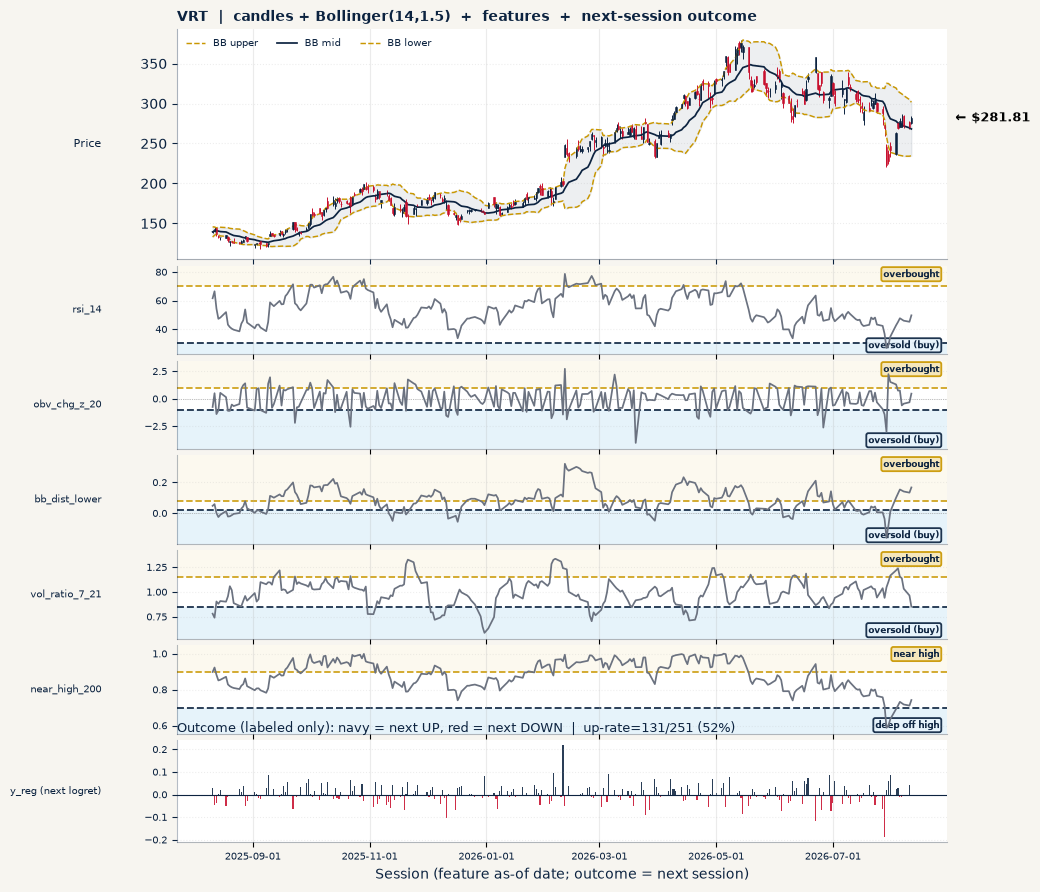

Saved → /Users/matthewpappas/code/ml_analysis/improves_VRT_2026-08-12/01_features_outcome_bb_VRT.png
Panels: price+BB, 5 features (rsi_14, obv_chg_z_20, bb_dist_lower, vol_ratio_7_21, near_high_200), outcome y_reg/y_cls
Sessions: 252  2025-08-11 → 2026-08-11
saved /Users/matthewpappas/code/ml_analysis/improves_VRT_2026-08-12/01_features_outcome_bb_VRT.png


In [108]:
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle

# Shared-x multi-panel — Notre Dame theme
# ND Navy #0C2340 | ND Gold #C99700 | ND accent red #C8102E
ND_NAVY = "#0C2340"
ND_GOLD = "#C99700"
ND_RED = "#C8102E"
ND_LIGHT_BLUE = "#A8D4F0"   # oversold / buy soft fill
ND_GOLD_PALE = "#F5E6B8"    # overbought soft fill
ND_CREAM = "#F7F5F0"
ND_NAVY_FAINT = "#0C2340"

FEATURE_ZONES = {
    "rsi_14": dict(buy_level=30.0, buy_side="below", ob_level=70.0, ob_side="above"),
    "obv_chg_z_20": dict(buy_level=-1.0, buy_side="below", ob_level=1.0, ob_side="above"),
    "bb_dist_lower": dict(buy_level=0.02, buy_side="below", ob_level=0.08, ob_side="above"),
    f"vol_ratio_{FEAT_VOL_RATIO_SHORT}_{FEAT_VOL_RATIO_LONG}": dict(
        buy_level=0.85, buy_side="below", ob_level=1.15, ob_side="above",
    ),
    f"near_high_{FEAT_NEAR_HIGH_SESSIONS}": dict(
        buy_level=0.70, buy_side="below",  # deep off high → light-blue shade below
        ob_level=0.90, ob_side="above",    # at/near peak → gold shade above
        buy_label="deep off high",
        ob_label="near high",
    ),
}
_BUY_FILL, _OB_FILL = ND_LIGHT_BLUE, ND_GOLD_PALE
_BUY_LINE, _OB_LINE = ND_NAVY, ND_GOLD
_BUY_A, _OB_A = 0.28, 0.22


def _shade_zone(ax, y0, y1, color, alpha):
    lo, hi = (y0, y1) if y0 <= y1 else (y1, y0)
    if hi - lo < 1e-12:
        return
    ax.axhspan(lo, hi, facecolor=color, alpha=alpha, zorder=0, edgecolor="none")


def _apply_feature_zones(ax, s: pd.Series, fname: str) -> None:
    z = FEATURE_ZONES.get(fname)
    if not z:
        return
    ymin = float(np.nanmin(s.to_numpy(dtype=float)))
    ymax = float(np.nanmax(s.to_numpy(dtype=float)))
    levels = [z["buy_level"], z["ob_level"], ymin, ymax]
    y_lo, y_hi = min(levels), max(levels)
    pad = 0.08 * (y_hi - y_lo + 1e-9)
    y_lo, y_hi = y_lo - pad, y_hi + pad * 1.4
    ax.set_ylim(y_lo, y_hi)
    if z["buy_side"] == "below":
        _shade_zone(ax, y_lo, z["buy_level"], _BUY_FILL, _BUY_A)
    else:
        _shade_zone(ax, z["buy_level"], y_hi, _BUY_FILL, _BUY_A)
    if z["ob_side"] == "above":
        _shade_zone(ax, z["ob_level"], y_hi, _OB_FILL, _OB_A)
    else:
        _shade_zone(ax, y_lo, z["ob_level"], _OB_FILL, _OB_A)
    ax.axhline(z["buy_level"], color=_BUY_LINE, lw=1.35, ls="--", zorder=1, alpha=0.9)
    ax.axhline(z["ob_level"], color=_OB_LINE, lw=1.25, ls="--", zorder=1, alpha=0.9)
    # Labels: buy = navy, overbought = gold
    os_top = z["buy_side"] == "above"
    ob_top = z["ob_side"] == "above"
    if os_top == ob_top:
        os_top, ob_top = False, True

    def _corner(text, top, color, edge, face):
        ax.text(
            0.99, 0.96 if top else 0.04, text,
            transform=ax.transAxes,
            ha="right", va="top" if top else "bottom",
            fontsize=6.5, fontweight="bold", color=color,
            zorder=1, clip_on=False,
            bbox=dict(boxstyle="round,pad=0.22", facecolor=face, edgecolor=edge,
                      linewidth=1.3, alpha=0.92),
        )

    buy_txt = z.get("buy_label", "oversold (buy)")
    ob_txt = z.get("ob_label", "overbought")
    _corner(buy_txt, os_top, ND_NAVY, ND_NAVY, "#E8F4FC")
    _corner(ob_txt, ob_top, ND_NAVY, ND_GOLD, ND_GOLD_PALE)


BB_WINDOW = globals().get("BB_WINDOW", 14)
BB_K = globals().get("BB_K", 1.5)

def plot_01_features_outcome_bb() -> Path:
    """Write multi-panel features + outcome board. Canonical 01_*.png entry."""
    # Build display frame on analysis window with OHLC + BB + features + labels
    _src = bars.sort_index(ascending=True).copy()
    if not {"Open", "High", "Low", "Close"}.issubset(_src.columns):
        raise RuntimeError("bars missing OHLC columns for Bollinger panel")

    _mid = _src["Close"].rolling(BB_WINDOW, min_periods=BB_WINDOW).mean()
    _std = _src["Close"].rolling(BB_WINDOW, min_periods=BB_WINDOW).std(ddof=0)
    _src["BB_mid"] = _mid
    _src["BB_upper"] = _mid + BB_K * _std
    _src["BB_lower"] = _mid - BB_K * _std

    show = _src.loc[_src.index >= START_TS].copy()
    # attach features / outcomes (NaN on unlabeled tail is OK)
    for c in FEATURE_COLS + [TARGET_REG, TARGET_CLS]:
        if c in features_df.columns:
            show[c] = features_df[c]
        elif c in bars.columns:
            show[c] = bars[c]

    show = show.dropna(subset=["Open", "High", "Low", "Close"])
    n_feat = len(FEATURE_COLS)
    # panels: price, each feature, outcome
    n_panels = 1 + n_feat + 1
    height_ratios = [2.6] + [1.0] * n_feat + [1.15]

    fig, axes = plt.subplots(
        n_panels, 1, figsize=(11.0, 2.1 + 1.05 * n_panels),
        sharex=True, gridspec_kw={"height_ratios": height_ratios, "hspace": 0.06},
    )
    fig.patch.set_facecolor(ND_CREAM)
    if n_panels == 1:
        axes = [axes]
    ax_px = axes[0]
    for ax in axes:
        ax.set_facecolor("#FFFFFF")

    # ---- Top: candles + Bollinger (actuals) ----
    xnum = mdates.date2num(show.index.to_pydatetime())
    if len(xnum) > 1:
        w = float(np.median(np.diff(xnum))) * 0.65
    else:
        w = 0.6

    for xi, (_, r) in zip(xnum, show.iterrows()):
        o, h, l, c = float(r.Open), float(r.High), float(r.Low), float(r.Close)
        up = c >= o
        color = ND_NAVY if up else ND_RED
        ax_px.vlines(xi, l, h, color=color, linewidth=0.7, zorder=2)
        body_lo, body_hi = (o, c) if c >= o else (c, o)
        height = max(body_hi - body_lo, (h - l) * 0.002 + 1e-6)
        ax_px.add_patch(
            Rectangle(
                (xi - w / 2, body_lo), w, height,
                facecolor=color, edgecolor=color, linewidth=0.4, zorder=3,
            )
        )

    bb_ok = show[["BB_mid", "BB_upper", "BB_lower"]].notna().all(axis=1)
    ax_px.plot(show.index[bb_ok], show.loc[bb_ok, "BB_upper"], color=ND_GOLD, lw=1.05, ls="--", label="BB upper")
    ax_px.plot(show.index[bb_ok], show.loc[bb_ok, "BB_mid"], color=ND_NAVY, lw=1.25, label="BB mid")
    ax_px.plot(show.index[bb_ok], show.loc[bb_ok, "BB_lower"], color=ND_GOLD, lw=1.05, ls="--", label="BB lower")
    ax_px.fill_between(
        show.index[bb_ok],
        show.loc[bb_ok, "BB_lower"],
        show.loc[bb_ok, "BB_upper"],
        color=ND_NAVY, alpha=0.07, zorder=1,
    )
    if len(show):
        annotate_prev_close_right(ax_px, float(show["Close"].iloc[-1]))
    ax_px.set_ylabel("Price", rotation=0, ha="right", va="center", labelpad=28, fontsize=8, color=ND_NAVY)
    ax_px.set_title(
        f"{TICKER}  |  candles + Bollinger({BB_WINDOW},{BB_K:g})  +  features  +  next-session outcome",
        loc="left", fontsize=10, color=ND_NAVY, fontweight="bold",
    )
    ax_px.legend(loc="upper left", fontsize=7, ncol=3, frameon=False, labelcolor=ND_NAVY)
    ax_px.grid(True, axis="y", alpha=0.22, ls=":")
    ax_px.tick_params(colors=ND_NAVY)
    for sp in ax_px.spines.values():
        sp.set_color(ND_NAVY)
        sp.set_alpha(0.35)

    # ---- Feature panels ----
    # Neutral gray series — navy/gold reserved for buy vs overbought zones only
    FEAT_LINE = "#6B7280"
    for j, fname in enumerate(FEATURE_COLS):
        ax = axes[1 + j]
        s = show[fname]
        _apply_feature_zones(ax, s, fname)
        ax.plot(show.index, s, color=FEAT_LINE, lw=1.25, zorder=3)
        ax.axhline(0.0, color="#888", lw=0.5, ls=":", zorder=2)
        ax.set_ylabel(fname, rotation=0, ha="right", va="center", labelpad=28, fontsize=7.5, color=ND_NAVY)
        ax.grid(True, axis="y", alpha=0.20, ls=":", zorder=1)
        ax.tick_params(axis="y", labelsize=7, colors=ND_NAVY)
        for sp in ax.spines.values():
            sp.set_color(ND_NAVY)
            sp.set_alpha(0.3)

    # ---- Outcome: next-session direction + log return ----
    ax_y = axes[-1]
    y_up = show[TARGET_CLS]
    y_lr = show[TARGET_REG]
    mask = y_lr.notna()
    colors_y = np.where(y_up[mask].to_numpy() == 1, ND_NAVY, ND_RED)
    ax_y.bar(
        show.index[mask], y_lr[mask].to_numpy(),
        width=w * 0.9, color=colors_y, alpha=0.88, align="center",
    )
    ax_y.axhline(0.0, color=ND_NAVY, lw=0.8)
    ax_y.set_ylabel("y_reg (next logret)", rotation=0, ha="right", va="center", labelpad=28, fontsize=7, color=ND_NAVY)
    ax_y.set_xlabel("Session (feature as-of date; outcome = next session)", color=ND_NAVY)
    n_lab = int(mask.sum())
    n_up = int((y_up[mask] == 1).sum()) if n_lab else 0
    ax_y.set_title(
        f"Outcome (labeled only): navy = next UP, red = next DOWN  |  "
        f"up-rate={n_up}/{n_lab} ({(n_up/n_lab if n_lab else float('nan')):.0%})",
        loc="left", fontsize=9, color=ND_NAVY,
    )
    ax_y.grid(True, axis="y", alpha=0.22, ls=":")
    ax_y.tick_params(axis="y", labelsize=7, colors=ND_NAVY)
    for sp in ax_y.spines.values():
        sp.set_color(ND_NAVY)
        sp.set_alpha(0.3)

    # x formatting on bottom only
    ax_y.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=12))
    ax_y.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    for label in ax_y.get_xticklabels():
        label.set_rotation(0)
        label.set_ha("center")
        label.set_fontsize(7.5)
        label.set_color(ND_NAVY)

    fig.align_ylabels(axes)
    fig.subplots_adjust(left=0.20, right=0.90, top=0.96, bottom=0.10)
    out_path = OUTPUT_DIR / f"01_features_outcome_bb_{TICKER}.png"
    plt.savefig(out_path, dpi=140, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    print(f"Saved → {out_path}")
    print(f"Panels: price+BB, {n_feat} features ({', '.join(FEATURE_COLS)}), outcome {TARGET_REG}/{TARGET_CLS}")
    print(f"Sessions: {len(show):,}  {show.index.min().date()} → {show.index.max().date()}")
    return out_path

_p01 = plot_01_features_outcome_bb()
print("saved", _p01)


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 3: Validate last 30 sessions + predict target date</b></p>
<ol style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Walk-forward</b> over the last <code style="font-size:11px;">VAL_WINDOW_SESSIONS</code> (30) <b>labeled</b> rows in <code style="font-size:11px;">model_df</code>  </li>
</ol>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">   (features at close \(t\) → realized next-session outcome \(t+1\)).</p>
<ol style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">Train Lasso + XGBoost each step on <b>all history before</b> the OOS row (expanding).</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Score only BUY signals</b> — precision / win rate among days we would enter.  </li>
</ol>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">   SKIP / “don’t buy” days are <b>not</b> counted as hits or misses (no credit for correct non-entries).</p>
<ol style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Predict <code style="font-size:11px;">PREDICT_TARGET_DATE</code></b> using features from the last completed session before that date.</li>
</ol>
</div>


In [109]:
import json
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

PRED_TARGET_TS = pd.Timestamp(PREDICT_TARGET_DATE)
MIN_TRAIN_ROWS = 60  # hard floor before first walk-forward step


def make_lasso(alpha: float) -> Pipeline:
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=alpha, max_iter=20_000)),
    ])


def make_xgb() -> XGBClassifier:
    return XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=5,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


# ---------------------------------------------------------------------------
# A) Last-30 labeled walk-forward validation
# ---------------------------------------------------------------------------
n = len(model_df)
if n <= MIN_TRAIN_ROWS + 5:
    raise RuntimeError(f"Need more labeled rows than MIN_TRAIN_ROWS={MIN_TRAIN_ROWS}; have {n}")

val_n = min(VAL_WINDOW_SESSIONS, n - MIN_TRAIN_ROWS)
wf_start = n - val_n  # first OOS index into model_df

# α chosen once on history before the 30-day window
pre_val = model_df.iloc[:wf_start]
n_splits = min(5, max(2, len(pre_val) // 40))
alpha_search = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LassoCV(
            alphas=np.logspace(-5, -1, 40),
            cv=TimeSeriesSplit(n_splits=n_splits),
            max_iter=20_000,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
])
alpha_search.fit(pre_val[FEATURE_COLS], pre_val[TARGET_REG])
chosen_alpha = float(alpha_search.named_steps["model"].alpha_)
print(f"Lasso α (fit on history before last-{val_n} window): {chosen_alpha:.4e}")

lasso_pred = np.empty(val_n)
xgb_prob = np.empty(val_n)
actual_reg = np.empty(val_n)
actual_cls = np.empty(val_n)
feat_dates = []
outcome_dates = []

for k, i in enumerate(range(wf_start, n)):
    hist = model_df.iloc[:i]
    row = model_df.iloc[i : i + 1]
    feat_dt = model_df.index[i]
    # outcome session = next calendar session in full bars after feature date
    pos = bars.index.get_loc(feat_dt)
    if pos + 1 >= len(bars.index):
        raise RuntimeError("No outcome session after feature date")
    out_dt = bars.index[pos + 1]

    lm = make_lasso(chosen_alpha)
    lm.fit(hist[FEATURE_COLS], hist[TARGET_REG])
    lp = float(lm.predict(row[FEATURE_COLS])[0])

    xm = make_xgb()
    xm.fit(hist[FEATURE_COLS], hist[TARGET_CLS], verbose=False)
    xp = float(xm.predict_proba(row[FEATURE_COLS])[0, 1])

    lasso_pred[k] = lp
    xgb_prob[k] = xp
    actual_reg[k] = float(row[TARGET_REG].iloc[0])
    actual_cls[k] = int(row[TARGET_CLS].iloc[0])
    feat_dates.append(feat_dt)
    outcome_dates.append(out_dt)

    if (k + 1) % 5 == 0 or k + 1 == val_n:
        print(f"  val walk-forward {k + 1}/{val_n}")

lasso_dir = (lasso_pred > 0).astype(int)
# Default class call at 0.5 is only for display; buy scoring uses BUY_* thresholds below.
xgb_dir = (xgb_prob >= 0.5).astype(int)

def _buy_from_row(xgb_p: float, lasso_lr: float) -> int:
    """Oriented entry score ≥ thr (matches Step 3b buy_signal)."""
    auto_inv = bool(globals().get("XGB_AUTO_INVERT", False))
    rp = OUTPUT_DIR / f"entry_rule_80_{TICKER}.json"
    if rp.exists():
        try:
            auto_inv = bool(json.loads(rp.read_text()).get("auto_invert", auto_inv))
        except Exception:
            pass
    thr = float(globals().get("BUY_ENTRY_SCORE_MIN", BUY_XGB_PROB_MIN))
    score = (1.0 - float(xgb_p)) if auto_inv else float(xgb_p)
    ok = score >= thr
    if BUY_REQUIRE_LASSO_UP:
        ok = ok and (float(lasso_lr) > 0)
    return int(ok)


def _precision_when_signal(signal: np.ndarray, y: np.ndarray) -> tuple[int, float]:
    """Win rate among days we would enter. Skip/no-buy days are ignored."""
    m = signal.astype(bool)
    n = int(m.sum())
    if n == 0:
        return 0, float("nan")
    return n, float(y[m].mean())


val_panel = pd.DataFrame(
    {
        "feature_asof": feat_dates,
        "outcome_session": outcome_dates,
        "y_logret": actual_reg,
        "y_up": actual_cls.astype(int),
        "lasso_pred_logret": lasso_pred,
        "lasso_pred_up": lasso_dir,
        "xgb_prob_up": xgb_prob,
        "xgb_pred_up": xgb_dir,
    }
).set_index("outcome_session")

# Per-head and combined entry signals (1 = BUY / would enter, 0 = SKIP — not scored)
val_panel["lasso_buy"] = val_panel["lasso_pred_up"].astype(int)  # buy if Lasso predicts up
_auto_inv = bool(globals().get("XGB_AUTO_INVERT", False))
if (OUTPUT_DIR / f"entry_rule_80_{TICKER}.json").exists():
    try:
        _auto_inv = bool(json.loads((OUTPUT_DIR / f"entry_rule_80_{TICKER}.json").read_text()).get("auto_invert", _auto_inv))
    except Exception:
        pass
_score = (1.0 - val_panel["xgb_prob_up"]) if _auto_inv else val_panel["xgb_prob_up"]
val_panel["xgb_buy"] = (_score >= float(BUY_ENTRY_SCORE_MIN)).astype(int)
val_panel["rule_buy"] = [
    _buy_from_row(p, lr)
    for p, lr in zip(val_panel["xgb_prob_up"], val_panel["lasso_pred_logret"])
]
# Outcome only on buy days (NaN = skip — excluded from accuracy)
val_panel["lasso_buy_win"] = np.where(val_panel["lasso_buy"] == 1, val_panel["y_up"], np.nan)
val_panel["xgb_buy_win"] = np.where(val_panel["xgb_buy"] == 1, val_panel["y_up"], np.nan)
val_panel["rule_buy_win"] = np.where(val_panel["rule_buy"] == 1, val_panel["y_up"], np.nan)

n_lasso_buy, wr_lasso = _precision_when_signal(val_panel["lasso_buy"].to_numpy(), val_panel["y_up"].to_numpy())
n_xgb_buy, wr_xgb = _precision_when_signal(val_panel["xgb_buy"].to_numpy(), val_panel["y_up"].to_numpy())
n_rule_buy, wr_rule = _precision_when_signal(val_panel["rule_buy"].to_numpy(), val_panel["y_up"].to_numpy())

val_metrics = pd.Series(
    {
        "n_sessions": val_n,
        "window_start": str(val_panel.index.min().date()),
        "window_end": str(val_panel.index.max().date()),
        "scoring": "buy_days_only (skips excluded)",
        "rule": f"entry_score≥{float(BUY_ENTRY_SCORE_MIN):.1%}" + (" & Lasso>0" if BUY_REQUIRE_LASSO_UP else ""),
        "lasso_buys": n_lasso_buy,
        "lasso_win_rate_when_buy": wr_lasso,
        "xgb_buys": n_xgb_buy,
        "xgb_win_rate_when_buy": wr_xgb,
        "rule_buys": n_rule_buy,
        "rule_win_rate_when_buy": wr_rule,
        "skips_not_scored": int(val_n - n_rule_buy),
        "lasso_mae_logret": mean_absolute_error(actual_reg, lasso_pred),
        "lasso_rmse_logret": mean_squared_error(actual_reg, lasso_pred) ** 0.5,
        # regression diagnostics only — not entry-accuracy
    }
)

print("\n=== Last-30 walk-forward — BUY-DAY ACCURACY ONLY ===")
print("Skips (don’t buy) are never hits or misses; they do not enter the denominator.")
display(val_metrics.to_frame("value"))
print(
    f"Rule buy: {n_rule_buy}/{val_n} days entered  |  "
    f"win@buy={wr_rule:.1%}" if n_rule_buy else f"Rule buy: 0/{val_n} entries — nothing to score"
)
if n_rule_buy:
    buys = val_panel.loc[val_panel["rule_buy"] == 1, ["y_up", "xgb_prob_up", "lasso_pred_logret"]]
    print("Scored buy days only:")
    display(buys.style.format({"xgb_prob_up": "{:.3f}", "lasso_pred_logret": "{:+.4f}"}))
print("Full day-by-day panel (newest last; rule_buy_win is NaN on skips):")
display(val_panel.tail(15).style.format({
    "y_logret": "{:+.4f}",
    "lasso_pred_logret": "{:+.4f}",
    "xgb_prob_up": "{:.3f}",
}))

# Directional hit/miss plot is generated AFTER the next-day prediction block
# so dir_hits_last30 includes the pending PREDICT_TARGET_DATE bar.

# ---------------------------------------------------------------------------
# B) Predict PREDICT_TARGET_DATE (8/11)
# ---------------------------------------------------------------------------
# Features as-of last completed session strictly before the target date.
# If target is the next session after latest bar, asof = latest bar.
# If target bar already in data (incomplete earlier filter may have dropped it), still use prior session.
eligible = bars.index[bars.index < PRED_TARGET_TS]
if len(eligible) == 0:
    raise RuntimeError(f"No feature session before {PREDICT_TARGET_DATE}")
asof_ts = eligible[-1]

# Need full feature vector at asof_ts from `bars` (includes unlabeled latest row)
need_cols = FEATURE_COLS
if any(c not in bars.columns for c in need_cols):
    raise RuntimeError("Feature columns missing on bars — re-run feature cells")
if bars.loc[asof_ts, need_cols].isna().any():
    raise RuntimeError(f"NaN features on asof {asof_ts.date()} — increase PRE_START_DAYS")

# Train on labeled rows with feature date < asof (only info available at asof close)
train_mask = model_df.index <= asof_ts
# rows with index == asof_ts have label for *next* session (= target if next is PRED_TARGET)
# For training prediction *of* target, do not use a row that leaks the target outcome:
# model_df index is feature date; label is next session. So training can include feature dates
# strictly before asof_ts only, OR feature date == previous. Safest: index < asof_ts
# so we never train on the label that *is* the thing we predict when asof is prior day...
# Actually: row t has features at t and y = outcome t+1. To predict 8/11 from features 8/10:
#   train rows with feature date < 8/10 (labels through 8/10 outcome which uses 8/10 close as target from 8/7…)
#   row 8/7 has y = move into 8/10 — OK, known by 8/10 close
#   row with feature 8/10 has y = 8/11 — unknown, not in model_df if dropna
train_df = model_df.loc[model_df.index < asof_ts]
if len(train_df) < MIN_TRAIN_ROWS:
    raise RuntimeError(f"Insufficient train rows before {asof_ts.date()}: {len(train_df)}")

X_tr, y_reg_tr, y_cls_tr = train_df[FEATURE_COLS], train_df[TARGET_REG], train_df[TARGET_CLS]
X_live = bars.loc[[asof_ts], FEATURE_COLS]

live_lasso = make_lasso(chosen_alpha)
live_lasso.fit(X_tr, y_reg_tr)
live_logret = float(live_lasso.predict(X_live)[0])

live_xgb = make_xgb()
live_xgb.fit(X_tr, y_cls_tr, verbose=False)
live_prob = float(live_xgb.predict_proba(X_live)[0, 1])
live_up = int(live_prob >= 0.5)

# Map log-return forecast to expected close level
close_asof = float(bars.loc[asof_ts, "Close"])
pred_close = close_asof * float(np.exp(live_logret))

# Feature dump for audit
live_feats = bars.loc[asof_ts, FEATURE_COLS]

print("\n=== Prediction for", PREDICT_TARGET_DATE, "===")
print(f"  Feature as-of session: {asof_ts.date()}  Close={close_asof:.4f}")
print(f"  Train rows:            {len(train_df):,}  ending {train_df.index.max().date()}")
print(f"  Question:              Will {PREDICT_TARGET_DATE} close > {asof_ts.date()} close ({close_asof:.2f})?")
print(f"  Lasso log-return:      {live_logret:+.6f}  → implied close ≈ {pred_close:.2f}  dir={'UP' if live_logret > 0 else 'DOWN/FLAT'}")
print(f"  XGBoost P(up):         {live_prob:.1%}  call={'UP' if live_up else 'DOWN/FLAT'}")
print("\n  Features @ as-of:")
display(live_feats.to_frame("value").round(6))

pred_target = pd.Series({
    "ticker": TICKER,
    "target_session": PREDICT_TARGET_DATE,
    "feature_asof": str(asof_ts.date()),
    "close_asof": close_asof,
    "lasso_pred_logret": live_logret,
    "lasso_implied_close": pred_close,
    "lasso_pred_up": int(live_logret > 0),
    "xgb_prob_up": live_prob,
    "xgb_pred_up": live_up,
    "train_rows": len(train_df),
    "lasso_alpha": chosen_alpha,
})
display(pred_target.to_frame("value"))

# ---------------------------------------------------------------------------
# Buy-day success/failure only (last N) + pending next-day decision
# ---------------------------------------------------------------------------
# Green/red only when we BUY. Gray = SKIP (not scored). Pending buy/skip not realized yet.

# 03_dir_hits is written only by plot_03_dir_hits_lastn() (Step 3b buy rule):
# candles + entry-score bars (height = P-style score) + thr enter-zone + actuals.
# Do not write a strip chart here — it overwrites the canonical 03 board.

# persist
val_panel.to_parquet(OUTPUT_DIR / f"val_last{val_n}_{TICKER}.parquet")
with open(OUTPUT_DIR / f"pred_{PREDICT_TARGET_DATE}_{TICKER}.json", "w") as f:
    json.dump({k: (float(v) if hasattr(v, "item") else v) for k, v in pred_target.items()}, f, indent=2, default=str)
with open(OUTPUT_DIR / f"val_metrics_last{val_n}_{TICKER}.json", "w") as f:
    json.dump({k: (None if pd.isna(v) else (float(v) if not isinstance(v, str) else v)) for k, v in val_metrics.items()}, f, indent=2)
print("Wrote val panel, metrics, and target prediction under OUTPUT_DIR")


Lasso α (fit on history before last-30 window): 2.2855e-03
  val walk-forward 5/30
  val walk-forward 10/30
  val walk-forward 15/30
  val walk-forward 20/30
  val walk-forward 25/30
  val walk-forward 30/30

=== Last-30 walk-forward — BUY-DAY ACCURACY ONLY ===
Skips (don’t buy) are never hits or misses; they do not enter the denominator.


,value
n_sessions,30
window_start,2026-06-30
window_end,2026-08-11
scoring,buy_days_only (skips excluded)
rule,entry_score≥72.0%
lasso_buys,29
lasso_win_rate_when_buy,0.448276
xgb_buys,0
xgb_win_rate_when_buy,NaN
rule_buys,0


Rule buy: 0/30 entries — nothing to score
Full day-by-day panel (newest last; rule_buy_win is NaN on skips):


,feature_asof,y_logret,y_up,lasso_pred_logret,lasso_pred_up,xgb_prob_up,xgb_pred_up,lasso_buy,xgb_buy,rule_buy,lasso_buy_win,xgb_buy_win,rule_buy_win
outcome_session,,,,,,,,,,,,,
2026-07-22 00:00:00,2026-07-21 00:00:00,-0.0110,0,+0.0063,1,0.922,1,1,0,0,0.000000,nan,nan
2026-07-23 00:00:00,2026-07-22 00:00:00,+0.0095,1,+0.0055,1,0.787,1,1,0,0,1.000000,nan,nan
2026-07-24 00:00:00,2026-07-23 00:00:00,-0.0460,0,+0.0053,1,0.788,1,1,0,0,0.000000,nan,nan
2026-07-27 00:00:00,2026-07-24 00:00:00,-0.0096,0,+0.0026,1,0.685,1,1,0,0,0.000000,nan,nan
2026-07-28 00:00:00,2026-07-27 00:00:00,-0.0648,0,+0.0056,1,0.823,1,1,0,0,0.000000,nan,nan
2026-07-29 00:00:00,2026-07-28 00:00:00,-0.1894,0,+0.0019,1,0.567,1,1,0,0,0.000000,nan,nan
2026-07-30 00:00:00,2026-07-29 00:00:00,+0.0198,1,+0.0037,1,0.496,0,1,0,0,1.000000,nan,nan
2026-07-31 00:00:00,2026-07-30 00:00:00,+0.0600,1,+0.0056,1,0.756,1,1,0,0,1.000000,nan,nan
2026-08-03 00:00:00,2026-07-31 00:00:00,+0.0852,1,+0.0082,1,0.888,1,1,0,0,1.000000,nan,nan



=== Prediction for 2026-08-12 ===
  Feature as-of session: 2026-08-11  Close=281.8100
  Train rows:            251  ending 2026-08-10
  Question:              Will 2026-08-12 close > 2026-08-11 close (281.81)?
  Lasso log-return:      -0.002473  → implied close ≈ 281.11  dir=DOWN/FLAT
  XGBoost P(up):         57.8%  call=UP

  Features @ as-of:


,value
Price,
rsi_14,49.694454
obv_chg_z_20,0.464270
bb_dist_lower,0.166974
vol_ratio_7_21,0.851928
near_high_200,0.741886


,value
ticker,VRT
target_session,2026-08-12
feature_asof,2026-08-11
close_asof,281.809998
lasso_pred_logret,-0.002473
lasso_implied_close,281.113968
lasso_pred_up,0
xgb_prob_up,0.578343
xgb_pred_up,1
train_rows,251


Wrote val panel, metrics, and target prediction under OUTPUT_DIR


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 3b: Buy rule — “next close higher than prior close”</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Goal:</b> decide when to <b>buy</b> (or stay long into the next session) so the trade profits if  </p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">\(\mathrm{Close}_{\text{next}} > \mathrm{Close}_{\text{asof}}\).</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>How a bar maps to a trade</b></p>
<table style="font-size:12px;border-collapse:collapse;margin:0.35em 0;">
<tr><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Clock (CST)</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Feature session</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Bet</th></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Before 3:00 PM</td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">last <b>completed</b> day before today</td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">today’s close > that close</td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">At/after 3:00 PM</td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>today</b> (if complete)</td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">next session close > today’s close</td></tr>
</table>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Buy signal (tunable in Step 0)</b></p>
<pre style="font-size:11px;line-height:1.35;margin:0.35em 0;padding:6px 8px;overflow:auto;white-space:pre-wrap;"><code style="font-size:11px;">BUY if:
  XGB P(up) &gt;= BUY_XGB_PROB_MIN
  AND (optional) Lasso predicted log-return &gt; 0   # BUY_REQUIRE_LASSO_UP</code></pre>
<ul style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Fire buy</b> → hold through the outcome session close (or until your exit rule).  </li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>No fire</b> → cash / skip — <b>not scored</b> (never a hit or miss).</li>
</ul>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>What we measure on the last 30</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Only days the rule <b>buys</b>: did the next close finish higher?  </p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Accuracy = win rate among BUY signals</b> (precision). Skip days never enter the denominator.</p>
</div>

<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Note:</b> Buy-rule win@buy / P&amp;L / pending ENTER are plotted on <code style="font-size:11px;">03_dir_hits_last*_CRM.png</code> (04 retired as duplicate).</p>


=== Buy-rule accuracy (BUY days only; skips excluded from denominator) ===


,value
rule,entry_score≥72.0%
sessions,30
buys,0
skips,30
coverage,0.0
win_rate_when_buy,NaN
base_up_rate_all_days,0.466667
avg_logret_when_buy,NaN
strategy_cum_simple,0.0
always_long_cum,-0.081962


No buys fired — nothing to score. Lower BUY_ENTRY_SCORE_MIN or turn off BUY_REQUIRE_LASSO_UP.
03 thr source: ENTRY_THR=72.0%  mode=composite  auto_invert=True  (from entry_rule_80 when composite+discriminating, else config)

=== Live buy decision ===
  Target session:  2026-08-12  (want close > 2026-08-11 @ 281.81)
  Decision:        SKIP
  Why:             entry_score=42.2% < thr 72.0%  (raw P(up)=57.8%, inverted); Lasso logret=-0.0025 (not required)
03 close-dot spot-check (idx, date, close, prior_close, dot):
  [0] 2026-06-30  close=334.82  prior=306.97  → green
  [15] 2026-07-22  close=301.16  prior=304.50  → red
  [29] 2026-08-11  close=281.81  prior=270.10  → green
03 last-30 composite thr=50.0%  (operating thr=72.0%)  buy-in=25.0% n=4  gain_cap=-19.5%
saved /Users/matthewpappas/code/ml_analysis/improves_VRT_2026-08-12/03_dir_hits_last30_VRT.png


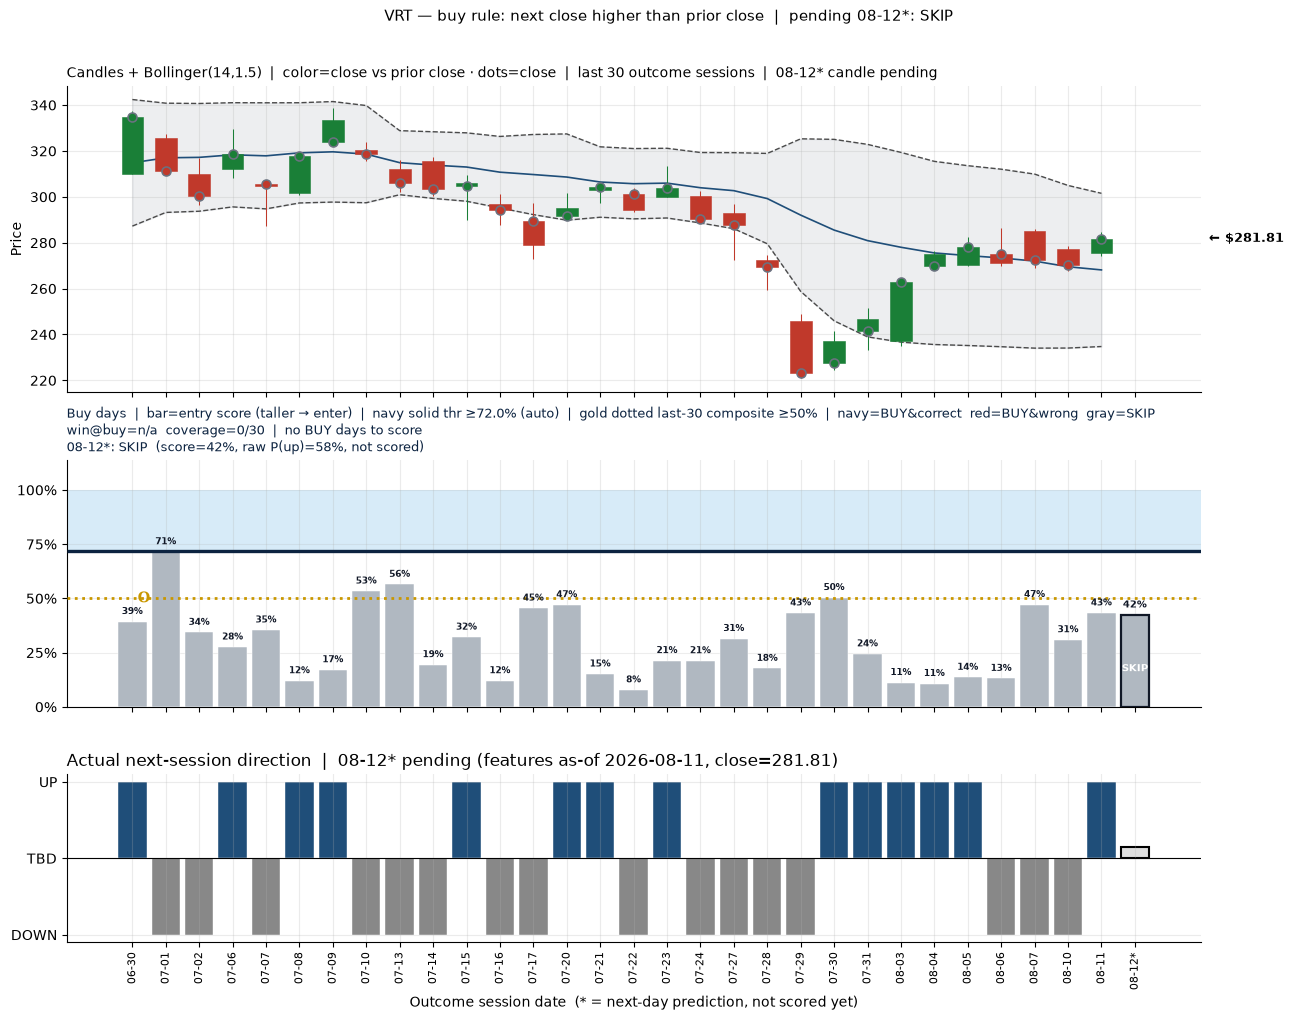

Wrote buy decision + backtest panel under OUTPUT_DIR


In [110]:
# Depends on val_panel + pred_target + chosen_alpha from Step 3 walk-forward cell.
# Thr for 03 / buy JSON must match auto calibration (entry_rule_80) when mode=composite.

def resolve_operating_entry() -> tuple:
    """Return (thr, auto_invert, is_discriminating).

    • composite (default): prefer entry_rule_80 operating thr when discriminating
    • manual: pin BUY_ENTRY_SCORE_MIN from config
    Pins BUY_ENTRY_SCORE_MIN / BUY_XGB_PROB_MIN so buy_signal and 03 share one thr.
    """
    global BUY_ENTRY_SCORE_MIN, BUY_XGB_PROB_MIN
    rule_path = OUTPUT_DIR / f"entry_rule_80_{TICKER}.json"
    auto_inv = bool(globals().get("XGB_AUTO_INVERT", False))
    is_disc = globals().get("XGB_IS_DISCRIMINATING", None)
    mode = str(globals().get("BUY_ENTRY_THR_MODE", "manual")).lower().strip()
    thr = float(globals().get("BUY_ENTRY_SCORE_MIN", BUY_XGB_PROB_MIN))
    if rule_path.exists():
        try:
            er = json.loads(rule_path.read_text())
            if is_disc is None:
                is_disc = er.get("is_discriminating")
            auto_inv = bool(er.get("auto_invert", auto_inv))
            if mode in ("composite", "auto"):
                _op = er.get("operating_entry_score_min")
                if _op is None and isinstance(er.get("composite_rule"), dict):
                    _op = er["composite_rule"].get("entry_score_min")
                if _op is None and isinstance(er.get("best_rule"), dict):
                    _op = er["best_rule"].get("operator_entry_score_min") or er["best_rule"].get("entry_score_min")
                if is_disc is not False and _op is not None and np.isfinite(float(_op)):
                    thr = float(_op)
        except Exception:
            pass
    BUY_ENTRY_SCORE_MIN = float(thr)
    BUY_XGB_PROB_MIN = float(thr)
    return float(thr), bool(auto_inv), is_disc


def buy_signal(xgb_prob: float, lasso_logret: float) -> bool:
    """Enter long if oriented entry score ≥ operating thr (auto or manual)."""
    thr, auto_inv, is_disc = resolve_operating_entry()
    if is_disc is False:
        return False
    score = (1.0 - float(xgb_prob)) if auto_inv else float(xgb_prob)
    ok = score >= thr
    if BUY_REQUIRE_LASSO_UP:
        ok = ok and (lasso_logret > 0)
    return bool(ok)



# ---- A) Apply rule to last-N validation panel ----
buy = val_panel.apply(
    lambda r: buy_signal(float(r["xgb_prob_up"]), float(r["lasso_pred_logret"])),
    axis=1,
)
val_panel = val_panel.copy()
val_panel["buy"] = buy.astype(int)
val_panel["buy_win"] = np.where(val_panel["buy"] == 1, val_panel["y_up"], np.nan)

n_buy = int(val_panel["buy"].sum())
n_skip = int((val_panel["buy"] == 0).sum())
if n_buy > 0:
    win_rate = float(val_panel.loc[val_panel["buy"] == 1, "y_up"].mean())
    # simple one-day return when we buy: actual next logret (or use simple from bars)
    avg_logret_when_buy = float(val_panel.loc[val_panel["buy"] == 1, "y_logret"].mean())
    # strategy daily logret: take market logret on buy days else 0
    strat_logret = np.where(val_panel["buy"] == 1, val_panel["y_logret"], 0.0)
    strat_cum = float(np.exp(strat_logret.sum()) - 1.0)
    always_cum = float(np.exp(val_panel["y_logret"].sum()) - 1.0)
else:
    win_rate = np.nan
    avg_logret_when_buy = np.nan
    strat_cum = 0.0
    always_cum = float(np.exp(val_panel["y_logret"].sum()) - 1.0)

buy_metrics = pd.Series({
    "rule": f"entry_score≥{BUY_ENTRY_SCORE_MIN:.1%}" + (" & Lasso>0" if BUY_REQUIRE_LASSO_UP else ""),
    "sessions": len(val_panel),
    "buys": n_buy,
    "skips": n_skip,
    "coverage": n_buy / len(val_panel),
    "win_rate_when_buy": win_rate,           # P(next close up | we bought)
    "base_up_rate_all_days": float(val_panel["y_up"].mean()),
    "avg_logret_when_buy": avg_logret_when_buy,
    "strategy_cum_simple": strat_cum,        # compound sum of logrets on buy days, flat else
    "always_long_cum": always_cum,
    "lift_win_vs_base": (win_rate - float(val_panel["y_up"].mean())) if n_buy else np.nan,
})

print("=== Buy-rule accuracy (BUY days only; skips excluded from denominator) ===")
display(buy_metrics.to_frame("value"))
if n_buy == 0:
    print("No buys fired — nothing to score. Lower BUY_ENTRY_SCORE_MIN or turn off BUY_REQUIRE_LASSO_UP.")
else:
    print(f"SCORED: {n_buy} buys → win@buy={win_rate:.1%}.  "
          f"NOT SCORED: {n_skip} skips (do not count as correct/incorrect).")

# ---- B) Pending decision for PREDICT_TARGET_DATE (uses pred_target from Step 3) ----
live_buy = buy_signal(float(pred_target["xgb_prob_up"]), float(pred_target["lasso_pred_logret"]))
pend_label = pd.Timestamp(pred_target["target_session"]).strftime("%m-%d")
pend_prob = float(pred_target["xgb_prob_up"])
PEND_BUY, PEND_SKIP = "#2563eb", "#9ca3af"

# Plot: entry_score bars (bigger = higher chance to enter). Color by buy outcome.
n_hist = len(val_panel)
n_all = n_hist + 1
x = np.arange(n_all)
dates = [d.strftime("%m-%d") for d in val_panel.index] + [pend_label + "*"]

# Notre Dame palette
ND_NAVY = "#0C2340"       # buy threshold / hit
ND_GOLD = "#C99700"
MISS_RED = "#C8102E"
SKIP_GRAY = "#B0B8C1"
LIGHT_BLUE = "#A8D4F0"    # fill above thr = enter zone
HIT_NAVY = "#0C2340"
PEND_EDGE = "#111827"

# Oriented entry score: taller bar → more reason to enter (matches buy rule)
_auto_inv_plot = bool(globals().get("XGB_AUTO_INVERT", False))
_rule_path = OUTPUT_DIR / f"entry_rule_80_{TICKER}.json"
if _rule_path.exists():
    try:
        _auto_inv_plot = bool(json.loads(_rule_path.read_text()).get("auto_invert", _auto_inv_plot))
    except Exception:
        pass
ENTRY_THR, _auto_inv_plot, _ = resolve_operating_entry()
print(
    f"03 thr source: ENTRY_THR={ENTRY_THR:.1%}  mode={str(globals().get('BUY_ENTRY_THR_MODE', '?'))}  "
    f"auto_invert={_auto_inv_plot}  "
    f"(from entry_rule_80 when composite+discriminating, else config)"
)
hist_raw = val_panel["xgb_prob_up"].to_numpy(dtype=float)
hist_scores = (1.0 - hist_raw) if _auto_inv_plot else hist_raw.copy()
pend_score = (1.0 - float(pend_prob)) if _auto_inv_plot else float(pend_prob)
bar_heights = list(hist_scores) + [pend_score]
val_panel = val_panel.copy()
val_panel["entry_score"] = hist_scores

buy_colors = []
for _, r in val_panel.iterrows():
    if r["buy"] == 0:
        buy_colors.append(SKIP_GRAY)
    elif r["y_up"] == 1:
        buy_colors.append(HIT_NAVY)  # BUY & next UP
    else:
        buy_colors.append(MISS_RED)  # BUY & next DOWN
buy_colors.append(HIT_NAVY if live_buy else SKIP_GRAY)

# Re-apply buy after thr may have synced from entry_rule_80
buy = val_panel.apply(
    lambda r: buy_signal(float(r["xgb_prob_up"]), float(r["lasso_pred_logret"])),
    axis=1,
)
val_panel["buy"] = buy.astype(int)
val_panel["buy_win"] = np.where(val_panel["buy"] == 1, val_panel["y_up"], np.nan)
n_buy = int(val_panel["buy"].sum())
n_skip = int((val_panel["buy"] == 0).sum())
if n_buy > 0:
    win_rate = float(val_panel.loc[val_panel["buy"] == 1, "y_up"].mean())
    avg_logret_when_buy = float(val_panel.loc[val_panel["buy"] == 1, "y_logret"].mean())
else:
    win_rate = float("nan")
    avg_logret_when_buy = float("nan")
live_buy = buy_signal(float(pred_target["xgb_prob_up"]), float(pred_target["lasso_pred_logret"]))
buy_colors = []
for _, r in val_panel.iterrows():
    if int(r["buy"]) == 0:
        buy_colors.append(SKIP_GRAY)
    elif int(r["y_up"]) == 1:
        buy_colors.append(HIT_NAVY)
    else:
        buy_colors.append(MISS_RED)
buy_colors.append(HIT_NAVY if live_buy else SKIP_GRAY)
hist_scores = (1.0 - hist_raw) if _auto_inv_plot else hist_raw.copy()
pend_score = (1.0 - float(pend_prob)) if _auto_inv_plot else float(pend_prob)
bar_heights = list(hist_scores) + [pend_score]
val_panel["entry_score"] = hist_scores



def composite_thr_lastn(
    entry_scores: np.ndarray,
    y_up: np.ndarray,
    y_logret: np.ndarray,
    min_trades=None,
) -> dict:
    """Same composite thr recipe as 02 / entry calibration, on a fixed window (e.g. last-N).

    composite = W_PREC * rank_pct(precision) + W_GAIN * rank_pct(gain_captured)
    among thr with n_buys ≥ min_trades (else all thr with n≥1).
    """
    scores = np.asarray(entry_scores, dtype=float)
    y = np.asarray(y_up, dtype=int)
    r = np.asarray(y_logret, dtype=float)
    r = np.where(np.isfinite(r), r, 0.0)
    simple = np.expm1(r)  # close_next/close − 1
    n = len(scores)
    if n == 0:
        return {"thr": float("nan"), "precision": float("nan"), "n_buys": 0, "n_wins": 0, "gain_captured": float("nan")}
    min_tr = int(min_trades if min_trades is not None else globals().get("MIN_TRADES", 10))
    # last-N is short: never demand more trades than exist
    min_tr = max(1, min(min_tr, max(3, n // 3)))
    base_up = float(y.mean()) if n else 0.5
    total_up = float(simple[y == 1].sum())
    rows = []
    for thr in np.round(np.arange(0.50, 0.96, 0.01), 2):
        m = scores >= thr
        n_buys = int(m.sum())
        n_wins = int((m & (y == 1)).sum())
        prec = (n_wins / n_buys) if n_buys else np.nan
        net = float(simple[m].sum()) if n_buys else 0.0
        gain_cap = (net / total_up) if total_up > 0 else np.nan
        rows.append({
            "entry_score_min": float(thr),
            "n_buys": n_buys,
            "n_wins": n_wins,
            "precision": prec,
            "gain_captured": gain_cap,
        })
    scan = pd.DataFrame(rows)
    comp = scan[
        (scan["n_buys"] >= 1) & scan["precision"].notna() & scan["gain_captured"].notna()
    ].copy()
    if len(comp) == 0:
        return {"thr": float("nan"), "precision": float("nan"), "n_buys": 0, "n_wins": 0, "gain_captured": float("nan"), "base_up": base_up}
    w_p = float(globals().get("BUY_ENTRY_COMPOSITE_W_PREC", 2.0))
    w_g = float(globals().get("BUY_ENTRY_COMPOSITE_W_GAIN", 1.0))
    comp["pct_prec"] = comp["precision"].rank(method="average", pct=True)
    comp["pct_gain"] = comp["gain_captured"].rank(method="average", pct=True)
    comp["composite"] = w_p * comp["pct_prec"] + w_g * comp["pct_gain"]
    pool = comp[comp["n_buys"] >= min_tr] if (comp["n_buys"] >= min_tr).any() else comp
    row = pool.sort_values(["composite", "precision", "n_wins", "n_buys"], ascending=False).iloc[0]
    return {
        "thr": float(row["entry_score_min"]),
        "precision": float(row["precision"]),
        "n_buys": int(row["n_buys"]),
        "n_wins": int(row["n_wins"]),
        "gain_captured": float(row["gain_captured"]),
        "composite": float(row["composite"]),
        "min_trades": min_tr,
        "base_up": base_up,
        "w_prec": w_p,
        "w_gain": w_g,
    }


def plot_03_dir_hits_lastn() -> Path:
    """Write candles + entry-score + actuals board. Canonical 03_dir_hits_*.png entry.

    Always re-reads auto thr from entry_rule_80 (composite) so 03 matches calibration.
    """
    global ENTRY_THR, BUY_ENTRY_SCORE_MIN, BUY_XGB_PROB_MIN
    global hist_scores, pend_score, bar_heights, buy_colors, live_buy, n_buy, win_rate
    global _auto_inv_plot, val_panel, pend_prob

    # Refresh thr + score orientation from auto rule (or manual pin)
    ENTRY_THR, _auto_inv_plot, _disc = resolve_operating_entry()
    hist_raw = val_panel["xgb_prob_up"].to_numpy(dtype=float)
    hist_scores = (1.0 - hist_raw) if _auto_inv_plot else hist_raw.copy()
    pend_prob = float(pred_target["xgb_prob_up"])
    pend_score = (1.0 - pend_prob) if _auto_inv_plot else pend_prob
    bar_heights = list(hist_scores) + [pend_score]
    val_panel = val_panel.copy()
    val_panel["entry_score"] = hist_scores
    live_buy = buy_signal(pend_prob, float(pred_target["lasso_pred_logret"]))
    _buys = val_panel.apply(
        lambda r: buy_signal(float(r["xgb_prob_up"]), float(r["lasso_pred_logret"])),
        axis=1,
    )
    val_panel["buy"] = _buys.astype(int)
    val_panel["buy_win"] = np.where(val_panel["buy"] == 1, val_panel["y_up"], np.nan)
    n_buy = int(val_panel["buy"].sum())
    win_rate = float(val_panel.loc[val_panel["buy"] == 1, "y_up"].mean()) if n_buy else float("nan")
    buy_colors = []
    for _, r in val_panel.iterrows():
        if int(r["buy"]) == 0:
            buy_colors.append(SKIP_GRAY)
        elif int(r["y_up"]) == 1:
            buy_colors.append(HIT_NAVY)
        else:
            buy_colors.append(MISS_RED)
    buy_colors.append(HIT_NAVY if live_buy else SKIP_GRAY)

    # ---- 3-panel: candles+BB | entry-score bars | actual direction ----
    from matplotlib.patches import Rectangle as _Rect

    # OHLC + Bollinger for outcome windows (match val_panel dates; pending may be missing)
    _BB_W = int(BB_WINDOW) if "BB_WINDOW" in dir() else 14
    _BB_K = float(BB_K) if "BB_K" in dir() else 1.5
    if "bars" in dir() and {"Open", "High", "Low", "Close"}.issubset(set(bars.columns)):
        _ohlc = bars[["Open", "High", "Low", "Close"]].copy()
    else:
        _cache = DATA_DIR / f"cache_ohlcv_hist_{TICKER}.parquet"
        if not _cache.exists():
            _cache = DATA_DIR / f"cache_ohlcv_{TICKER}.parquet"
        _ohlc = pd.read_parquet(_cache)[["Open", "High", "Low", "Close"]].copy()
    _m = _ohlc["Close"].rolling(_BB_W, min_periods=_BB_W).mean()
    _s = _ohlc["Close"].rolling(_BB_W, min_periods=_BB_W).std(ddof=0)
    _ohlc["BB_mid"], _ohlc["BB_upper"], _ohlc["BB_lower"] = _m, _m + _BB_K * _s, _m - _BB_K * _s

    fig, axes = plt.subplots(
        3, 1, figsize=(14, 10.2), sharex=True,
        gridspec_kw={"height_ratios": [1.55, 1.25, 0.85]},
    )
    ax_px, ax_p, ax_a = axes

    # Top: candlesticks + Bollinger aligned to bar indices
    _cw = 0.65
    _bb_x, _bb_mid, _bb_up, _bb_lo = [], [], [], []
    for i, dt in enumerate(val_panel.index):
        if dt not in _ohlc.index:
            continue
        r = _ohlc.loc[dt]
        o, h, l, c = float(r.Open), float(r.High), float(r.Low), float(r.Close)
        # Color by session move (close vs prior close), not open→close body direction
        _pos = _ohlc.index.get_loc(dt)
        if isinstance(_pos, (slice, np.ndarray)):
            _pos = int(np.min(_pos)) if isinstance(_pos, np.ndarray) else int(_pos.start)
        prior_c = float(_ohlc["Close"].iloc[int(_pos) - 1]) if int(_pos) > 0 else float("nan")
        if np.isfinite(prior_c):
            col = "#1a7f37" if c >= prior_c else "#c0392b"
        else:
            col = "#1a7f37" if c >= o else "#c0392b"
        ax_px.vlines(i, l, h, color=col, linewidth=0.75, zorder=3)
        blo, bhi = (o, c) if c >= o else (c, o)
        ax_px.add_patch(
            _Rect(
                (i - _cw / 2, blo), _cw, max(bhi - blo, (h - l) * 0.002 + 1e-6),
                facecolor=col, edgecolor=col, linewidth=0.4, zorder=4,
            )
        )
        # close mark: tiny green/red dot (close vs prior close)
        ax_px.scatter(
            [i], [c], s=42, c=col, edgecolors="#6B7280", linewidths=1.15,
            zorder=6, clip_on=False,
        )
        if pd.notna(r.BB_mid):
            _bb_x.append(i)
            _bb_mid.append(float(r.BB_mid))
            _bb_up.append(float(r.BB_upper))
            _bb_lo.append(float(r.BB_lower))
    # pending day candle if available
    _pend_dt = pd.Timestamp(pred_target["target_session"]) if "pred_target" in dir() else pd.Timestamp(PREDICT_TARGET_DATE)
    if _pend_dt in _ohlc.index:
        r = _ohlc.loc[_pend_dt]
        o, h, l, c = float(r.Open), float(r.High), float(r.Low), float(r.Close)
        _pos = _ohlc.index.get_loc(_pend_dt)
        if isinstance(_pos, (slice, np.ndarray)):
            _pos = int(np.min(_pos)) if isinstance(_pos, np.ndarray) else int(_pos.start)
        prior_c = float(_ohlc["Close"].iloc[int(_pos) - 1]) if int(_pos) > 0 else float("nan")
        if np.isfinite(prior_c):
            col = "#1a7f37" if c >= prior_c else "#c0392b"
        else:
            col = "#1a7f37" if c >= o else "#c0392b"
        ax_px.vlines(n_hist, l, h, color=col, linewidth=0.75, zorder=3)
        blo, bhi = (o, c) if c >= o else (c, o)
        ax_px.add_patch(
            _Rect(
                (n_hist - _cw / 2, blo), _cw, max(bhi - blo, (h - l) * 0.002 + 1e-6),
                facecolor=col, edgecolor=col, linewidth=0.4, zorder=4,
            )
        )
        ax_px.scatter(
            [n_hist], [c], s=42, c=col, edgecolors="#6B7280", linewidths=1.15,
            zorder=6, clip_on=False,
        )
        if pd.notna(r.BB_mid):
            _bb_x.append(n_hist)
            _bb_mid.append(float(r.BB_mid))
            _bb_up.append(float(r.BB_upper))
            _bb_lo.append(float(r.BB_lower))

    # Spot-check close marks (first/mid/last scored session)
    _chk = []
    for _j, _dt in enumerate(val_panel.index):
        if _dt not in _ohlc.index:
            continue
        _c = float(_ohlc.loc[_dt, "Close"])
        _pos = _ohlc.index.get_loc(_dt)
        if isinstance(_pos, (slice, np.ndarray)):
            _pos = int(np.min(_pos)) if isinstance(_pos, np.ndarray) else int(_pos.start)
        _pc = float(_ohlc["Close"].iloc[int(_pos) - 1]) if int(_pos) > 0 else float("nan")
        _col = "green" if (np.isfinite(_pc) and _c >= _pc) or (not np.isfinite(_pc) and _c >= float(_ohlc.loc[_dt, "Open"])) else "red"
        if not np.isfinite(_pc):
            _col = "green" if _c >= float(_ohlc.loc[_dt, "Open"]) else "red"
        else:
            _col = "green" if _c >= _pc else "red"
        _chk.append((_j, pd.Timestamp(_dt).strftime("%Y-%m-%d"), _c, _pc, _col))
    if _chk:
        print("03 close-dot spot-check (idx, date, close, prior_close, dot):")
        for _row in (_chk[0], _chk[len(_chk)//2], _chk[-1]):
            _j, _ds, _c, _pc, _col = _row
            _pd = ("%.2f" % _pc) if np.isfinite(_pc) else "n/a"
            print(f"  [{_j}] {_ds}  close={_c:.2f}  prior={_pd}  → {_col}")

    if _bb_x:
        ax_px.fill_between(_bb_x, _bb_lo, _bb_up, color="#9ca3af", alpha=0.18, zorder=1)
        ax_px.plot(_bb_x, _bb_up, color="#4a4a4a", lw=1.0, ls="--", zorder=2)
        ax_px.plot(_bb_x, _bb_mid, color="#1f4e79", lw=1.2, zorder=2)
        ax_px.plot(_bb_x, _bb_lo, color="#4a4a4a", lw=1.0, ls="--", zorder=2)
    # Previous close = last completed session used as features as-of (dynamic; e.g. 08-11 → $843.37)
    try:
        _prev_close = float(
            pred_target.get("close_asof", float("nan"))
            if hasattr(pred_target, "get")
            else pred_target["close_asof"]
        )
    except Exception:
        _prev_close = float("nan")
    if not np.isfinite(_prev_close) and len(val_panel):
        _ld = val_panel.index[-1]
        if _ld in _ohlc.index:
            _prev_close = float(_ohlc.loc[_ld, "Close"])
    if np.isfinite(_prev_close):
        annotate_prev_close_right(ax_px, _prev_close)
    ax_px.set_ylabel("Price")
    ax_px.set_title(
        f"Candles + Bollinger({_BB_W},{_BB_K:g})  |  color=close vs prior close · dots=close  |  last {n_hist} outcome sessions"
        + (f" + {pend_label}*" if _pend_dt in _ohlc.index else f"  |  {pend_label}* candle pending"),
        loc="left",
        fontsize=10,
    )
    ax_px.grid(True, axis="y", alpha=0.25)
    for sp in ("top", "right"):
        ax_px.spines[sp].set_visible(False)

    # Middle: bar height = entry score (bigger = higher chance we enter)
    # Light blue band = BUY zone (score ≥ thr); navy thr line
    ax_p.axhspan(ENTRY_THR, 1.0, facecolor=LIGHT_BLUE, alpha=0.45, zorder=0, edgecolor="none")
    ax_p.axhline(ENTRY_THR, color=ND_NAVY, lw=2.4, zorder=4, solid_capstyle="butt")
    # Dotted: composite thr optimized on *this chart's* last-N days (same recipe as 02)
    _ln_opt = composite_thr_lastn(
        hist_scores,
        val_panel["y_up"].to_numpy(dtype=int),
        val_panel["y_logret"].to_numpy(dtype=float),
    )
    _ln_thr = float(_ln_opt.get("thr", float("nan")))
    if np.isfinite(_ln_thr):
        ax_p.axhline(
            _ln_thr, color="#C99700", lw=2.0, ls=":", zorder=4,
            solid_capstyle="butt",
        )
        # "O" = Optimal last-N composite thr; capital letter sits on gold dotted line (inside plot)
        ax_p.text(
            0.35,
            _ln_thr,
            "O",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="#C99700",
            zorder=8,
            clip_on=False,
        )
        print(
            "03 last-%d composite thr=%.1f%%  (operating thr=%.1f%%)  "
            "buy-in=%.1f%% n=%d  gain_cap=%+.1f%%"
            % (
                n_hist,
                100.0 * _ln_thr,
                100.0 * float(ENTRY_THR),
                100.0 * float(_ln_opt["precision"]),
                int(_ln_opt["n_buys"]),
                100.0 * float(_ln_opt["gain_captured"]),
            )
        )
    else:
        print("03 last-%d composite thr: n/a" % n_hist)

    ax_p.bar(
        x, bar_heights, color=buy_colors, width=0.85,
        edgecolor="white", lw=0.35, zorder=3,
    )
    # Pending outline
    ax_p.bar(
        [n_hist], [pend_score], color="none", edgecolor=PEND_EDGE,
        linewidth=1.6, width=0.85, zorder=5,
    )
    for i, (bought, sc) in enumerate(zip(val_panel["buy"].to_numpy(), hist_scores)):
        col = (
            "#111827" if not bought
            else (ND_NAVY if val_panel["y_up"].iloc[i] == 1 else MISS_RED)
        )
        ax_p.text(
            i, float(sc) + 0.025, f"{float(sc):.0%}", ha="center", va="bottom",
            color=col, fontsize=6.5, fontweight="bold", zorder=6,
        )
    ax_p.text(
        n_hist, float(pend_score) + 0.025, f"{pend_score:.0%}",
        ha="center", va="bottom", color="#111827", fontsize=7.5, fontweight="bold", zorder=6,
    )
    ax_p.text(
        n_hist, max(float(pend_score) * 0.42, 0.05), "BUY" if live_buy else "SKIP",
        ha="center", va="center",
        color="white" if pend_score >= 0.22 else ND_NAVY,
        fontsize=7.5, fontweight="bold", zorder=6,
    )
    ax_p.set_ylim(0, 1.14)
    ax_p.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax_p.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax_p.grid(True, axis="y", alpha=0.22, zorder=1)

    # % P&L on buy days only (skips are flat / not scored)
    if n_buy:
        buy_pcts = np.expm1(val_panel.loc[val_panel["buy"] == 1, "y_logret"].to_numpy(dtype=float)) * 100.0
        avg_buy_pct = float(np.mean(buy_pcts))
        sum_buy_pct = float(np.sum(buy_pcts))
        compound_buy_pct = float(np.prod(1.0 + buy_pcts / 100.0) - 1.0) * 100.0
        n_win = int((val_panel.loc[val_panel["buy"] == 1, "y_up"] == 1).sum())
        n_lose = int(n_buy - n_win)
        wr_txt = f"{win_rate:.1%}"
        pnl_line = (
            f"when BUY next-day %: avg {avg_buy_pct:+.2f}%  |  "
            f"sum {sum_buy_pct:+.2f} ppt  |  compounded {compound_buy_pct:+.2f}%  "
            f"({n_win}W/{n_lose}L)"
        )
    else:
        avg_buy_pct = sum_buy_pct = compound_buy_pct = float("nan")
        n_win = n_lose = 0
        wr_txt = "n/a"
        pnl_line = "no BUY days to score"

    _thr_title = "navy solid thr ≥%.1f%% (auto)" % (100.0 * float(ENTRY_THR))
    if np.isfinite(_ln_thr):
        _thr_title += "  |  gold dotted last-%d composite ≥%.0f%%" % (n_hist, 100.0 * _ln_thr)
    _title_mid = chr(10).join([
        "Buy days  |  bar=entry score (taller → enter)  |  " + _thr_title
        + "  |  navy=BUY&correct  red=BUY&wrong  gray=SKIP",
        "win@buy=%s  coverage=%d/%d  |  %s" % (wr_txt, n_buy, n_hist, pnl_line),
        "%s*: %s  (score=%.0f%%, raw P(up)=%.0f%%, not scored)" % (
            pend_label,
            "BUY" if live_buy else "SKIP",
            100.0 * float(pend_score),
            100.0 * float(pend_prob),
        ),
    ])
    ax_p.set_title(
        _title_mid,
        loc="left",
        fontsize=9.5,
        color=ND_NAVY,
    )
    for sp in ("top", "right"):
        ax_p.spines[sp].set_visible(False)

    # Bottom: actual next-session direction
    act_c = ["#1f4e79" if a == 1 else "#888888" for a in val_panel["y_up"]] + ["#dddddd"]
    act_vals = list(val_panel["y_up"].to_numpy() * 2 - 1) + [0.0]
    ax_a.bar(x, act_vals, color=act_c, width=0.85, edgecolor="white", lw=0.3)
    ax_a.bar([n_hist], [0.15], color="#dddddd", edgecolor="black", linewidth=1.5, width=0.85)
    ax_a.axhline(0, color="black", lw=0.8)
    ax_a.set_yticks([-1, 0, 1])
    ax_a.set_yticklabels(["DOWN", "TBD", "UP"])
    _asof = pred_target.get("feature_asof", "") if hasattr(pred_target, "get") else pred_target["feature_asof"]
    try:
        _close = float(pred_target.get("close_asof", float("nan")) if hasattr(pred_target, "get") else pred_target["close_asof"])
    except Exception:
        _close = float("nan")
    _asof_s = str(_asof)[:10] if _asof not in ("", None) else "?"
    _close_s = f"{_close:.2f}" if np.isfinite(_close) else "?"
    ax_a.set_title(
        f"Actual next-session direction  |  {pend_label}* pending "
        f"(features as-of {_asof_s}, close={_close_s})",
        loc="left",
    )
    ax_a.set_xticks(x)
    ax_a.set_xticklabels(dates, rotation=90, fontsize=8)
    ax_a.set_xlabel("Outcome session date  (* = next-day prediction, not scored yet)")
    _sup_pnl = (
        f"  |  buy P&L compounded {compound_buy_pct:+.2f}%  sum {sum_buy_pct:+.2f} ppt"
        if n_buy else ""
    )
    fig.suptitle(
        f"{TICKER} — buy rule: next close higher than prior close  |  "
        f"pending {pend_label}*: {'BUY' if live_buy else 'SKIP'}"
        f"{_sup_pnl}",
        y=0.995,
        fontsize=11,
    )
    fig.subplots_adjust(left=0.07, right=0.88, top=0.92, bottom=0.08, hspace=0.28)
    plt.savefig(OUTPUT_DIR / f"03_dir_hits_last{n_hist}_{TICKER}.png", dpi=140, bbox_inches="tight")
    _p03 = OUTPUT_DIR / f"03_dir_hits_last{n_hist}_{TICKER}.png"
    return _p03


# ---- C) Emit decision object for PREDICT_TARGET_DATE ----
decision = pd.Series({
    "ticker": TICKER,
    "target_session": pred_target["target_session"],
    "feature_asof": pred_target["feature_asof"],
    "close_asof": float(pred_target["close_asof"]),
    "xgb_prob_up": float(pred_target["xgb_prob_up"]),
    "lasso_pred_logret": float(pred_target["lasso_pred_logret"]),
    "lasso_implied_close": float(pred_target.get("lasso_implied_close", float("nan"))),
    "BUY_ENTRY_SCORE_MIN": float(BUY_ENTRY_SCORE_MIN),
    "BUY_REQUIRE_LASSO_UP": BUY_REQUIRE_LASSO_UP,
    "decision": "BUY" if live_buy else "SKIP",
    "rationale": (
        (
            "XGB not discriminating on OOS: max buy-in precision "
            f"(TP/(TP+FP)) never >50% at any thr≥50% — no tradeable entry "
            f"(live P(up)={float(pred_target['xgb_prob_up']):.1%})"
        )
        if (
            globals().get("XGB_IS_DISCRIMINATING") is False
            or (
                globals().get("XGB_IS_DISCRIMINATING") is None
                and (OUTPUT_DIR / f"entry_rule_80_{TICKER}.json").exists()
                and json.loads((OUTPUT_DIR / f"entry_rule_80_{TICKER}.json").read_text()).get("is_discriminating") is False
            )
        )
        else (
            (
                (lambda _p, _thr, _inv: (
                    f"entry_score={((1.0 - _p) if _inv else _p):.1%} "
                    f"{'≥' if ((1.0 - _p) if _inv else _p) >= _thr else '<'} thr {_thr:.1%}"
                    f"  (raw P(up)={_p:.1%}{', inverted' if _inv else ''})"
                ))(
                    float(pred_target["xgb_prob_up"]),
                    float(BUY_ENTRY_SCORE_MIN),
                    bool(_auto_inv_plot),
                )
            )
            + (
                f"; Lasso logret={float(pred_target['lasso_pred_logret']):+.4f}"
                + (" passes >0" if float(pred_target["lasso_pred_logret"]) > 0 else " fails >0")
                if BUY_REQUIRE_LASSO_UP
                else f"; Lasso logret={float(pred_target['lasso_pred_logret']):+.4f} (not required)"
            )
        )
    ),
})

print("\n=== Live buy decision ===")
print(f"  Target session:  {decision['target_session']}  (want close > {decision['feature_asof']} @ {decision['close_asof']:.2f})")
print(f"  Decision:        {decision['decision']}")
print(f"  Why:             {decision['rationale']}")

_p03 = plot_03_dir_hits_lastn()
print("saved", _p03)
try:
    plt.show()
except Exception:
    pass

with open(OUTPUT_DIR / f"buy_decision_{PREDICT_TARGET_DATE}_{TICKER}.json", "w") as f:
    json.dump(
        {k: (bool(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in decision.items()},
        f, indent=2, default=str,
    )
with open(OUTPUT_DIR / f"buy_metrics_last{len(val_panel)}_{TICKER}.json", "w") as f:
    json.dump(
        {
            k: (
                None if (isinstance(v, float) and pd.isna(v))
                else (float(v) if isinstance(v, (float, np.floating)) else v)
            )
            for k, v in buy_metrics.items()
        },
        f, indent=2, default=str,
    )
val_panel.to_parquet(OUTPUT_DIR / f"buy_panel_last{len(val_panel)}_{TICKER}.parquet")
print("Wrote buy decision + backtest panel under OUTPUT_DIR")


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 4: Walk-Forward (full history) Schedule (shared)</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Burn-in → expanding window. <b>One train index set per step</b> — Lasso and XGBoost always see the same history.</p>
</div>


In [111]:
n = len(model_df)

# Anchor burn-in to raw series start so START=today-1y + 11m burn-in leaves ~1m OOS
series_start = ohlcv.index.min()
first_pred_ts = series_start + pd.DateOffset(months=MIN_TRAIN_MONTHS)
wf_start = int(model_df.index.searchsorted(first_pred_ts))
min_rows = 40
if wf_start < min_rows:
    wf_start = min_rows
if wf_start >= n:
    raise ValueError(
        f"Not enough history for {MIN_TRAIN_MONTHS}-month burn-in "
        f"({n} rows; first_pred={first_pred_ts.date()}). "
        "Extend START or lower MIN_TRAIN_MONTHS."
    )

# Shared slices — both models use these exact rows
burn_in_idx = model_df.index[:wf_start]
oos_idx = model_df.index[wf_start:]

X_burn = X.loc[burn_in_idx]
y_reg_burn = y_reg.loc[burn_in_idx]
y_cls_burn = y_cls.loc[burn_in_idx]
X_oos = X.loc[oos_idx]
y_reg_oos = y_reg.loc[oos_idx]
y_cls_oos = y_cls.loc[oos_idx]

print(f"Series start:     {series_start.date()}")
print(f"First OOS day:    {first_pred_ts.date()}  ({MIN_TRAIN_MONTHS}m burn-in)")
print(f"Burn-in:          {len(burn_in_idx):,} rows  {burn_in_idx.min().date()} → {burn_in_idx.max().date()}")
print(f"Walk-forward OOS: {len(oos_idx):,} rows  {oos_idx.min().date()} → {oos_idx.max().date()}")
print(f"OOS up-rate:      {y_cls_oos.mean():.1%}")
print(f"WF steps:         {len(oos_idx):,}  (same train history for Lasso + XGBoost each step)")

Series start:     2025-08-11
First OOS day:    2026-07-11  (11m burn-in)
Burn-in:          230 rows  2025-08-11 → 2026-07-10
Walk-forward OOS: 21 rows  2026-07-13 → 2026-08-10
OOS up-rate:      47.6%
WF steps:         21  (same train history for Lasso + XGBoost each step)


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 5: Train Both Heads (full history) on the Same Walk-Forward</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Uses <b>validated</b> <code style="font-size:11px;">FEATURE_COLS</code> / <code style="font-size:11px;">model_df</code> from Step 2.</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">One loop. Each step <code style="font-size:11px;">i</code>:</p>
<ol style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">train rows = <code style="font-size:11px;">X.iloc[:i]</code> <b>(shared)</b></li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">fit Lasso on <code style="font-size:11px;">(X, y_reg)</code> → predicted next-day return</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">fit XGBoost on <code style="font-size:11px;">(X, y_cls)</code> → <code style="font-size:11px;">P(close[t+1] &gt; close[t])</code></li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">store OOS preds for the same date</li>
</ol>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">α for Lasso is chosen once on burn-in via <code style="font-size:11px;">LassoCV</code>; each step refits with that α.</p>
</div>


In [112]:
def make_lasso(alpha: float) -> Pipeline:
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=alpha, max_iter=10_000)),
    ])


def make_xgb() -> XGBClassifier:
    return XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=5,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


# α once on shared burn-in train window
n_splits = min(5, max(2, len(X_burn) // 30))
alpha_search = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LassoCV(
            alphas=np.logspace(-6, -2, 40),
            cv=TimeSeriesSplit(n_splits=n_splits),
            max_iter=10_000,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
])
alpha_search.fit(X_burn, y_reg_burn)
chosen_alpha = float(alpha_search.named_steps["model"].alpha_)
print(f"Shared burn-in Lasso α: {chosen_alpha:.4e}")

# ---- single expanding walk-forward loop for both models ----
lasso_oos_pred = np.empty(len(oos_idx), dtype=float)
xgb_oos_prob = np.empty(len(oos_idx), dtype=float)

for k, i in enumerate(range(wf_start, n)):
    # shared history for this step
    X_hist = X.iloc[:i]
    y_reg_hist = y_reg.iloc[:i]
    y_cls_hist = y_cls.iloc[:i]
    X_row = X.iloc[i : i + 1]

    lasso_m = make_lasso(chosen_alpha)
    lasso_m.fit(X_hist, y_reg_hist)
    lasso_oos_pred[k] = lasso_m.predict(X_row)[0]

    xgb_m = make_xgb()
    xgb_m.fit(X_hist, y_cls_hist, verbose=False)
    xgb_oos_prob[k] = xgb_m.predict_proba(X_row)[0, 1]

    if (k + 1) % 5 == 0 or k + 1 == len(oos_idx):
        print(f"  walk-forward {k + 1}/{len(oos_idx)}")

# final fits (full history except last row) for interpretability artifacts
lasso_pipe = make_lasso(chosen_alpha)
lasso_pipe.fit(X.iloc[:-1], y_reg.iloc[:-1])
lasso = lasso_pipe.named_steps["model"]

xgb_clf = make_xgb()
xgb_clf.fit(X.iloc[:-1], y_cls.iloc[:-1], verbose=False)

# OOS prediction frame — one row per step, both heads
preds = pd.DataFrame(
    {
        TARGET_REG: y_reg_oos.to_numpy(),
        TARGET_CLS: y_cls_oos.to_numpy(),
        "lasso_pred_return": lasso_oos_pred,
        "lasso_pred_up": (lasso_oos_pred > 0).astype(int),
        "xgb_prob_up": xgb_oos_prob,
        "xgb_pred_up": (xgb_oos_prob >= 0.5).astype(int),
    },
    index=oos_idx,
)

print("Walk-forward complete — shared OOS preds:")
display(preds.tail())

Shared burn-in Lasso α: 3.0703e-03
  walk-forward 5/21
  walk-forward 10/21
  walk-forward 15/21
  walk-forward 20/21
  walk-forward 21/21
Walk-forward complete — shared OOS preds:


,y_reg,y_cls,lasso_pred_return,lasso_pred_up,xgb_prob_up,xgb_pred_up
Date,,,,,,
2026-08-04,0.029243,1,0.010590,1,0.842165,1
2026-08-05,-0.010016,0,0.008003,1,0.845634,1
2026-08-06,-0.010118,0,0.007327,1,0.554136,1
2026-08-07,-0.008479,0,0.003782,1,0.670010,1
2026-08-10,0.042441,1,0.001546,1,0.569579,1


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 6: Evaluate OOS (full history WF) — buy-day accuracy only</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Same walk-forward frame as Steps 4–5, but <b>entry precision only</b>:</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">among days we would BUY, how often is next close higher?  </p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">SKIP / predict-down days are <b>not</b> accuracy.</p>
</div>


In [113]:
y_reg_test = preds[TARGET_REG].to_numpy()
y_cls_test = preds[TARGET_CLS].to_numpy()
y_reg_pred_test = preds["lasso_pred_return"].to_numpy()
y_cls_prob_test = preds["xgb_prob_up"].to_numpy()
y_cls_pred_test = preds["xgb_pred_up"].to_numpy()
lasso_dir = preds["lasso_pred_up"].to_numpy()

# Entry signals — only True days enter buy-accuracy
lasso_buy = lasso_dir.astype(bool)  # Lasso "buy" = predicted up
xgb_buy = ((1.0 - y_cls_prob_test) if globals().get("XGB_AUTO_INVERT", False) else y_cls_prob_test) >= float(BUY_ENTRY_SCORE_MIN)
if BUY_REQUIRE_LASSO_UP:
    rule_buy = xgb_buy & (y_reg_pred_test > 0)
else:
    rule_buy = xgb_buy.copy()


def _wr_when(mask: np.ndarray, y: np.ndarray) -> tuple[int, float]:
    n = int(mask.sum())
    if n == 0:
        return 0, float("nan")
    return n, float(y[mask].mean())


n_lb, wr_lb = _wr_when(lasso_buy, y_cls_test)
n_xb, wr_xb = _wr_when(xgb_buy, y_cls_test)
n_rb, wr_rb = _wr_when(rule_buy, y_cls_test)

# Regression fit quality is separate from buy accuracy
lasso_metrics = pd.Series({
    "alpha": chosen_alpha,
    "n_nonzero": int(np.sum(np.abs(lasso.coef_) > 1e-12)),
    "wf_steps": len(preds),
    "oos_r2": r2_score(y_reg_test, y_reg_pred_test),
    "oos_mae": mean_absolute_error(y_reg_test, y_reg_pred_test),
    "oos_rmse": mean_squared_error(y_reg_test, y_reg_pred_test) ** 0.5,
    "lasso_buys": n_lb,
    "lasso_win_rate_when_buy": wr_lb,
    "scoring": "buy_days_only",
})

xgb_metrics = pd.Series({
    "wf_steps": len(preds),
    "xgb_buys": n_xb,
    "xgb_win_rate_when_buy": wr_xb,
    "rule_buys": n_rb,
    "rule_win_rate_when_buy": wr_rb,
    "rule": f"entry_score≥{BUY_ENTRY_SCORE_MIN:.1%}" + (" & Lasso>0" if BUY_REQUIRE_LASSO_UP else ""),
    "skips_not_scored": int(len(preds) - n_rb),
    "scoring": "buy_days_only",
})

print("Lasso — regression fit + BUY-day accuracy (pred up only)")
display(lasso_metrics.to_frame("value").round(6))
if lasso_metrics["n_nonzero"] == 0:
    print("Note: final Lasso zeroed all coefficients — common with weak daily linear signal.")

print("XGBoost / trade rule — BUY-day accuracy only (skips excluded)")
display(xgb_metrics.to_frame("value").round(4))
print(
    f"Among rule buys ({n_rb}): win@buy={wr_rb:.1%}" if n_rb
    else "No rule buys in OOS — nothing to score."
)

# Buy-only contingency: columns are outcome | among BUY
if n_rb:
    buy_y = y_cls_test[rule_buy]
    n_win = int(buy_y.sum())
    n_lose = int(n_rb - n_win)
    buy_table = pd.DataFrame(
        {"count": [n_win, n_lose, n_rb], "share": [n_win / n_rb, n_lose / n_rb, 1.0]},
        index=["BUY → next UP (win)", "BUY → next DOWN (loss)", "total BUYs scored"],
    )
    print("Scored trades only (don’t-buy days omitted):")
    display(buy_table.round(4))

coef_df = (
    pd.DataFrame({"feature": FEATURE_COLS, "coef": lasso.coef_})
    .assign(abs_coef=lambda d: d["coef"].abs())
    .sort_values("abs_coef", ascending=False)
    .reset_index(drop=True)
)

comparison = pd.DataFrame({
    "signal": [
        "Lasso BUY (logret>0)",
        f"XGB BUY (score≥{BUY_ENTRY_SCORE_MIN:.1%})",
        f"Trade rule ({xgb_metrics['rule']})",
    ],
    "buys_scored": [n_lb, n_xb, n_rb],
    "win_rate_when_buy": [wr_lb, wr_xb, wr_rb],
    "skips_excluded": [len(preds) - n_lb, len(preds) - n_xb, len(preds) - n_rb],
}).set_index("signal")

print("Buy-day precision comparison (shared OOS frame; skips never in win rate)")
display(comparison.round(4))


Lasso — regression fit + BUY-day accuracy (pred up only)


,value
alpha,0.00307
n_nonzero,1
wf_steps,21
oos_r2,0.005987
oos_mae,0.034775
oos_rmse,0.053501
lasso_buys,21
lasso_win_rate_when_buy,0.47619
scoring,buy_days_only


XGBoost / trade rule — BUY-day accuracy only (skips excluded)


,value
wf_steps,21
xgb_buys,0
xgb_win_rate_when_buy,NaN
rule_buys,0
rule_win_rate_when_buy,NaN
rule,entry_score≥72.0%
skips_not_scored,21
scoring,buy_days_only


No rule buys in OOS — nothing to score.
Buy-day precision comparison (shared OOS frame; skips never in win rate)


,buys_scored,win_rate_when_buy,skips_excluded
signal,,,
Lasso BUY (logret>0),21,0.4762,0
XGB BUY (score≥72.0%),0,NaN,21
Trade rule (entry_score≥72.0%),0,NaN,21


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 6b: Long-entry calibration — beat coin flip &amp; population base rate</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;"><b>Buy-in accuracy</b> = precision = TP / (TP+FP) on days the rule enters. Skips never enter the denominator.</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Two floors a threshold must clear</b></p>
<ul style="font-size:12px;line-height:1.4;margin:0.35em 0;padding-left:1.2em;">
<li><b>50% coin flip</b> — unweighted random long</li>
<li><b>Weighted coin / base UP rate</b> — always-long accuracy on this OOS population</li>
</ul>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Eligible only if precision <b>&gt; max(50%, base UP)</b> and support ≥ min trades. Select the thr with highest buy-in accuracy among eligible.</p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Entry score orientation</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">If raw XGB <code style="font-size:11px;">P(up)</code> has <b>negative</b> OOS rank IC vs next-UP, auto-invert:
<code style="font-size:11px;">entry_score = 1 − P(up)</code> so higher score means stronger long signal. Enter when
<code style="font-size:11px;">entry_score ≥ thr</code>.</p>
</div>


In [114]:
# Long-entry calibration: orient XGB score, scan thr, require beat coin + base, rebuild plot.
# Depends on: panel_80 / wf_dir_panel parquet (or rebuilds expanding WF if missing), FEATURE_COLS, model_df.

from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

COIN_FLOOR = 0.50
MIN_TRADES = 10
ENTRY_MIN_TRAIN = 80
_alpha = float(chosen_alpha) if "chosen_alpha" in dir() else 0.0016

panel_path = OUTPUT_DIR / f"wf_dir_panel_{TICKER}.parquet"
if panel_path.exists() and "panel_80" not in dir():
    panel_80 = pd.read_parquet(panel_path)
elif "panel_80" not in dir():
    # full expanding rebuild (slow)
    X = model_df[FEATURE_COLS]
    y_up = model_df[TARGET_CLS].astype(int).to_numpy()
    y_log = model_df[TARGET_REG].to_numpy()
    dates = model_df.index
    rows = []
    for i in range(ENTRY_MIN_TRAIN, len(model_df)):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", Lasso(alpha=_alpha, max_iter=20_000, random_state=RANDOM_STATE)),
        ])
        pipe.fit(X.iloc[:i], y_log[:i])
        lp = float(pipe.predict(X.iloc[[i]])[0])
        clf = XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.9,
            colsample_bytree=0.9, reg_lambda=1.0, objective="binary:logistic",
            eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=2,
        )
        clf.fit(X.iloc[:i], y_up[:i])
        xp = float(clf.predict_proba(X.iloc[[i]])[:, 1][0])
        rows.append({
            "outcome_session": dates[i],
            "feature_asof": dates[i - 1] if i else dates[i],
            "y_up": int(y_up[i]),
            "lasso_pred_logret": lp,
            "lasso_pred_up": int(lp > 0),
            "xgb_prob_up": xp,
            "xgb_pred_up": int(xp >= 0.5),
        })
        if (len(rows) % 25) == 0:
            print(f"  entry-WF {len(rows)}/{len(model_df) - ENTRY_MIN_TRAIN}")
    panel_80 = pd.DataFrame(rows).set_index("outcome_session")
    panel_80.to_parquet(panel_path)

p_raw = panel_80["xgb_prob_up"].to_numpy(dtype=float)
y = panel_80["y_up"].to_numpy(dtype=int)
n_oos = len(panel_80)
n_pos = int(y.sum())
base_up = float(y.mean())
pass_floor = max(COIN_FLOOR, base_up)

rho_full = float(spearmanr(p_raw, y).correlation)
auto_invert = bool(np.isfinite(rho_full) and rho_full < 0)
entry_score = (1.0 - p_raw) if auto_invert else p_raw.copy()
XGB_AUTO_INVERT = auto_invert
XGB_IS_DISCRIMINATING = False  # set after scan

auc_raw = float(roc_auc_score(y, p_raw))
auc_oriented = float(roc_auc_score(y, entry_score))
print(f"OOS n={n_oos}  next-UP={n_pos} ({base_up:.1%})  floors: coin={COIN_FLOOR:.0%}  base={base_up:.0%}  pass>{pass_floor:.0%}")
print(f"Raw XGB: spearman IC={rho_full:+.3f}  AUC={auc_raw:.3f}")
print(f"Orientation: {'INVERT → entry_score=1−P(up)' if auto_invert else 'RAW → entry_score=P(up)'}  oriented AUC={auc_oriented:.3f}")

# Next-session simple returns for gain capture: (Close_t / Close_{t-1} - 1)
_ohlc_gc = None
if "bars" in dir() and "Close" in bars.columns:
    _ohlc_gc = bars["Close"]
else:
    _cp = DATA_DIR / f"cache_ohlcv_hist_{TICKER}.parquet"
    if not _cp.exists():
        _cp = DATA_DIR / f"cache_ohlcv_{TICKER}.parquet"
    _ohlc_gc = pd.read_parquet(_cp)["Close"]
# At feature session S, y_up = (Close_next > Close_S) → gain = Close_next/Close_S − 1
_simple_all = (_ohlc_gc.shift(-1) / _ohlc_gc - 1.0).reindex(panel_80.index).to_numpy(dtype=float)
_simple_all = np.where(np.isfinite(_simple_all), _simple_all, 0.0)
_up_mask_gc = y == 1
TOTAL_UP_SIMPLE_GAIN = float(_simple_all[_up_mask_gc].sum())
print(f"Aggregate UP-day simple gain Σ(close_next/close − 1) = {TOTAL_UP_SIMPLE_GAIN:+.4f}")

thresholds = np.round(np.arange(0.50, 0.96, 0.01), 2)
scan_rows = []
for thr in thresholds:
    m = entry_score >= thr
    n_buys = int(m.sum())
    n_wins = int((m & (y == 1)).sum())
    n_fp = int((m & (y == 0)).sum())
    precision = (n_wins / n_buys) if n_buys else np.nan
    recall = (n_wins / n_pos) if n_pos else np.nan
    tp_m = m & (y == 1)
    fp_m = m & (y == 0)
    tp_gain = float(_simple_all[tp_m].sum()) if np.any(tp_m) else 0.0
    fp_loss = float(_simple_all[fp_m].sum()) if np.any(fp_m) else 0.0  # typically ≤ 0
    # Net of FP losses: TP gains + FP returns (losses subtract)
    net_captured = tp_gain + fp_loss
    gain_captured = (
        (net_captured / TOTAL_UP_SIMPLE_GAIN)
        if TOTAL_UP_SIMPLE_GAIN > 0 else np.nan
    )
    captured_gain = net_captured  # legacy name in scan row
    f1 = (
        (2 * precision * recall / (precision + recall))
        if (n_buys and n_pos and np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0)
        else np.nan
    )
    beats_coin = bool(n_buys and np.isfinite(precision) and precision > COIN_FLOOR)
    beats_base = bool(n_buys and np.isfinite(precision) and precision > base_up)
    beats_both = bool(n_buys and np.isfinite(precision) and precision > pass_floor)
    scan_rows.append({
        "entry_score_min": thr,
        "n_buys": n_buys,
        "n_wins": n_wins,
        "n_fp": n_fp,
        "precision": precision,
        "recall": recall,
        "gain_captured": gain_captured,
        "gain_captured_sum": captured_gain,
        "tp_gain_sum": tp_gain,
        "fp_loss_sum": fp_loss,
        "net_gain_sum": net_captured,
        "f1": f1,
        "beats_coin_50": beats_coin,
        "beats_base_up": beats_base,
        "beats_both_floors": beats_both,
        "eligible": bool(beats_both and n_buys >= MIN_TRADES),
        # keep legacy cols for any downstream readers
        "xgb_p_min": thr,
        "rule": "oriented_xgb",
        "win_rate": precision,
        "coverage": n_buys / n_oos,
        "meets_target": bool(beats_both and n_buys >= MIN_TRADES),
    })
xgb_scan = pd.DataFrame(scan_rows)
xgb_scan.to_csv(OUTPUT_DIR / f"entry_threshold_scan_{TICKER}.csv", index=False)

print(f"Gain-captured range across thr: "
      f"{float(np.nanmin(xgb_scan['gain_captured']))*100:+.1f}% → "
      f"{float(np.nanmax(xgb_scan['gain_captured']))*100:+.1f}% of total UP-day sum")
print(f"  (Not absolute account P&L — fraction of available UP moves net of bad buys.)")


with_buys = xgb_scan[xgb_scan["n_buys"] >= 1].dropna(subset=["precision"])
max_buy_precision = float(with_buys["precision"].max()) if len(with_buys) else float("nan")
elig = xgb_scan[xgb_scan["eligible"]].copy()
XGB_IS_DISCRIMINATING = bool(len(elig) > 0)

# Max-precision eligible thr (reference only)
if XGB_IS_DISCRIMINATING:
    best = elig.sort_values(["precision", "n_wins", "n_buys"], ascending=False).iloc[0]
    thr_best = float(best["entry_score_min"])
    print(f"\nMax-precision eligible: score ≥ {thr_best:.0%}  buy-in={best['precision']:.1%}  "
          f"n={int(best['n_buys'])}  wins={int(best['n_wins'])}  recall={best['recall']:.1%}")
else:
    best = None
    thr_best = float("nan")
    print(f"\nNOT DISCRIMINATING: no thr with n≥{MIN_TRADES} and precision > {pass_floor:.0%}")
    print(f"  peak buy-in anywhere: {max_buy_precision:.1%}" if np.isfinite(max_buy_precision) else "")

# Composite recommend: pctile(buy-in %) + pctile(% gain captured) → take max
# Percentile ranks over thr with n≥1 and finite metrics; pick among n≥MIN_TRADES when possible.
_comp = xgb_scan[
    (xgb_scan["n_buys"] >= 1)
    & xgb_scan["precision"].notna()
    & xgb_scan["gain_captured"].notna()
].copy()
_comp["pct_prec"] = _comp["precision"].rank(method="average", pct=True)
_comp["pct_gain"] = _comp["gain_captured"].rank(method="average", pct=True)
_w_prec = float(globals().get("BUY_ENTRY_COMPOSITE_W_PREC", 2.0))
_w_gain = float(globals().get("BUY_ENTRY_COMPOSITE_W_GAIN", 1.0))
_comp["composite"] = _w_prec * _comp["pct_prec"] + _w_gain * _comp["pct_gain"]
_comp["w_prec"] = _w_prec
_comp["w_gain"] = _w_gain
# merge ranks back onto full scan for CSV / chart
xgb_scan = xgb_scan.merge(
    _comp[["entry_score_min", "pct_prec", "pct_gain", "composite"]],
    on="entry_score_min",
    how="left",
)
xgb_scan.to_csv(OUTPUT_DIR / f"entry_threshold_scan_{TICKER}.csv", index=False)

_pool = _comp[_comp["n_buys"] >= MIN_TRADES].copy() if (_comp["n_buys"] >= MIN_TRADES).any() else _comp
_comp_row = _pool.sort_values(
    ["composite", "precision", "n_wins", "n_buys"], ascending=False
).iloc[0]
thr_composite = float(_comp_row["entry_score_min"])
print(
    f"\nComposite thr (weighted: W_prec*buy-in + W_gain*gain-cap): score ≥ {thr_composite:.0%}"
    f"  composite={float(_comp_row['composite']):.3f}"
    f"  (W={_w_prec:g}/{_w_gain:g}  pct_prec={float(_comp_row['pct_prec']):.2f}  pct_gain={float(_comp_row['pct_gain']):.2f})"
    f"  buy-in={float(_comp_row['precision']):.1%}  n={int(_comp_row['n_buys'])}"
    f"  gain_cap={float(_comp_row['gain_captured']):+.1%}"
)

_mode = str(globals().get("BUY_ENTRY_THR_MODE", "manual")).lower().strip()
if _mode == "composite":
    ENTRY_OPERATING = thr_composite
    BUY_ENTRY_SCORE_MIN = float(ENTRY_OPERATING)
    BUY_XGB_PROB_MIN = float(ENTRY_OPERATING)
    print(f"ENTRY_OPERATING = {ENTRY_OPERATING:.1%}  [mode=composite auto-select]")
else:
    # manual pin: snap to nearest 1% scan step
    _op = float(BUY_ENTRY_SCORE_MIN)
    ENTRY_OPERATING = float(xgb_scan.iloc[(xgb_scan["entry_score_min"] - _op).abs().argmin()]["entry_score_min"])
    print(f"ENTRY_OPERATING = {ENTRY_OPERATING:.1%}  [mode=manual pin from config {float(BUY_ENTRY_SCORE_MIN):.1%}]")

_op_row = xgb_scan.loc[np.isclose(xgb_scan["entry_score_min"], ENTRY_OPERATING)].iloc[0]
print(
    f"  → operating metrics: n_buys={int(_op_row['n_buys'])}"
    f"  prec={_op_row['precision']:.1%}  recall={_op_row['recall']:.1%}"
    f"  gain_cap={float(_op_row['gain_captured']):+.1%}"
)

_live_raw = float(pred_target["xgb_prob_up"]) if "pred_target" in dir() else float("nan")
_live_score = (1.0 - _live_raw) if (auto_invert and np.isfinite(_live_raw)) else _live_raw
enter_best = bool(XGB_IS_DISCRIMINATING and np.isfinite(_live_score) and _live_score >= float(ENTRY_OPERATING))

if XGB_IS_DISCRIMINATING:
    mask_best = entry_score >= thr_best
    entries_best = panel_80.loc[mask_best].copy()
    entries_best = entries_best.assign(
        entry_score=entry_score[mask_best], xgb_prob_up_raw=p_raw[mask_best]
    )
    entries_best.reset_index()[
        ["outcome_session", "feature_asof", "xgb_prob_up_raw", "entry_score", "y_up"]
    ].to_csv(OUTPUT_DIR / f"entry_trades_best_{TICKER}.csv", index=False)
else:
    pd.DataFrame(columns=["outcome_session", "feature_asof", "xgb_prob_up_raw", "entry_score", "y_up"]).to_csv(
        OUTPUT_DIR / f"entry_trades_best_{TICKER}.csv", index=False
    )

summary_80 = {
    "ticker": TICKER,
    "oos_n": int(n_oos),
    "oos_positives": int(n_pos),
    "oos_base_up_rate": base_up,
    "oos_range": [str(panel_80.index.min().date()), str(panel_80.index.max().date())],
    "coin_floor": COIN_FLOOR,
    "base_floor": base_up,
    "pass_floor": pass_floor,
    "min_trades": MIN_TRADES,
    "raw_xgb_auc": auc_raw,
    "oriented_auc": auc_oriented,
    "raw_spearman_ic": rho_full,
    "entry_score_definition": (
        "1 - XGB_P(up)  [auto-invert: raw ranks anti-correlate with next-UP]"
        if auto_invert else "XGB_P(up)"
    ),
    "auto_invert": auto_invert,
    "max_buy_precision": max_buy_precision if np.isfinite(max_buy_precision) else None,
    "is_discriminating": XGB_IS_DISCRIMINATING,
    "has_robust_precision_rule": XGB_IS_DISCRIMINATING,
    "entry_thr_mode": _mode,
    "operating_entry_score_min": float(ENTRY_OPERATING),
    "composite_rule": {
        "entry_score_min": thr_composite,
        "composite": float(_comp_row["composite"]),
        "pct_prec": float(_comp_row["pct_prec"]),
        "pct_gain": float(_comp_row["pct_gain"]),
        "n_buys": int(_comp_row["n_buys"]),
        "n_wins": int(_comp_row["n_wins"]),
        "precision": float(_comp_row["precision"]),
        "gain_captured": float(_comp_row["gain_captured"]),
        "selection": (f"argmax({_w_prec:g}*rank_pct(precision) + {_w_gain:g}*rank_pct(gain_captured)) among thr with n≥min_trades"),
    },
    "best_rule": None if not XGB_IS_DISCRIMINATING else {
        "entry_score_min": float(ENTRY_OPERATING),
        "xgb_p_min": float(ENTRY_OPERATING),
        "max_precision_eligible_thr": thr_best,
        "operator_entry_score_min": float(ENTRY_OPERATING),
        "n_buys": int(_op_row["n_buys"]),
        "n_wins": int(_op_row["n_wins"]),
        "precision": float(_op_row["precision"]),
        "recall": float(_op_row["recall"]),
        "f1": float(_op_row["f1"]) if pd.notna(_op_row["f1"]) else None,
        "beats_coin_50": bool(_op_row["beats_coin_50"]),
        "beats_base_up": bool(_op_row["beats_base_up"]),
        "meets_target": bool(_op_row.get("eligible", False)),
        "gain_captured": float(_op_row["gain_captured"]),
    },
    "pending": {
        "date": str(PREDICT_TARGET_DATE) if "PREDICT_TARGET_DATE" in dir() else None,
        "xgb_prob_up_raw": _live_raw,
        "entry_score": _live_score,
        "enter_under_best_rule": enter_best,
    },
    "metrics_note": (
        "precision=TP/(TP+FP). Eligible if precision > max(50%, base UP) and n≥min_trades. "
        "gain_captured = net Σ r on buys / Σ r on all UP days. Scale often ≪100%; chart y2 autoscales."
    ),
}
(OUTPUT_DIR / f"entry_rule_80_{TICKER}.json").write_text(json.dumps(summary_80, indent=2, default=str))

def plot_02_entry_calibration() -> Path:
    """Write thr-scan board. Canonical 02_entry_calibration_*.png entry."""
    # ---- Plot ----
    xs = xgb_scan["entry_score_min"].to_numpy()
    prec_pct = xgb_scan["precision"].to_numpy(dtype=float) * 100.0
    n_buys_a = xgb_scan["n_buys"].to_numpy(dtype=float)
    n_wins_a = xgb_scan["n_wins"].to_numpy(dtype=float)
    n_fp_a = xgb_scan["n_fp"].to_numpy(dtype=float)
    # pp lift of buy-in precision over weighted-coin base UP rate
    lift_pp = (xgb_scan["precision"].to_numpy(dtype=float) - base_up) * 100.0
    n_oos_neg = int(n_oos - n_pos)  # actual next-DOWN / "no buy" outcomes in OOS pop
    rec = xgb_scan["recall"].to_numpy(dtype=float)  # kept for F1 / legacy
    gain_pct = xgb_scan["gain_captured"].to_numpy(dtype=float) * 100.0  # % of UP simple-gain captured
    ok = n_buys_a >= 1
    elig_mask = xgb_scan["eligible"].to_numpy(dtype=bool)
    # Notre Dame navy monochrome: darker = higher buy-in accuracy %
    # #0C2340 is ND navy; light end is pale navy for low accuracy.
    _ND_NAVY = np.array([12, 35, 64]) / 255.0        # #0C2340
    _ND_PALE = np.array([180, 192, 210]) / 255.0     # light navy/gray
    _Y_MIN_PCT = 20.0  # crop accuracy axis at 20%
    BAR_ALPHA = 0.35  # bar face opacity (lighter bars)
    prec_for_color = np.where(ok, prec_pct, np.nan)
    # Map navy shade over visible range so crop at 20% still has usable contrast
    _cmin = float(np.nanmin(prec_for_color)) if np.any(np.isfinite(prec_for_color)) else _Y_MIN_PCT
    _cmax = float(np.nanmax(prec_for_color)) if np.any(np.isfinite(prec_for_color)) else 100.0
    _cmin = max(_cmin, _Y_MIN_PCT)  # floors on the shade scale at axis crop
    if _cmax <= _cmin:
        _cmax = _cmin + 1.0

    def _navy_for_accuracy(pct: float) -> str:
        """Map buy-in % to monochromatic ND navy (darker = higher)."""
        t = (float(pct) - _cmin) / (_cmax - _cmin)
        t = float(np.clip(t, 0.0, 1.0))
        rgb = (1.0 - t) * _ND_PALE + t * _ND_NAVY
        return "#{:02x}{:02x}{:02x}".format(*(int(round(255 * v)) for v in rgb))

    colors = []
    edgecolors = []
    for i in range(len(xgb_scan)):
        if not ok[i]:
            colors.append("#E5E7EB")
            edgecolors.append("#E5E7EB")
        else:
            colors.append(_navy_for_accuracy(float(prec_pct[i])))
            # outline style encodes support/eligibility without a second hue
            if elig_mask[i]:
                edgecolors.append("#0C2340")
            elif bool(xgb_scan.iloc[i]["beats_both_floors"]):
                edgecolors.append("#6B7280")
            else:
                edgecolors.append("#9CA3AF")

    fig, axes = plt.subplots(
    2, 1, figsize=(13.2, 9.0), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.35], "hspace": 0.10},
    )
    ax, axn = axes
    for _a in axes:
        _a.set_facecolor("#F7F7F5")

    ax.bar(
        xs[ok], prec_pct[ok], width=0.0075,
        color=np.array(colors)[ok], edgecolor=np.array(edgecolors)[ok],
        linewidth=0.45, alpha=BAR_ALPHA, zorder=3,
    )
    ax.axhline(COIN_FLOOR * 100.0, color="#B91C1C", lw=2.0, zorder=4)
    ax.axhline(base_up * 100.0, color="#0369A1", lw=2.0, ls="--", zorder=4)
    ax.set_ylim(_Y_MIN_PCT, 100)
    ax.set_xlim(0.49, 0.96)
    ax.set_ylabel("Buy-in accuracy  %\nTP / (TP + FP)", fontsize=11)
    ax.text(0.955, max(COIN_FLOOR * 100 + 1.5, _Y_MIN_PCT + 2), f"coin flip {COIN_FLOOR:.0%}",
            color="#B91C1C", ha="right", va="bottom", fontsize=8.5, fontweight="bold")
    ax.text(0.955, max(base_up * 100, _Y_MIN_PCT + 1), f"weighted coin (base UP) {base_up:.0%}",
            color="#0369A1", ha="right", va="bottom", fontsize=8.5, fontweight="bold")

    if XGB_IS_DISCRIMINATING:
        ax.axvline(ENTRY_OPERATING, color="#C99700", lw=2.8, zorder=6)
        # Label selected auto thr just to the top-right of the vertical thr line
        _ymin, _ymax = ax.get_ylim()
        ax.annotate(
            (
                f"Threshold: {ENTRY_OPERATING:.0%}\n"
                f"Accuracy ({int(_op_row['n_wins'])} / {int(_op_row['n_buys'])}): {float(_op_row['precision']):.0%}\n"
                f"Gain Sum: {float(_op_row['gain_captured']):.0%}"
            ),
            xy=(ENTRY_OPERATING, _ymax),
            xytext=(8, -6),
            textcoords="offset points",
            ha="left",
            va="top",
            fontsize=6.8,
            fontweight="bold",
            color="#0C2340",
            zorder=10,
            linespacing=1.35,
            bbox=dict(
                boxstyle="round,pad=0.4",
                facecolor="#FFF8E7",
                edgecolor="#C99700",
                linewidth=1.6,
                alpha=0.96,
            ),
            arrowprops=dict(
                arrowstyle="-",
                color="#C99700",
                lw=1.2,
                shrinkA=0,
                shrinkB=0,
            ),
        )

    # y2: % of ALL available UP-day simple gains captured by BUY set (net of FP losses)
    # Auto-scale axis — values are often single-digit %; locking 0–100% hid the shape.
    ax2 = ax.twinx()
    _g_ok = gain_pct[ok]
    ax2.plot(xs[ok], _g_ok, "-", color="#C99700", lw=2.6, zorder=6, label="% of total UP gain captured")
    ax2.plot(xs[ok], _g_ok, "o", color="#C99700", ms=5.5, markeredgecolor="#0C2340", markeredgewidth=0.6, zorder=7)
    ax2.axhline(0.0, color="#C99700", lw=0.9, ls=":", alpha=0.85, zorder=5)
    ax2.set_ylabel(
        "% of total UP-day gain captured\n"
        "net Σ r_buy / Σ r_all_UP   ·   r = close_next/close − 1",
        color="#8B6914",
        fontsize=10,
    )
    if np.any(np.isfinite(_g_ok)):
        g_lo = float(np.nanmin(_g_ok))
        g_hi = float(np.nanmax(_g_ok))
        pad = max(1.5, 0.15 * (g_hi - g_lo + 1e-9))
        ax2.set_ylim(g_lo - pad, g_hi + pad)
    else:
        ax2.set_ylim(-5, 15)
    ax2.tick_params(axis="y", labelsize=10, labelcolor="#8B6914")
    ax2.spines["right"].set_color("#C99700")
    ax2.spines["right"].set_linewidth(1.4)
    # Navy marker (no text boxes) on operating thr — buy-in bar + gain curve
    _NAVY_MARK = "#0C2340"
    _op_idx = int(np.argmin(np.abs(xs - ENTRY_OPERATING))) if len(xs) else None
    if _op_idx is not None and ok[_op_idx]:
        ax.plot(
            xs[_op_idx], prec_pct[_op_idx],
            marker="o", ms=12, color=_NAVY_MARK, markeredgecolor="#FFFFFF",
            markeredgewidth=1.3, zorder=10, linestyle="None",
        )
        ax2.plot(
            xs[_op_idx], gain_pct[_op_idx],
            marker="o", ms=12, color=_NAVY_MARK, markeredgecolor="#FFFFFF",
            markeredgewidth=1.3, zorder=10, linestyle="None",
        )

    # Bottom: stacked population (BUY actual UP / BUY actual DOWN / SKIP) + lift vs base UP
    n_skip_a = float(n_oos) - n_buys_a
    # Stack: TP (bought & actual next-UP) | FP (bought & actual next-DOWN) | SKIP (no buy)
    _TP_COL = "#0C2340"
    _FP_COL = "#B45309"
    _SKIP_COL = "#D1D5DB"
    axn.bar(
        xs[ok], n_wins_a[ok], width=0.0075,
        color=_TP_COL, edgecolor="#FFFFFF", linewidth=0.25, alpha=0.90, zorder=3,
        label="BUY · actual UP (TP)",
    )
    axn.bar(
        xs[ok], n_fp_a[ok], width=0.0075, bottom=n_wins_a[ok],
        color=_FP_COL, edgecolor="#FFFFFF", linewidth=0.25, alpha=0.85, zorder=3,
        label="BUY · actual DOWN (FP)",
    )
    axn.bar(
        xs[ok], n_skip_a[ok], width=0.0075, bottom=(n_wins_a + n_fp_a)[ok],
        color=_SKIP_COL, edgecolor="#9CA3AF", linewidth=0.2, alpha=0.75, zorder=2,
        label="SKIP (no buy)",
    )
    axn.axhline(MIN_TRADES, color="#7C2D12", ls=":", lw=1.3, zorder=4)
    axn.text(0.955, MIN_TRADES + 0.8, f"min trades {MIN_TRADES}",
             color="#7C2D12", ha="right", va="bottom", fontsize=8)
    axn.set_ylabel("# days  (OOS population)")
    axn.set_ylim(0, max(float(n_oos) * 1.08, MIN_TRADES + 5))
    axn.set_xlabel("Enter long if oriented entry score ≥ threshold", fontsize=11)

    # Right axis: buy-in accuracy lift over weighted-coin base UP (percentage points)
    axn2 = axn.twinx()
    _lift_ok = lift_pp[ok]
    axn2.plot(xs[ok], _lift_ok, "-", color="#047857", lw=2.2, zorder=6, label="accuracy vs base UP")
    axn2.plot(
        xs[ok], _lift_ok, "o", color="#047857", ms=4.5,
        markeredgecolor="#ECFDF5", markeredgewidth=0.5, zorder=7,
    )
    axn2.axhline(0.0, color="#047857", lw=1.0, ls="--", alpha=0.75, zorder=5)
    axn2.set_ylabel(
        f"Buy-in accuracy − base UP ({base_up:.0%})\npp better than weighted coin",
        color="#065F46",
        fontsize=9.5,
    )
    if np.any(np.isfinite(_lift_ok)):
        _l_lo = float(np.nanmin(_lift_ok))
        _l_hi = float(np.nanmax(_lift_ok))
        _l_pad = max(2.0, 0.15 * (_l_hi - _l_lo + 1e-9))
        axn2.set_ylim(_l_lo - _l_pad, _l_hi + _l_pad)
    else:
        axn2.set_ylim(-10, 30)
    axn2.tick_params(axis="y", labelsize=9.5, labelcolor="#065F46")
    axn2.spines["right"].set_color("#047857")
    axn2.spines["right"].set_linewidth(1.3)
    if XGB_IS_DISCRIMINATING:
        axn.axvline(ENTRY_OPERATING, color="#C99700", lw=2.0, zorder=5, alpha=0.9)
    if _op_idx is not None and ok[_op_idx]:
        axn2.plot(
            xs[_op_idx], lift_pp[_op_idx],
            marker="o", ms=11, color=_NAVY_MARK, markeredgecolor="#FFFFFF",
            markeredgewidth=1.2, zorder=10, linestyle="None",
        )
        # Label operating thr: e.g. +16pp vs base
        _op_lift = float(lift_pp[_op_idx])
        axn2.annotate(
            f"{_op_lift:+.0f}pp vs base",
            xy=(xs[_op_idx], _op_lift),
            xytext=(8, 10), textcoords="offset points",
            color="#065F46", fontsize=8.5, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color="#065F46", lw=0.8),
        )
    axn.legend(loc="upper right", fontsize=7.5, framealpha=0.92, ncol=1)

    orient_txt = (
        "entry score = 1 − XGB P(up)  ·  raw ranks inverted (IC<0 → auto-orient for long)"
        if auto_invert else "entry score = XGB P(up)"
    )
    gate_txt = (
        f"DISCRIMINATES  ·  thr mode={_mode}  op≥{ENTRY_OPERATING:.0%}  "
        f"buy-in {_op_row['precision']:.0%}  gain_cap {_op_row['gain_captured']:+.0%}  "
        f"(composite weighted buy-in > gain)"
        if XGB_IS_DISCRIMINATING else
        f"NOT DISCRIMINATING  ·  no thr with n≥{MIN_TRADES} clears max(50%, base {base_up:.0%})"
    )
    ax.set_title(
        f"02  {TICKER}: long-entry calibration  ·  {n_oos} WF OOS days  ·  "
        f"{n_pos} actual next-UP ({base_up:.0%})\n{orient_txt}\n{gate_txt}",
        loc="left", fontsize=11,
        color=("#0C2340" if XGB_IS_DISCRIMINATING else "#7f1d1d"),
        fontweight="bold", pad=10,
    )

    legend_elems = [
        Patch(facecolor="#0C2340", label="darker ND navy = higher buy-in %"),
        Patch(facecolor="#B4C0D2", label="lighter navy = lower buy-in %"),
        Patch(facecolor="#0C2340", edgecolor="#0C2340", linewidth=1.2,
              label=f"eligible (n≥{MIN_TRADES} & clears floors)"),
        Line2D([0], [0], color="#B91C1C", lw=2, label="50% coin flip"),
        Line2D([0], [0], color="#0369A1", lw=2, ls="--", label=f"weighted coin / base UP ({base_up:.0%})"),
        Line2D([0], [0], color="#C99700", lw=2.6, marker="o", markersize=6,
               markeredgecolor="#0C2340", label="% of gain captured (y2)"),
    ]
    if XGB_IS_DISCRIMINATING:
        legend_elems.append(Line2D([0], [0], color="#C99700", lw=2.8, label=f"ENTRY thr {ENTRY_OPERATING:.1%}"))
    legend_elems.append(
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#0C2340",
               markeredgecolor="#FFFFFF", markeredgewidth=1.0, markersize=9,
               label="operating thr (navy marker)")
    )
    ax.legend(handles=legend_elems, loc="upper left", fontsize=7.8, framealpha=BAR_ALPHA)
    ax.grid(True, axis="y", alpha=0.28)
    axn.grid(True, axis="y", alpha=0.28)

    fig_path = OUTPUT_DIR / f"02_entry_calibration_{TICKER}.png"
    plt.tight_layout()
    fig.savefig(fig_path, dpi=140, bbox_inches="tight", facecolor="white")
    plt.show()
    print("saved", fig_path)
    print(json.dumps(summary_80, indent=2, default=str))
    return fig_path

_p02 = plot_02_entry_calibration()
print("saved", _p02)

# Publish thr for Step 3b if present
if XGB_IS_DISCRIMINATING:
    print(
        f"Live thr: BUY_ENTRY_SCORE_MIN={BUY_ENTRY_SCORE_MIN:.1%} mode={_mode}  "
        f"(composite recommend={thr_composite:.0%}; max-prec eligible={thr_best:.0%})"
    )


# ---------------------------------------------------------------------------
# Keep 03_dir_hits in sync with auto thr (composite writes entry_rule → Step 3b chart)
# ---------------------------------------------------------------------------
if XGB_IS_DISCRIMINATING:
    BUY_ENTRY_SCORE_MIN = float(ENTRY_OPERATING)
    BUY_XGB_PROB_MIN = float(ENTRY_OPERATING)
if "plot_03_dir_hits_lastn" in dir() and "val_panel" in dir() and "pred_target" in dir():
    try:
        _p03_ref = plot_03_dir_hits_lastn()
        print(f"refreshed 03 with operating thr BUY_ENTRY_SCORE_MIN={BUY_ENTRY_SCORE_MIN:.1%} → {_p03_ref}")
    except Exception as _e03:
        print(f"03 refresh after cal skipped: {_e03}")
elif "val_panel" not in dir():
    print("03 refresh: run Step 3 + 3b (or re-run buy rule cell) after cal for thr-aligned chart")


OOS n=171  next-UP=78 (45.6%)  floors: coin=50%  base=46%  pass>50%
Raw XGB: spearman IC=-0.095  AUC=0.445
Orientation: INVERT → entry_score=1−P(up)  oriented AUC=0.555
Aggregate UP-day simple gain Σ(close_next/close − 1) = -0.6610
Gain-captured range across thr: +nan% → +nan% of total UP-day sum
  (Not absolute account P&L — fraction of available UP moves net of bad buys.)

Max-precision eligible: score ≥ 84%  buy-in=70.0%  n=10  wins=7  recall=9.0%


IndexError: single positional indexer is out-of-bounds

<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 7: Live Prediction (clock rule) (CST time-of-day)</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Uses the <b>final</b> Lasso + XGBoost fits from the shared pipeline.</p>
<table style="font-size:12px;border-collapse:collapse;margin:0.35em 0;">
<tr><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Now (America/Chicago)</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Horizon</th><th style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;padding:2px 6px;border:1px solid #555;text-align:left;">Feature bar used</th></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Before <b>3:00 PM</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>Current day</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;">Last session <b>strictly before today</b></td></tr>
<tr><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>3:00 PM or later</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>Next day</b></td><td style="font-size:12px;line-height:1.4;margin:0.35em 0;padding:2px 6px;border:1px solid #555;vertical-align:top;"><b>Latest</b> available session bar</td></tr>
</table>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">XGB answers: will the horizon session close <b>above</b> the feature bar's close?</p>
</div>


In [ ]:
horizon, now_cst = resolve_prediction_horizon()
today = now_cst.date()

if horizon == "current_day":
    # Predict today's close vs previous session: features from last closed bar < today
    eligible = model_df.index[[d.date() < today for d in model_df.index]]
    if len(eligible) == 0:
        raise ValueError("No completed session before today to score current-day horizon.")
    asof_ts = eligible[-1]
    target_session = "current day (today's close)"
    question = (
        f"Will today's ({today}) close finish above the previous session close "
        f"({asof_ts.date()})?"
    )
else:
    # Predict next session after the latest available bar
    asof_ts = model_df.index[-1]
    target_session = "next session after latest bar"
    question = (
        f"Will the next session after {asof_ts.date()} close above that session's close?"
    )

X_live = X.loc[[asof_ts]]
lasso_live_ret = float(lasso_pipe.predict(X_live)[0])
xgb_live_prob = float(xgb_clf.predict_proba(X_live)[0, 1])
lasso_live_up = int(lasso_live_ret > 0)
xgb_live_up = int(xgb_live_prob >= 0.5)

live = pd.Series({
    "now_cst": now_cst.strftime("%Y-%m-%d %H:%M:%S %Z"),
    "cutoff_cst": PRED_CUTOFF.strftime("%H:%M"),
    "horizon": horizon,
    "target_session": target_session,
    "feature_asof": str(asof_ts.date()),
    "lasso_pred_return": lasso_live_ret,
    "lasso_pred_up": lasso_live_up,
    "xgb_prob_up": xgb_live_prob,
    "xgb_pred_up": xgb_live_up,
    "question": question,
})

print("Live prediction")
print(f"  Clock:    {live['now_cst']}  (cutoff {live['cutoff_cst']} CST)")
print(f"  Horizon:  {live['horizon']}  →  {live['target_session']}")
print(f"  Features: session {live['feature_asof']}")
print(f"  Question: {question}")
print(f"  Lasso:    pred_return={lasso_live_ret:+.4%}  dir={'UP' if lasso_live_up else 'DOWN/FLAT'}")
print(f"  XGBoost:  P(up)={xgb_live_prob:.1%}  call={'UP' if xgb_live_up else 'DOWN/FLAT'}")
display(live.to_frame("value"))


Live prediction
  Clock:    2026-08-11 17:21:26 CDT  (cutoff 15:00 CST)
  Horizon:  next_day  →  next session after latest bar
  Features: session 2026-08-10
  Question: Will the next session after 2026-08-10 close above that session's close?
  Lasso:    pred_return=-0.0622%  dir=DOWN/FLAT
  XGBoost:  P(up)=73.5%  call=UP


,value
now_cst,2026-08-11 17:21:26 CDT
cutoff_cst,15:00
horizon,next_day
target_session,next session after latest bar
feature_asof,2026-08-10
lasso_pred_return,-0.000622
lasso_pred_up,0
xgb_prob_up,0.735418
xgb_pred_up,1
question,Will the next session after 2026-08-10 close a...


<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Step 8: Persist Artifacts</b></p>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;">Write the shared training frame, walk-forward predictions, and final models under <code style="font-size:11px;">improves_{TICKER}_{DATE}/</code>.</p>
</div>


In [ ]:
import json
from joblib import dump

model_df.to_parquet(OUTPUT_DIR / f"training_frame_{TICKER}.parquet")
preds.to_parquet(OUTPUT_DIR / f"preds_{TICKER}.parquet")
dump(lasso_pipe, OUTPUT_DIR / f"lasso_pipe_{TICKER}.joblib")
dump(xgb_clf, OUTPUT_DIR / f"xgb_clf_{TICKER}.joblib")


def _jsonable(v):
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, (float, np.floating)):
        return None if pd.isna(v) else float(v)
    if pd.isna(v):
        return None
    return v


summary = {
    "ticker": TICKER,
    "source": data_source,
    "pipeline": "single_training_frame + expanding_walk_forward",
    "scoring": "buy_days_only — SKIP/don't-buy never in accuracy denominator",
    "buy_rule": f"XGB_P>={BUY_XGB_PROB_MIN}" + (" & Lasso>0" if BUY_REQUIRE_LASSO_UP else ""),
    "features": FEATURE_COLS,
    "targets": {"regression": TARGET_REG, "classification": TARGET_CLS},
    "min_train_months": MIN_TRAIN_MONTHS,
    "n_burn_in": int(len(burn_in_idx)),
    "n_oos": int(len(oos_idx)),
    "burn_in_start": str(burn_in_idx.min().date()),
    "burn_in_end": str(burn_in_idx.max().date()),
    "oos_start": str(oos_idx.min().date()),
    "oos_end": str(oos_idx.max().date()),
    "lasso": {k: _jsonable(v) for k, v in lasso_metrics.items()},
    "xgb": {k: _jsonable(v) for k, v in xgb_metrics.items()},
    "comparison": comparison.reset_index().to_dict(orient="records"),
    "live_prediction": {
        "now_cst": live["now_cst"],
        "horizon": live["horizon"],
        "feature_asof": live["feature_asof"],
        "lasso_pred_return": float(live["lasso_pred_return"]),
        "lasso_pred_up": int(live["lasso_pred_up"]),
        "xgb_prob_up": float(live["xgb_prob_up"]),
        "xgb_pred_up": int(live["xgb_pred_up"]),
        "question": live["question"],
    },
}
with open(OUTPUT_DIR / f"summary_{TICKER}.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("Wrote:")
for p in sorted(OUTPUT_DIR.glob(f"*{TICKER}*")):
    print(f"  {p}")
print("Done.")


Wrote:
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/00_candles_feature_health_CRM.png
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/01_features_outcome_bb_CRM.png
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/02_entry_calibration_CRM.png
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/03_dir_hits_last30_CRM.png
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/buy_decision_2026-08-12_CRM.json
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/buy_metrics_last30_CRM.json
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/buy_panel_last30_CRM.parquet
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/entry_rule_80_CRM.json
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/entry_threshold_scan_CRM.csv
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/entry_trades_best_CRM.csv
  /Users/matthewpappas/code/ml_analysis/improves_CRM_2026-08-12/

<div style="font-size:12px !important;line-height:1.4 !important;">
<hr style="border:none;border-top:1px solid #555;margin:0.6em 0;"/>
<p style="font-size:12px;line-height:1.4;margin:0.35em 0;font-weight:700;"><b>Notes</b></p>
<ul style="font-size:12px;margin:0.3em 0 0.3em 1.2em;padding:0;">
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Warm-up:</b> <code style="font-size:11px;">PRE_START_DAYS</code> history is fetched before <code style="font-size:11px;">START</code>, features are computed, then pre-START rows are dropped — every analysis row has prior/window values.</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>One pipeline:</b> <code style="font-size:11px;">build_training_frame(ohlcv_hist, START_TS)</code> → shared <code style="font-size:11px;">X</code>, <code style="font-size:11px;">y_reg</code>, <code style="font-size:11px;">y_cls</code> → walk-forward, two heads.</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;"><b>Clock rule:</b> before 3pm CST predict <b>current day</b>; at/after 3pm CST predict <b>next day</b>.</li>
<li style="font-size:12px;line-height:1.4;margin:0.35em 0;margin:0.15em 0;">Swap <code style="font-size:11px;">TICKER</code> / <code style="font-size:11px;">START</code> / <code style="font-size:11px;">PRE_START_DAYS</code> / <code style="font-size:11px;">MIN_TRAIN_MONTHS</code> / <code style="font-size:11px;">PRED_CUTOFF</code> in Step 0 and re-run.</li>
</ul>
</div>
